In [ ]:
import sys
import numpy as np

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("CPU environment ready")

Python: 3.13.18
NumPy: 2.4.6
CPU environment ready


In [ ]:

# ============================================================
# STEP 1: ENVIRONMENT SETUP AND ABLATION CONFIGURATION
# Research: EV Charging Optimization Ablation Study
# Execution: Google Colab CPU
# ============================================================

# 1. IMPORT LIBRARIES

import os
import sys
import json
import time
import random
import platform
import importlib.util
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from scipy import stats
from scipy.stats import ttest_rel, wilcoxon

print("=" * 72)
print("STEP 1: ENVIRONMENT SETUP AND ABLATION CONFIGURATION")
print("=" * 72)

# 2. CONNECT GOOGLE DRIVE

from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

DIRS = {
    "root": PROJECT_DIR,
    "config": PROJECT_DIR / "Configuration",
    "data": PROJECT_DIR / "Data",
    "scenarios": PROJECT_DIR / "Scenarios",
    "results": PROJECT_DIR / "Results",
    "figures": PROJECT_DIR / "Figures",
    "statistics": PROJECT_DIR / "Statistics",
    "benchmarks": PROJECT_DIR / "Benchmarks",
    "logs": PROJECT_DIR / "Logs",
}

for folder in DIRS.values():
    folder.mkdir(parents=True, exist_ok=True)

print("\nGOOGLE DRIVE")
print("Project:", PROJECT_DIR)
print("Directories:", len(DIRS))
print("Status: READY")

# 3. CHECK CPU AND OPTIONAL ACCELERATION

try:
    import numba
    NUMBA_AVAILABLE = True
    NUMBA_VERSION = numba.__version__
except (ImportError, SystemError, OSError) as exc:
    NUMBA_AVAILABLE = False
    NUMBA_VERSION = "Unavailable"
    print("Numba could not be loaded:", str(exc))

CPU_COUNT = os.cpu_count() or 1

print("\nCOMPUTING ENVIRONMENT")
print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", importlib.util.find_spec("scipy") is not None)
print("Numba:", NUMBA_VERSION)
print("CPU logical cores:", CPU_COUNT)
print("Execution device: CPU")

# 4. DEFINE ABLATION MODELS

ABLATION_MODELS = {
    "C-NSGA-II": {
        "iot_sensing": False,
        "standards_mapping": False,
        "communication_model": False
    },
    "IoT-NSGA-II": {
        "iot_sensing": True,
        "standards_mapping": False,
        "communication_model": False
    },
    "ISO-IEC-NSGA-II": {
        "iot_sensing": False,
        "standards_mapping": True,
        "communication_model": False
    },
    "I-NSGA-II": {
        "iot_sensing": True,
        "standards_mapping": True,
        "communication_model": True
    }
}

MODEL_NAMES = list(ABLATION_MODELS)

# 5. EXPERIMENTAL SETTINGS

CONFIG = {
    "project": "IOEV Ablation Study",
    "execution_device": "CPU",

    "seed": 42,

    "time_slots": 96,
    "time_step_hours": 0.25,

    "charger_power_kw": 7.4,
    "charging_efficiency": 0.95,

    "battery_capacities_kwh": {
        "LEAF40": 40.0,
        "TS60": 60.0,
        "TM3_80": 80.5,
        "TMX100": 100.0
    },

    "primary_ev_counts": [10, 30, 50],

    "scalability_ev_counts": [100, 200, 500],

    "independent_runs": 30,

    "nsga2": {
        "population_size": 150,
        "generations": 200
    },

    "pilot": {
        "population_size": 12,
        "generations": 6,
        "independent_runs": 1
    },

    "communication": {
        "delay_ms": [0, 100, 500, 1000],
        "packet_loss": [0.0, 0.005, 0.015, 0.03],
        "outage_probability": [0.0, 0.01, 0.03]
    },

    "figure_format": "jpg",
    "figure_dpi": 300,

    "models": ABLATION_MODELS
}

# 6. SET REPRODUCIBLE RANDOM SEEDS

SEED = CONFIG["seed"]

random.seed(SEED)
np.random.seed(SEED)

def get_scenario_seed(ev_count, run_index):
    """Deterministic seed shared by all ablation arms."""
    return 420000 + 1000 * int(ev_count) + int(run_index)

# 7. VALIDATE CONFIGURATION

assert CONFIG["time_slots"] * CONFIG["time_step_hours"] == 24

assert 0 < CONFIG["charging_efficiency"] <= 1

assert CONFIG["charger_power_kw"] > 0

assert CONFIG["independent_runs"] >= 2

assert len(MODEL_NAMES) == 4

assert len(set(MODEL_NAMES)) == 4

assert CONFIG["nsga2"]["population_size"] > 0

assert CONFIG["nsga2"]["generations"] > 0

assert all(
    n > 0 for n in
    CONFIG["primary_ev_counts"] +
    CONFIG["scalability_ev_counts"]
)

# 8. SAVE CONFIGURATION

CONFIG_PATH = DIRS["config"] / "ablation_config.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=4)

# 9. PRINT EXPERIMENTAL CONFIGURATION

print("\n" + "=" * 72)
print("ABLATION MODELS")
print("=" * 72)

for i, (model, features) in enumerate(
    ABLATION_MODELS.items(), start=1
):
    print(f"\n{i}. {model}")
    for feature, enabled in features.items():
        print(f"   {feature}: {enabled}")

print("\n" + "=" * 72)
print("EXPERIMENTAL SETTINGS")
print("=" * 72)

print("Time slots:", CONFIG["time_slots"])
print("Time step (hours):", CONFIG["time_step_hours"])
print("Charger power (kW):", CONFIG["charger_power_kw"])
print("Charging efficiency:", CONFIG["charging_efficiency"])

print("Primary EV counts:", CONFIG["primary_ev_counts"])
print("Scalability EV counts:", CONFIG["scalability_ev_counts"])
print("Independent runs:", CONFIG["independent_runs"])

print(
    "NSGA-II population:",
    CONFIG["nsga2"]["population_size"]
)

print(
    "NSGA-II generations:",
    CONFIG["nsga2"]["generations"]
)

print("\nPILOT CONFIGURATION")
print("Population:", CONFIG["pilot"]["population_size"])
print("Generations:", CONFIG["pilot"]["generations"])

print("\nCOMMUNICATION CONDITIONS")
print("Delay (ms):", CONFIG["communication"]["delay_ms"])
print("Packet loss:", CONFIG["communication"]["packet_loss"])
print(
    "Outage probability:",
    CONFIG["communication"]["outage_probability"]
)

print("\nFIGURE SETTINGS")
print("Format:", CONFIG["figure_format"])
print("DPI:", CONFIG["figure_dpi"])

print("\nCONFIGURATION FILE")
print(CONFIG_PATH)

print("\n" + "=" * 72)
print("STEP 1 COMPLETED SUCCESSFULLY")
print("CPU ENVIRONMENT READY")
print("ABLATION CONFIGURATION SAVED")
print("READY FOR STEP 2")
print("=" * 72)


STEP 1: ENVIRONMENT SETUP AND ABLATION CONFIGURATION
Mounted at /content/drive

GOOGLE DRIVE
Project: /content/drive/MyDrive/IOEV_Ablation_Study
Directories: 9
Status: READY

COMPUTING ENVIRONMENT
Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: True
Numba: 0.64.0
CPU logical cores: 2
Execution device: CPU

ABLATION MODELS

1. C-NSGA-II
   iot_sensing: False
   standards_mapping: False
   communication_model: False

2. IoT-NSGA-II
   iot_sensing: True
   standards_mapping: False
   communication_model: False

3. ISO-IEC-NSGA-II
   iot_sensing: False
   standards_mapping: True
   communication_model: False

4. I-NSGA-II
   iot_sensing: True
   standards_mapping: True
   communication_model: True

EXPERIMENTAL SETTINGS
Time slots: 96
Time step (hours): 0.25
Charger power (kW): 7.4
Charging efficiency: 0.95
Primary EV counts: [10, 30, 50]
Scalability EV counts: [100, 200, 500]
Independent runs: 30
NSGA-II population: 150
NSGA-II generations: 200

PILOT CONFIGURATION
Population: 12
Genera

In [ ]:

# ============================================================
# STEP 2: EV SCENARIO GENERATION AND VALIDATION
# Research: IOEV Ablation Study
# Outputs: EV data, availability, validation, manifest
# No optimization or figures in this step
# ============================================================

import json
import time
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 2: EV SCENARIO GENERATION AND VALIDATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY STEP 1
# ------------------------------------------------------------

required_names = [
    "CONFIG", "DIRS", "ABLATION_MODELS"
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Please run Step 1 first. Missing: "
        + ", ".join(missing)
    )

SLOTS = int(CONFIG["time_slots"])
DT = float(CONFIG["time_step_hours"])
CHARGER = float(CONFIG["charger_power_kw"])
ETA = float(CONFIG["charging_efficiency"])

BATTERY_TYPES = CONFIG["battery_capacities_kwh"]

assert SLOTS == 96
assert np.isclose(SLOTS * DT, 24.0)
assert 0 < ETA <= 1

# ------------------------------------------------------------
# 2. SCENARIO DISTRIBUTIONS
# Values follow the aggregated-scenario manuscript description
# ------------------------------------------------------------

SCENARIO_PARAMETERS = {
    "arrival_mean_hour": 18.0,
    "arrival_std_hour": 2.0,
    "arrival_min_hour": 15.0,
    "arrival_max_hour": 23.0,

    "stay_mean_hours": 12.0,
    "stay_std_hours": 2.5,
    "stay_min_hours": 6.0,
    "stay_max_hours": 16.0,

    "initial_soc_min": 0.20,
    "initial_soc_max": 0.60,

    "target_soc_min": 0.70,
    "target_soc_max": 0.95
}

CONFIG["scenario_parameters"] = SCENARIO_PARAMETERS

# Correct the primary seed sequence to match the manuscript.
# p is penetration percentage, not EV count.

PENETRATION = {
    10: 20,
    30: 60,
    50: 100
}

def get_scenario_seed(ev_count, run_index):
    ev_count = int(ev_count)
    run_index = int(run_index)

    if ev_count in PENETRATION:
        p = PENETRATION[ev_count]
        return 420000 + 1000 * p + run_index

    # Separate deterministic seed namespace for
    # future scalability experiments.
    return 900000 + 1000 * ev_count + run_index

# ------------------------------------------------------------
# 3. EV SCENARIO GENERATOR
# ------------------------------------------------------------

def generate_ev_scenario(ev_count, run_index):

    ev_count = int(ev_count)
    run_index = int(run_index)

    seed = get_scenario_seed(ev_count, run_index)
    rng = np.random.default_rng(seed)

    battery_names = np.array(list(BATTERY_TYPES.keys()))
    battery_values = np.array(
        list(BATTERY_TYPES.values()), dtype=float
    )

    # Battery type allocation
    # Uniform sampling is an explicit study assumption.
    battery_idx = rng.integers(
        0, len(battery_names), size=ev_count
    )

    ev_types = battery_names[battery_idx]
    capacity = battery_values[battery_idx]

    # Arrival times
    arrival = rng.normal(
        SCENARIO_PARAMETERS["arrival_mean_hour"],
        SCENARIO_PARAMETERS["arrival_std_hour"],
        ev_count
    )

    arrival = np.clip(
        arrival,
        SCENARIO_PARAMETERS["arrival_min_hour"],
        SCENARIO_PARAMETERS["arrival_max_hour"]
    )

    # Stay duration
    stay = rng.normal(
        SCENARIO_PARAMETERS["stay_mean_hours"],
        SCENARIO_PARAMETERS["stay_std_hours"],
        ev_count
    )

    stay = np.clip(
        stay,
        SCENARIO_PARAMETERS["stay_min_hours"],
        SCENARIO_PARAMETERS["stay_max_hours"]
    )

    # Departure time on the 24-hour clock
    departure = (arrival + stay) % 24.0

    # Initial and target SoC
    initial_soc = rng.uniform(
        SCENARIO_PARAMETERS["initial_soc_min"],
        SCENARIO_PARAMETERS["initial_soc_max"],
        ev_count
    )

    target_soc = rng.uniform(
        SCENARIO_PARAMETERS["target_soc_min"],
        SCENARIO_PARAMETERS["target_soc_max"],
        ev_count
    )

    # Required stored battery energy, kWh
    required_energy = (
        capacity * (target_soc - initial_soc)
    )

    # --------------------------------------------------------
    # 4. AVAILABILITY MATRIX
    # --------------------------------------------------------

    # A slot is available only if its entire 15-minute
    # interval falls inside the sampled parking session.
    # Midnight-crossing sessions wrap into the same
    # representative 24-hour schedule.

    slot_start = np.arange(SLOTS) * DT
    slot_end = slot_start + DT

    availability = np.zeros(
        (ev_count, SLOTS), dtype=bool
    )

    for i in range(ev_count):

        a = arrival[i]
        end_absolute = a + stay[i]

        if end_absolute <= 24.0:
            availability[i] = (
                (slot_start >= a) &
                (slot_end <= end_absolute)
            )
        else:
            availability[i] = (
                ((slot_start >= a) &
                 (slot_end <= 24.0))
                |
                (slot_end <= (end_absolute - 24.0))
            )

    # --------------------------------------------------------
    # 5. PHYSICAL CHARGING FEASIBILITY
    # --------------------------------------------------------

    available_slots = availability.sum(axis=1)

    available_hours = available_slots * DT

    # Maximum battery energy that can be delivered
    # within the permitted charging slots.
    max_deliverable_energy = (
        available_hours * CHARGER * ETA
    )

    feasible = (
        required_energy <=
        max_deliverable_energy + 1e-9
    )

    minimum_charging_hours = (
        required_energy / (CHARGER * ETA)
    )

    # --------------------------------------------------------
    # 6. CREATE EV DATA TABLE
    # --------------------------------------------------------

    records = pd.DataFrame({
        "ev_id": np.arange(1, ev_count + 1),
        "ev_type": ev_types,
        "battery_kwh": capacity,
        "arrival_hour": arrival,
        "departure_hour": departure,
        "stay_hours": stay,
        "initial_soc": initial_soc,
        "target_soc": target_soc,
        "required_energy_kwh": required_energy,
        "available_slots": available_slots,
        "available_hours": available_hours,
        "max_deliverable_energy_kwh":
            max_deliverable_energy,
        "minimum_charging_hours":
            minimum_charging_hours,
        "physically_feasible": feasible
    })

    scenario = {
        "ev_count": ev_count,
        "run_index": run_index,
        "seed": seed,
        "records": records,
        "availability": availability,
        "required_energy": required_energy,
        "capacity": capacity,
        "initial_soc": initial_soc,
        "target_soc": target_soc,
        "feasible": feasible
    }

    return scenario

# ------------------------------------------------------------
# 7. VALIDATE ONE SCENARIO
# ------------------------------------------------------------

def validate_scenario(scenario):

    df = scenario["records"]
    availability = scenario["availability"]

    n = scenario["ev_count"]

    checks = {
        "correct_vehicle_count":
            len(df) == n,

        "correct_availability_shape":
            availability.shape == (n, SLOTS),

        "positive_battery_capacity":
            bool((df["battery_kwh"] > 0).all()),

        "valid_initial_soc":
            bool(df["initial_soc"].between(
                0.20, 0.60
            ).all()),

        "valid_target_soc":
            bool(df["target_soc"].between(
                0.70, 0.95
            ).all()),

        "target_above_initial":
            bool((
                df["target_soc"] >
                df["initial_soc"]
            ).all()),

        "valid_arrival":
            bool(df["arrival_hour"].between(
                15.0, 23.0
            ).all()),

        "valid_stay":
            bool(df["stay_hours"].between(
                6.0, 16.0
            ).all()),

        "nonnegative_energy":
            bool((
                df["required_energy_kwh"] >= 0
            ).all()),

        "nonempty_availability":
            bool((
                df["available_slots"] > 0
            ).all()),

        "availability_consistent":
            bool(np.array_equal(
                availability.sum(axis=1),
                df["available_slots"].to_numpy()
            )),

        "energy_consistent":
            bool(np.allclose(
                df["required_energy_kwh"],
                df["battery_kwh"] *
                (df["target_soc"] -
                 df["initial_soc"])
            )),

        "feasibility_consistent":
            bool(np.array_equal(
                df["physically_feasible"].to_numpy(),
                (
                    df["required_energy_kwh"].to_numpy()
                    <=
                    df["max_deliverable_energy_kwh"].to_numpy()
                    + 1e-9
                )
            ))
    }

    if not all(checks.values()):
        failed = [
            k for k, v in checks.items() if not v
        ]
        raise AssertionError(
            f"Scenario validation failed: {failed}"
        )

    return checks

# ------------------------------------------------------------
# 8. GENERATE ALL PRIMARY SCENARIOS
# ------------------------------------------------------------

start_time = time.perf_counter()

scenario_dir = DIRS["scenarios"]
data_dir = DIRS["data"]

summary_rows = []
manifest_rows = []

PRIMARY_COUNTS = CONFIG["primary_ev_counts"]
RUNS = CONFIG["independent_runs"]

for n in PRIMARY_COUNTS:

    for run in range(RUNS):

        scenario = generate_ev_scenario(n, run)

        checks = validate_scenario(scenario)

        df = scenario["records"]
        availability = scenario["availability"]

        scenario_id = f"EV{n}_Run{run:02d}"

        csv_path = data_dir / f"{scenario_id}.csv"
        npz_path = scenario_dir / f"{scenario_id}.npz"

        df.to_csv(csv_path, index=False)

        np.savez_compressed(
            npz_path,
            availability=availability,
            required_energy=scenario["required_energy"],
            capacity=scenario["capacity"],
            initial_soc=scenario["initial_soc"],
            target_soc=scenario["target_soc"],
            feasible=scenario["feasible"],
            seed=np.int64(scenario["seed"]),
            ev_count=np.int64(n),
            run_index=np.int64(run)
        )

        summary_rows.append({
            "scenario_id": scenario_id,
            "ev_count": n,
            "penetration_percent": PENETRATION[n],
            "run_index": run,
            "seed": scenario["seed"],
            "total_required_kwh":
                df["required_energy_kwh"].sum(),
            "mean_required_kwh":
                df["required_energy_kwh"].mean(),
            "mean_arrival_hour":
                df["arrival_hour"].mean(),
            "mean_stay_hours":
                df["stay_hours"].mean(),
            "mean_initial_soc":
                df["initial_soc"].mean(),
            "mean_target_soc":
                df["target_soc"].mean(),
            "feasible_ev_count":
                int(df["physically_feasible"].sum()),
            "infeasible_ev_count":
                int((~df["physically_feasible"]).sum()),
            "feasibility_rate_percent":
                100.0 * df["physically_feasible"].mean(),
            "validation_passed":
                all(checks.values())
        })

        manifest_rows.append({
            "scenario_id": scenario_id,
            "seed": scenario["seed"],
            "ev_count": n,
            "run_index": run,
            "csv_file": str(csv_path),
            "npz_file": str(npz_path)
        })

# ------------------------------------------------------------
# 9. SAVE SUMMARY AND MANIFEST
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary_rows)
manifest_df = pd.DataFrame(manifest_rows)

summary_path = DIRS["results"] / (
    "Step2_Scenario_Summary.csv"
)

manifest_path = DIRS["config"] / (
    "Step2_Scenario_Manifest.csv"
)

summary_df.to_csv(summary_path, index=False)
manifest_df.to_csv(manifest_path, index=False)

# Update saved configuration
CONFIG["scenario_seed_method"] = (
    "420000 + 1000 * penetration_percentage + run_index"
)

CONFIG["scenario_battery_type_sampling"] = (
    "Uniform over four EV types"
)

CONFIG["availability_policy"] = (
    "Only complete 15-minute slots within parking session"
)

with open(
    DIRS["config"] / "ablation_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(CONFIG, f, indent=4)

# ------------------------------------------------------------
# 10. SUMMARY TABLE
# ------------------------------------------------------------

grouped = summary_df.groupby(
    ["ev_count", "penetration_percent"]
).agg(
    scenarios=("scenario_id", "count"),
    mean_energy_kwh=("total_required_kwh", "mean"),
    mean_feasibility_pct=(
        "feasibility_rate_percent", "mean"
    ),
    min_feasibility_pct=(
        "feasibility_rate_percent", "min"
    ),
    mean_infeasible_evs=(
        "infeasible_ev_count", "mean"
    )
).reset_index()

elapsed = time.perf_counter() - start_time

print("\n" + "=" * 75)
print("SCENARIO GENERATION RESULTS")
print("=" * 75)

print("\nTotal scenarios:", len(summary_df))
print("Total EV records:", sum(
    summary_df["ev_count"]
))
print("Validation passed:",
      bool(summary_df["validation_passed"].all()))

print("\nSUMMARY BY EV POPULATION")
print(grouped.round(3).to_string(index=False))

print("\nSCENARIO SAMPLE: 10 EVs, RUN 0")
sample = generate_ev_scenario(10, 0)

print(
    sample["records"].round(3).to_string(
        index=False
    )
)

print("\nFILES SAVED")
print("Summary:", summary_path)
print("Manifest:", manifest_path)
print("Individual CSV files:", len(manifest_df))
print("Scenario NPZ files:", len(manifest_df))

print("\nExecution time (seconds):", round(elapsed, 2))

print("\n" + "=" * 75)
print("STEP 2 COMPLETED SUCCESSFULLY")
print("SHARED EV SCENARIOS GENERATED AND VALIDATED")
print("READY FOR NEXT STEP")
print("=" * 75)


STEP 2: EV SCENARIO GENERATION AND VALIDATION

SCENARIO GENERATION RESULTS

Total scenarios: 90
Total EV records: 2700
Validation passed: True

SUMMARY BY EV POPULATION
 ev_count  penetration_percent  scenarios  mean_energy_kwh  mean_feasibility_pct  min_feasibility_pct  mean_infeasible_evs
       10                   20         30          296.869                97.667               80.000                0.233
       30                   60         30          886.824                98.889               93.333                0.333
       50                  100         30         1479.955                98.667               96.000                0.667

SCENARIO SAMPLE: 10 EVs, RUN 0
 ev_id ev_type  battery_kwh  arrival_hour  departure_hour  stay_hours  initial_soc  target_soc  required_energy_kwh  available_slots  available_hours  max_deliverable_energy_kwh  minimum_charging_hours  physically_feasible
     1  LEAF40         40.0        17.065           8.736      15.671        0.506  

In [ ]:

# ============================================================
# STEP 3: CHARGING MODEL, OBJECTIVES AND CONSTRAINTS
# Research: IOEV Ablation Study
# Numerical validation only, no plots or optimization
# ============================================================

import json
import time
import numpy as np
import pandas as pd

print("=" * 75)
print("STEP 3: CHARGING MODEL AND PHYSICAL CONSTRAINT VALIDATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS STEPS
# ------------------------------------------------------------

required = [
    "CONFIG", "DIRS", "generate_ev_scenario",
    "validate_scenario"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Run Steps 1 and 2 first. Missing: "
        + ", ".join(missing)
    )

SLOTS = int(CONFIG["time_slots"])
DT = float(CONFIG["time_step_hours"])
ETA = float(CONFIG["charging_efficiency"])
CHARGER = float(CONFIG["charger_power_kw"])

TOL = 1e-7

# ------------------------------------------------------------
# 2. CHARGING MODEL
# ------------------------------------------------------------

def evaluate_charging_schedule(
    power,
    scenario,
    base_load,
    price,
    grid_limit_kw=None
):
    """
    power: N x 96 charging power, kW
    base_load: 96 interval grid base load, kW
    price: 96 interval electricity price, EUR/kWh

    Objectives:
      f1 = maximum total grid load, kW
      f2 = total EV charging expenditure, EUR

    Constraints are evaluated separately.
    """

    power = np.asarray(power, dtype=float)
    base_load = np.asarray(base_load, dtype=float)
    price = np.asarray(price, dtype=float)

    n = scenario["ev_count"]

    if power.shape != (n, SLOTS):
        raise ValueError("Invalid charging schedule shape")

    if base_load.shape != (SLOTS,):
        raise ValueError("Invalid base-load shape")

    if price.shape != (SLOTS,):
        raise ValueError("Invalid price shape")

    if not (
        np.isfinite(power).all()
        and np.isfinite(base_load).all()
        and np.isfinite(price).all()
    ):
        raise ValueError("Non-finite input values detected")

    if np.any(base_load < 0) or np.any(price < 0):
        raise ValueError("Base load and prices must be nonnegative")

    availability = scenario["availability"]
    capacity = scenario["capacity"]
    initial_soc = scenario["initial_soc"]
    target_soc = scenario["target_soc"]

    # --------------------------------------------------------
    # 3. POWER AND ENERGY
    # --------------------------------------------------------

    ev_power = power.sum(axis=0)

    grid_load = base_load + ev_power

    # Grid-side energy drawn by each EV
    grid_energy_per_ev = power.sum(axis=1) * DT

    # Stored battery energy after charging losses
    stored_energy_per_ev = (
        grid_energy_per_ev * ETA
    )

    # --------------------------------------------------------
    # 4. BATTERY SOC TRAJECTORIES
    # --------------------------------------------------------

    soc_trajectory = np.empty((n, SLOTS + 1))

    soc_trajectory[:, 0] = initial_soc

    soc_trajectory[:, 1:] = (
        initial_soc[:, None]
        +
        np.cumsum(
            ETA * power * DT / capacity[:, None],
            axis=1
        )
    )

    final_soc = soc_trajectory[:, -1]

    # Target energy is stored battery energy, kWh
    required_energy = scenario["required_energy"]

    unmet_energy = np.maximum(
        required_energy - stored_energy_per_ev,
        0.0
    )

    excess_energy = np.maximum(
        stored_energy_per_ev - required_energy,
        0.0
    )

    # --------------------------------------------------------
    # 5. OBJECTIVES
    # --------------------------------------------------------

    peak_grid_kw = float(np.max(grid_load))

    # Charging cost uses grid-side input energy.
    charging_cost_eur = float(
        np.sum(ev_power * price * DT)
    )

    # Optional whole-system electricity expenditure
    total_grid_cost_eur = float(
        np.sum(grid_load * price * DT)
    )

    # --------------------------------------------------------
    # 6. CONSTRAINT CHECKS
    # --------------------------------------------------------

    negative_power = power < -TOL

    charger_exceeded = power > CHARGER + TOL

    unavailable_charging = (
        (np.abs(power) > TOL) & (~availability)
    )

    soc_below_zero = soc_trajectory < -TOL
    soc_above_one = soc_trajectory > 1.0 + TOL

    target_violations = unmet_energy > TOL
    excess_violations = excess_energy > TOL

    grid_excess_kw = 0.0

    if grid_limit_kw is not None:
        if grid_limit_kw <= 0:
            raise ValueError("Grid limit must be positive")

        grid_excess_kw = float(
            np.maximum(
                grid_load - grid_limit_kw, 0
            ).max()
        )

    # Target feasibility is checked independently.
    # Some Step 2 scenarios are physically infeasible.

    physically_feasible = scenario["feasible"]

    # Full target satisfaction is required for a
    # schedule to be classified as feasible.
    feasible_schedule = bool(
        not negative_power.any()
        and not charger_exceeded.any()
        and not unavailable_charging.any()
        and not soc_below_zero.any()
        and not soc_above_one.any()
        and not target_violations.any()
        and not excess_violations.any()
        and grid_excess_kw <= TOL
    )

    # --------------------------------------------------------
    # 7. PERFORMANCE METRICS
    # --------------------------------------------------------

    metrics = {
        "peak_grid_kw": peak_grid_kw,
        "mean_grid_kw": float(grid_load.mean()),
        "grid_load_std_kw": float(grid_load.std()),
        "total_grid_energy_kwh": float(
            grid_load.sum() * DT
        ),
        "total_ev_grid_energy_kwh": float(
            grid_energy_per_ev.sum()
        ),
        "total_ev_stored_energy_kwh": float(
            stored_energy_per_ev.sum()
        ),
        "charging_cost_eur": charging_cost_eur,
        "total_grid_cost_eur": total_grid_cost_eur,
        "total_required_energy_kwh": float(
            required_energy.sum()
        ),
        "total_unmet_energy_kwh": float(
            unmet_energy.sum()
        ),
        "total_excess_energy_kwh": float(
            excess_energy.sum()
        ),
        "target_success_rate_pct": float(
            100 * np.mean(~target_violations)
        ),
        "physical_feasibility_rate_pct": float(
            100 * np.mean(physically_feasible)
        ),
        "negative_power_violations": int(
            negative_power.sum()
        ),
        "charger_limit_violations": int(
            charger_exceeded.sum()
        ),
        "availability_violations": int(
            unavailable_charging.sum()
        ),
        "soc_bound_violations": int(
            soc_below_zero.sum()
            + soc_above_one.sum()
        ),
        "target_violations": int(
            target_violations.sum()
        ),
        "overcharging_violations": int(
            excess_violations.sum()
        ),
        "grid_limit_excess_kw": grid_excess_kw,
        "schedule_feasible": feasible_schedule
    }

    return {
        "objectives": np.array([
            peak_grid_kw,
            charging_cost_eur
        ], dtype=float),
        "metrics": metrics,
        "grid_load": grid_load,
        "ev_power": ev_power,
        "soc_trajectory": soc_trajectory,
        "final_soc": final_soc,
        "unmet_energy": unmet_energy
    }


# ------------------------------------------------------------
# 8. CONSTRUCT A FEASIBLE TEST SCHEDULE
# ------------------------------------------------------------

def construct_reference_schedule(scenario):
    """
    Earliest-available-slot schedule used only for
    numerical testing, not as a final research baseline.

    Stops exactly at the target stored energy.
    """

    n = scenario["ev_count"]

    power = np.zeros((n, SLOTS), dtype=float)

    for i in range(n):

        remaining = float(
            scenario["required_energy"][i]
        )

        available = np.flatnonzero(
            scenario["availability"][i]
        )

        # Use only scenarios where the target is
        # physically achievable for this unit test.
        if not scenario["feasible"][i]:
            continue

        for t in available:

            if remaining <= TOL:
                break

            p = min(
                CHARGER,
                remaining / (ETA * DT)
            )

            power[i, t] = p

            remaining -= p * ETA * DT

        if remaining > 1e-5:
            raise AssertionError(
                "Reference schedule failed for a "
                "physically feasible EV."
            )

    return power


# ------------------------------------------------------------
# 9. CREATE A CONTROLLED UNIT TEST
# ------------------------------------------------------------

start = time.perf_counter()

# Select a fully physically feasible scenario.
test_scenario = None

for run in range(CONFIG["independent_runs"]):

    candidate = generate_ev_scenario(10, run)

    if bool(np.all(candidate["feasible"])):
        test_scenario = candidate
        break

if test_scenario is None:
    raise RuntimeError(
        "No fully feasible 10-EV test scenario found."
    )

validate_scenario(test_scenario)

reference_power = construct_reference_schedule(
    test_scenario
)

# Constant synthetic fixtures for dimensional checks.
# These are NOT manuscript residential or price data.

TEST_BASE_LOAD_KW = 120.0
TEST_PRICE_EUR_KWH = 0.20

test_base = np.full(
    SLOTS, TEST_BASE_LOAD_KW
)

test_price = np.full(
    SLOTS, TEST_PRICE_EUR_KWH
)

result = evaluate_charging_schedule(
    reference_power,
    test_scenario,
    test_base,
    test_price
)

m = result["metrics"]

# ------------------------------------------------------------
# 10. NUMERICAL CONSISTENCY TESTS
# ------------------------------------------------------------

checks = {}

checks["correct_objective_dimensions"] = (
    result["objectives"].shape == (2,)
)

checks["nonnegative_power"] = (
    np.all(reference_power >= -TOL)
)

checks["charger_limits"] = (
    np.all(reference_power <= CHARGER + TOL)
)

checks["availability"] = (
    m["availability_violations"] == 0
)

checks["soc_bounds"] = (
    m["soc_bound_violations"] == 0
)

checks["target_satisfaction"] = (
    m["total_unmet_energy_kwh"] < 1e-5
)

checks["no_overcharging"] = (
    m["total_excess_energy_kwh"] < 1e-5
)

checks["energy_balance"] = np.isclose(
    m["total_ev_stored_energy_kwh"],
    ETA * m["total_ev_grid_energy_kwh"],
    atol=1e-6
)

checks["constant_price_cost"] = np.isclose(
    m["charging_cost_eur"],
    TEST_PRICE_EUR_KWH *
    m["total_ev_grid_energy_kwh"],
    atol=1e-6
)

checks["grid_energy_balance"] = np.isclose(
    m["total_grid_energy_kwh"],
    np.sum(test_base) * DT
    + m["total_ev_grid_energy_kwh"],
    atol=1e-6
)

checks["grid_peak_consistency"] = np.isclose(
    m["peak_grid_kw"],
    np.max(
        test_base + reference_power.sum(axis=0)
    ),
    atol=1e-6
)

checks["feasible_schedule"] = (
    m["schedule_feasible"]
)

# ------------------------------------------------------------
# 11. NEGATIVE CONTROL TESTS
# Verify that known violations are detected.
# ------------------------------------------------------------

zero_power = np.zeros_like(reference_power)

zero_result = evaluate_charging_schedule(
    zero_power,
    test_scenario,
    test_base,
    test_price
)

checks["unmet_demand_detected"] = (
    zero_result["metrics"]["target_violations"] > 0
    and not zero_result["metrics"]["schedule_feasible"]
)

overpower = reference_power.copy()

i0, t0 = np.argwhere(
    test_scenario["availability"]
)[0]

overpower[i0, t0] = CHARGER + 1.0

overpower_result = evaluate_charging_schedule(
    overpower,
    test_scenario,
    test_base,
    test_price
)

checks["charger_violation_detected"] = (
    overpower_result["metrics"][
        "charger_limit_violations"
    ] > 0
)

# Verify grid ceiling violation detection.
grid_limited = evaluate_charging_schedule(
    reference_power,
    test_scenario,
    test_base,
    test_price,
    grid_limit_kw=TEST_BASE_LOAD_KW
)

checks["grid_limit_violation_detected"] = (
    grid_limited["metrics"]["grid_limit_excess_kw"]
    > TOL
)

# ------------------------------------------------------------
# 12. SAVE VALIDATION RESULTS
# ------------------------------------------------------------

validation_df = pd.DataFrame([
    {
        "test": name,
        "passed": bool(passed)
    }
    for name, passed in checks.items()
])

validation_path = (
    DIRS["results"] /
    "Step3_Model_Validation.csv"
)

validation_df.to_csv(
    validation_path, index=False
)

metrics_path = (
    DIRS["results"] /
    "Step3_Unit_Test_Metrics.json"
)

with open(
    metrics_path, "w", encoding="utf-8"
) as f:
    json.dump(
        {
            "scenario_seed": int(
                test_scenario["seed"]
            ),
            "test_base_load_kw":
                TEST_BASE_LOAD_KW,
            "test_price_eur_per_kwh":
                TEST_PRICE_EUR_KWH,
            "metrics": m,
            "validation": {
                k: bool(v)
                for k, v in checks.items()
            }
        },
        f,
        indent=4
    )

# ------------------------------------------------------------
# 13. DISPLAY NUMERICAL RESULTS
# ------------------------------------------------------------

print("\nNUMERICAL TEST CASE")
print("EV population:", test_scenario["ev_count"])
print("Scenario seed:", test_scenario["seed"])
print("Base load:", TEST_BASE_LOAD_KW, "kW")
print("Price:", TEST_PRICE_EUR_KWH, "EUR/kWh")

print("\nOBJECTIVE FUNCTIONS")
print(
    "f1 Peak grid demand (kW):",
    round(m["peak_grid_kw"], 4)
)
print(
    "f2 EV charging cost (EUR):",
    round(m["charging_cost_eur"], 4)
)

print("\nENERGY AND SOC")
print(
    "Required stored energy (kWh):",
    round(m["total_required_energy_kwh"], 4)
)
print(
    "Grid-side charging energy (kWh):",
    round(m["total_ev_grid_energy_kwh"], 4)
)
print(
    "Stored battery energy (kWh):",
    round(m["total_ev_stored_energy_kwh"], 4)
)
print(
    "Unmet energy (kWh):",
    round(m["total_unmet_energy_kwh"], 6)
)
print(
    "Target success rate (%):",
    round(m["target_success_rate_pct"], 2)
)

print("\nVALIDATION CHECKS")
print(validation_df.to_string(index=False))

passed = bool(validation_df["passed"].all())

print("\nTests passed:",
      int(validation_df["passed"].sum()),
      "/", len(validation_df))

print("Execution time (s):",
      round(time.perf_counter() - start, 3))

print("\nValidation report:", validation_path)

print("\n" + "=" * 75)

if not passed:
    print("STEP 3 FAILED: REVIEW VALIDATION CHECKS")
    raise AssertionError(
        "Charging model validation failed."
    )

print("STEP 3 COMPLETED SUCCESSFULLY")
print("CHARGING MODEL AND OBJECTIVES VALIDATED")
print("READY FOR NEXT STEP")
print("=" * 75)


STEP 3: CHARGING MODEL AND PHYSICAL CONSTRAINT VALIDATION

NUMERICAL TEST CASE
EV population: 10
Scenario seed: 440000
Base load: 120.0 kW
Price: 0.2 EUR/kWh

OBJECTIVE FUNCTIONS
f1 Peak grid demand (kW): 194.0
f2 EV charging cost (EUR): 57.233

ENERGY AND SOC
Required stored energy (kWh): 271.8569
Grid-side charging energy (kWh): 286.1652
Stored battery energy (kWh): 271.8569
Unmet energy (kWh): 0.0
Target success rate (%): 100.0

VALIDATION CHECKS
                         test  passed
 correct_objective_dimensions    True
            nonnegative_power    True
               charger_limits    True
                 availability    True
                   soc_bounds    True
          target_satisfaction    True
              no_overcharging    True
               energy_balance    True
          constant_price_cost    True
          grid_energy_balance    True
        grid_peak_consistency    True
            feasible_schedule    True
        unmet_demand_detected    True
   charger_vio

In [ ]:

# ============================================================
# STEP 4: ORIGINAL LOAD AND PRICE DATA VERIFICATION
# Research: IOEV Ablation Study
# Purpose: Locate original input data and simulation code
# No optimization, no figures
# ============================================================

import os
import json
import re
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 4: ORIGINAL LOAD AND PRICE DATA VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS CONFIGURATION
# ------------------------------------------------------------

if "CONFIG" not in globals() or "DIRS" not in globals():
    raise RuntimeError("Please run Step 1 first.")

DRIVE_ROOT = Path("/content/drive/MyDrive")

if not DRIVE_ROOT.exists():
    raise RuntimeError("Google Drive is not mounted.")

# ------------------------------------------------------------
# 2. SEARCH FOR RELEVANT SOURCE FILES
# ------------------------------------------------------------

SOURCE_EXTENSIONS = {
    ".ipynb", ".csv", ".xlsx", ".xls",
    ".npy", ".npz", ".json", ".parquet"
}

KEYWORDS = [
    "charging", "aggregated", "individual",
    "communication", "electric", "energy",
    "load", "price", "tariff", "residential",
    "ev", "ioev"
]

matches = []

for root, dirs, files in os.walk(DRIVE_ROOT):

    # Avoid searching generated outputs from this study.
    dirs[:] = [
        d for d in dirs
        if d not in {
            ".ipynb_checkpoints",
            ".git",
            "node_modules"
        }
    ]

    root_path = Path(root)

    if root_path == Path(DIRS["root"]):
        dirs[:] = []
        continue

    for filename in files:

        path = root_path / filename

        if path.suffix.lower() not in SOURCE_EXTENSIONS:
            continue

        name_lower = filename.lower()

        if any(k in name_lower for k in KEYWORDS):
            matches.append({
                "filename": filename,
                "extension": path.suffix.lower(),
                "size_mb": round(
                    path.stat().st_size / 1048576, 3
                ),
                "path": str(path)
            })

files_df = pd.DataFrame(matches)

print("\nRELEVANT SOURCE FILES")

if files_df.empty:
    print("No matching source files found.")
else:
    files_df = files_df.sort_values(
        ["extension", "filename"]
    ).reset_index(drop=True)

    print(
        files_df.to_string(
            index=False,
            max_colwidth=110
        )
    )

# ------------------------------------------------------------
# 3. INSPECT ORIGINAL NOTEBOOK SOURCE CODE
# ------------------------------------------------------------

NOTEBOOK_TERMS = [
    "base_load", "baseload", "base_profile",
    "hourly_load", "load_profile",
    "load_multiplier", "multipliers",
    "electricity_price", "price_profile",
    "price =", "prices =", "tariff",
    "interp", "repeat(", "resample",
    "grid_limit", "max_grid"
]

notebook_findings = []

if not files_df.empty:

    notebooks = files_df[
        files_df["extension"] == ".ipynb"
    ]

    for _, item in notebooks.iterrows():

        notebook_path = Path(item["path"])

        try:
            with open(
                notebook_path,
                "r",
                encoding="utf-8"
            ) as f:
                notebook = json.load(f)

            for cell_index, cell in enumerate(
                notebook.get("cells", [])
            ):

                if cell.get("cell_type") != "code":
                    continue

                source = "".join(
                    cell.get("source", [])
                )

                for line_no, line in enumerate(
                    source.splitlines(), start=1
                ):

                    lower = line.lower()

                    if any(
                        term in lower
                        for term in NOTEBOOK_TERMS
                    ):
                        notebook_findings.append({
                            "notebook": notebook_path.name,
                            "cell": cell_index + 1,
                            "line": line_no,
                            "source": line.strip()[:220],
                            "path": str(notebook_path)
                        })

        except Exception as exc:
            print(
                "Could not inspect:",
                notebook_path.name,
                str(exc)[:150]
            )

findings_df = pd.DataFrame(notebook_findings)

print("\n" + "=" * 75)
print("ORIGINAL NOTEBOOK INPUT REFERENCES")
print("=" * 75)

if findings_df.empty:
    print("No relevant source-code references found.")
else:
    print("Matching source lines:", len(findings_df))

    print(
        findings_df[
            ["notebook", "cell", "line", "source"]
        ].head(80).to_string(
            index=False,
            max_colwidth=110
        )
    )

# ------------------------------------------------------------
# 4. INSPECT POSSIBLE DATASET COLUMNS
# ------------------------------------------------------------

data_findings = []

if not files_df.empty:

    data_files = files_df[
        files_df["extension"].isin([
            ".csv", ".xlsx", ".xls", ".parquet"
        ])
    ]

    for _, item in data_files.iterrows():

        path = Path(item["path"])

        try:
            if path.suffix.lower() == ".csv":
                preview = pd.read_csv(
                    path, nrows=5
                )

            elif path.suffix.lower() in [".xlsx", ".xls"]:
                preview = pd.read_excel(
                    path, nrows=5
                )

            else:
                preview = pd.read_parquet(path).head(5)

            data_findings.append({
                "filename": path.name,
                "columns": ", ".join(
                    map(str, preview.columns)
                )[:300],
                "path": str(path)
            })

        except Exception as exc:
            data_findings.append({
                "filename": path.name,
                "columns": "READ ERROR: " + str(exc)[:100],
                "path": str(path)
            })

data_df = pd.DataFrame(data_findings)

print("\n" + "=" * 75)
print("POSSIBLE DATASET COLUMNS")
print("=" * 75)

if data_df.empty:
    print("No matching tabular datasets found.")
else:
    print(
        data_df[
            ["filename", "columns"]
        ].head(30).to_string(
            index=False,
            max_colwidth=110
        )
    )

# ------------------------------------------------------------
# 5. SAVE SOURCE AUDIT
# ------------------------------------------------------------

audit_dir = DIRS["config"]

if not files_df.empty:
    files_df.to_csv(
        audit_dir / "Step4_Source_File_Inventory.csv",
        index=False
    )

if not findings_df.empty:
    findings_df.to_csv(
        audit_dir / "Step4_Notebook_Input_References.csv",
        index=False
    )

if not data_df.empty:
    data_df.to_csv(
        audit_dir / "Step4_Dataset_Columns.csv",
        index=False
    )

print("\n" + "=" * 75)
print("STEP 4 SOURCE AUDIT COMPLETED")
print("Original inputs have NOT been changed.")
print("No simulated results were generated.")
print("=" * 75)


STEP 4: ORIGINAL LOAD AND PRICE DATA VERIFICATION

RELEVANT SOURCE FILES
                               filename extension  size_mb                                                                                                           path
         KFall_Fall_Event_Durations.csv      .csv    0.126                         /content/drive/MyDrive/Ensemble_Model_JDR/KFall_Results/KFall_Fall_Event_Durations.csv
  KFall_Validated_Event_Annotations.csv      .csv    0.881                  /content/drive/MyDrive/Ensemble_Model_JDR/KFall_Results/KFall_Validated_Event_Annotations.csv
Step15B_Test_Window_Ordering_Review.csv      .csv    0.055 /content/drive/MyDrive/Ensemble_Model_JDR/KFall_Results/Model_Comparison/Reports/Step15B_Test_Window_Orderi...
             evaluation_001_history.csv      .csv    0.004 /content/drive/MyDrive/GWO-BiLSTN/Clean_GitHub_Experiment/gwo_results/candidate_histories/evaluation_001_hi...
             evaluation_002_history.csv      .csv    0.004 /content/drive/MyD

In [ ]:

# ============================================================
# STEP 5: ORIGINAL DATASET LOADING AND PREPARATION
# Project: IOEV Ablation Study
# Source: Original individual and aggregated notebooks
# No optimization or figures
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 5: ORIGINAL DATASET LOADING AND PREPARATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY PROJECT CONFIGURATION
# ------------------------------------------------------------

if "CONFIG" not in globals() or "DIRS" not in globals():
    raise RuntimeError("Run Step 1 first.")

PROJECT_DIR = Path("/content/drive/MyDrive/IOEV_Ablation_Study")

ENERGY_FILE = (
    PROJECT_DIR / "EnergyStreams" /
    "id01_merged_30min.csv"
)

MOBILITY_FILE = (
    PROJECT_DIR / "JourneyCharge" /
    "id01_Sorted_Mobility.csv"
)

DATA_DIR = PROJECT_DIR / "Data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

for path in [ENERGY_FILE, MOBILITY_FILE]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required source file not found: {path}"
        )

TARGET_DATE = "2021-03-12"

DT = float(CONFIG["time_step_hours"])
SLOTS = int(CONFIG["time_slots"])

assert SLOTS == 96
assert np.isclose(DT, 0.25)

time_index = pd.date_range(
    start=TARGET_DATE,
    periods=SLOTS,
    freq="15min"
)

# ------------------------------------------------------------
# 2. LOAD ORIGINAL HOUSEHOLD ENERGY DATA
# ------------------------------------------------------------

energy_raw = pd.read_csv(ENERGY_FILE)

required_energy_columns = [
    "timestamp",
    "as230_import_kWh",
    "elec_price"
]

missing = [
    c for c in required_energy_columns
    if c not in energy_raw.columns
]

if missing:
    raise ValueError(
        f"Missing energy columns: {missing}"
    )

energy_raw["time"] = pd.to_datetime(
    energy_raw["timestamp"],
    utc=True,
    errors="coerce"
).dt.tz_convert(None)

energy_raw["house_kwh_30min"] = pd.to_numeric(
    energy_raw["as230_import_kWh"],
    errors="coerce"
)

energy_raw["retail_price_eur_kwh"] = pd.to_numeric(
    energy_raw["elec_price"],
    errors="coerce"
)

energy_raw["house_kw"] = (
    energy_raw["house_kwh_30min"] / 0.5
)

energy_raw = (
    energy_raw[
        [
            "time",
            "house_kwh_30min",
            "house_kw",
            "retail_price_eur_kwh"
        ]
    ]
    .dropna()
    .sort_values("time")
    .drop_duplicates("time")
    .reset_index(drop=True)
)

if energy_raw.empty:
    raise ValueError("No valid household energy records.")

if (
    energy_raw["house_kw"].lt(0).any()
    or energy_raw["retail_price_eur_kwh"].lt(0).any()
):
    raise ValueError(
        "Negative household power or price detected."
    )

print("\nORIGINAL HOUSEHOLD DATA")
print("Valid records:", len(energy_raw))
print("First timestamp:", energy_raw["time"].min())
print("Last timestamp:", energy_raw["time"].max())

# ------------------------------------------------------------
# 3. CONVERT ORIGINAL DATA TO 15-MINUTE INTERVALS
# ------------------------------------------------------------

# Reproduce the original notebook's time interpolation.
# This is interpolation of average-power observations,
# not a claim of measured 15-minute consumption.

energy_15 = (
    energy_raw
    .set_index("time")[
        ["house_kw", "retail_price_eur_kwh"]
    ]
    .resample("15min")
    .interpolate(method="time")
)

individual_day = energy_15.reindex(time_index)

if individual_day.isna().any().any():
    raise ValueError(
        "Missing 15-minute household or price values "
        "for the target date."
    )

individual_day = (
    individual_day
    .rename_axis("time")
    .reset_index()
)

individual_day["load_small_kw"] = (
    individual_day["house_kw"] * 0.8
)

individual_day["load_medium_kw"] = (
    individual_day["house_kw"]
)

individual_day["load_large_kw"] = (
    individual_day["house_kw"] * 1.2
)

# ------------------------------------------------------------
# 4. ADD ORIGINAL TOU TARIFF
# ------------------------------------------------------------

def original_tou_price(hour):
    if 0 <= hour < 6:
        return 0.12
    elif 17 <= hour < 21:
        return 0.30
    return 0.22

individual_day["tou_price_eur_kwh"] = (
    individual_day["time"]
    .dt.hour
    .apply(original_tou_price)
)

# ------------------------------------------------------------
# 5. LOAD ORIGINAL EV MOBILITY DATA
# ------------------------------------------------------------

mobility_raw = pd.read_csv(MOBILITY_FILE)

required_mobility_columns = [
    "start_time",
    "end_time",
    "event_type",
    "ENERGY"
]

missing = [
    c for c in required_mobility_columns
    if c not in mobility_raw.columns
]

if missing:
    raise ValueError(
        f"Missing mobility columns: {missing}"
    )

mobility_raw["start_time"] = pd.to_datetime(
    mobility_raw["start_time"],
    errors="coerce"
)

mobility_raw["end_time"] = pd.to_datetime(
    mobility_raw["end_time"],
    errors="coerce"
)

mobility_raw["ENERGY"] = pd.to_numeric(
    mobility_raw["ENERGY"],
    errors="coerce"
)

mobility_raw = mobility_raw.dropna(
    subset=[
        "start_time",
        "end_time",
        "ENERGY"
    ]
).copy()

charging_sessions = mobility_raw[
    mobility_raw["event_type"]
    .astype(str)
    .str.lower()
    .str.strip()
    == "charging"
].copy()

charging_sessions = charging_sessions[
    charging_sessions["start_time"].dt.date
    == pd.Timestamp(TARGET_DATE).date()
].copy()

charging_sessions = charging_sessions.sort_values(
    "start_time"
)

if charging_sessions.empty:
    raise ValueError(
        "No original charging sessions found "
        "for the selected date."
    )

print("\nORIGINAL EV MOBILITY DATA")
print("Charging sessions:", len(charging_sessions))

print(
    charging_sessions[
        [
            "start_time",
            "end_time",
            "ENERGY"
        ]
    ].head().to_string(index=False)
)

# ------------------------------------------------------------
# 6. RECONSTRUCT ORIGINAL AGGREGATED LOAD
# ------------------------------------------------------------

# Exact hourly multipliers from original
# aggregated_charging notebook.

hourly_multipliers = np.array([
    0.65, 0.60, 0.58, 0.57,
    0.60, 0.68, 0.78, 0.88,
    0.95, 1.00, 0.98, 0.96,
    0.94, 0.93, 0.95, 1.00,
    1.08, 1.15, 1.20, 1.18,
    1.08, 0.95, 0.82, 0.72
], dtype=float)

N_HOUSES = 50
COMMUNITY_BASE_LOAD_KW = 120.0

hours = np.arange(24)

time_hours = (
    time_index.hour.to_numpy()
    + time_index.minute.to_numpy() / 60.0
)

load_multiplier_15 = np.interp(
    time_hours,
    hours,
    hourly_multipliers
)

community_load_kw = (
    COMMUNITY_BASE_LOAD_KW
    * load_multiplier_15
)

# ------------------------------------------------------------
# 7. RECONSTRUCT ORIGINAL REAL-TIME PRICE
# ------------------------------------------------------------

# Exact synthetic real-time price series from
# the original aggregated charging notebook.

hourly_rt_price = np.array([
    0.08, 0.08, 0.08, 0.08,
    0.08, 0.08, 0.10, 0.10,
    0.10, 0.10, 0.10, 0.10,
    0.10, 0.10, 0.10, 0.10,
    0.10, 0.10, 0.10, 0.10,
    0.10, 0.10, 0.10, 0.06
], dtype=float)

rt_price_15 = np.interp(
    time_hours,
    hours,
    hourly_rt_price
)

tou_price_15 = np.array([
    original_tou_price(t.hour)
    for t in time_index
], dtype=float)

community_df = pd.DataFrame({
    "time": time_index,
    "load_multiplier": load_multiplier_15,
    "community_load_kw": community_load_kw,
    "rt_price_eur_kwh": rt_price_15,
    "tou_price_eur_kwh": tou_price_15
})

# ------------------------------------------------------------
# 8. VALIDATE BOTH INPUT PROFILES
# ------------------------------------------------------------

assert len(individual_day) == 96
assert len(community_df) == 96

assert np.isfinite(
    individual_day.select_dtypes(
        include="number"
    ).to_numpy()
).all()

assert np.isfinite(
    community_df.select_dtypes(
        include="number"
    ).to_numpy()
).all()

assert (community_load_kw >= 0).all()
assert (rt_price_15 >= 0).all()

assert np.isclose(
    community_load_kw[0],
    120 * 0.65
)

assert np.isclose(
    community_load_kw[72],
    120 * 1.20
)

assert np.isclose(
    rt_price_15[0],
    0.08
)

assert np.isclose(
    rt_price_15[-4],
    0.06
)

assert set(np.unique(tou_price_15)) == {
    0.12, 0.22, 0.30
}

# ------------------------------------------------------------
# 9. SAVE VERIFIED INPUTS
# ------------------------------------------------------------

individual_path = (
    DATA_DIR / "Step5_Individual_Household_Inputs.csv"
)

community_path = (
    DATA_DIR / "Step5_Community_Inputs.csv"
)

mobility_path = (
    DATA_DIR / "Step5_Charging_Sessions.csv"
)

individual_day.to_csv(
    individual_path,
    index=False
)

community_df.to_csv(
    community_path,
    index=False
)

charging_sessions.to_csv(
    mobility_path,
    index=False
)

# Store arrays for subsequent optimization steps.
BASE_LOAD_KW = community_load_kw.copy()
RT_PRICE = rt_price_15.copy()
TOU_PRICE = tou_price_15.copy()

np.savez_compressed(
    DATA_DIR / "Step5_Community_Inputs.npz",
    base_load_kw=BASE_LOAD_KW,
    rt_price=RT_PRICE,
    tou_price=TOU_PRICE,
    time_hours=time_hours
)

# ------------------------------------------------------------
# 10. PRINT VALIDATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("INDIVIDUAL HOUSEHOLD PROFILE")
print("=" * 75)

print("Intervals:", len(individual_day))
print(
    "Mean household load (kW):",
    round(individual_day["house_kw"].mean(), 4)
)
print(
    "Peak household load (kW):",
    round(individual_day["house_kw"].max(), 4)
)
print(
    "Mean retail price (EUR/kWh):",
    round(
        individual_day[
            "retail_price_eur_kwh"
        ].mean(), 4
    )
)

print("\n" + "=" * 75)
print("AGGREGATED COMMUNITY PROFILE")
print("=" * 75)

print("Households:", N_HOUSES)
print("Intervals:", len(community_df))
print(
    "Mean community load (kW):",
    round(BASE_LOAD_KW.mean(), 4)
)
print(
    "Peak community load (kW):",
    round(BASE_LOAD_KW.max(), 4)
)
print(
    "Minimum community load (kW):",
    round(BASE_LOAD_KW.min(), 4)
)
print(
    "Mean real-time price (EUR/kWh):",
    round(RT_PRICE.mean(), 4)
)
print(
    "TOU price levels:",
    sorted(np.unique(TOU_PRICE).tolist())
)

print("\nSAVED FILES")
print(individual_path)
print(community_path)
print(mobility_path)
print(DATA_DIR / "Step5_Community_Inputs.npz")

print("\n" + "=" * 75)
print("STEP 5 COMPLETED SUCCESSFULLY")
print("ORIGINAL DATA INPUTS PREPARED AND VALIDATED")
print("=" * 75)


STEP 5: ORIGINAL DATASET LOADING AND PREPARATION

ORIGINAL HOUSEHOLD DATA
Valid records: 49573
First timestamp: 2019-03-07 14:00:00
Last timestamp: 2022-02-01 00:00:00

ORIGINAL EV MOBILITY DATA
Charging sessions: 1
         start_time            end_time  ENERGY
2021-03-12 09:22:58 2021-03-12 11:52:49   16.89

INDIVIDUAL HOUSEHOLD PROFILE
Intervals: 96
Mean household load (kW): 1.8166
Peak household load (kW): 9.175
Mean retail price (EUR/kWh): 0.075

AGGREGATED COMMUNITY PROFILE
Households: 50
Intervals: 96
Mean community load (kW): 106.2812
Peak community load (kW): 144.0
Minimum community load (kW): 68.4
Mean real-time price (EUR/kWh): 0.093
TOU price levels: [0.12, 0.22, 0.3]

SAVED FILES
/content/drive/MyDrive/IOEV_Ablation_Study/Data/Step5_Individual_Household_Inputs.csv
/content/drive/MyDrive/IOEV_Ablation_Study/Data/Step5_Community_Inputs.csv
/content/drive/MyDrive/IOEV_Ablation_Study/Data/Step5_Charging_Sessions.csv
/content/drive/MyDrive/IOEV_Ablation_Study/Data/Step5_Commun

In [ ]:

# ============================================================
# STEP 6: FAIR BASELINE CHARGING COMPARISON
# UC, TOU, SCM, SPM
# 10, 30, 50 EVs x 30 independent scenarios
# CPU execution, no plots
# ============================================================

import time
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.optimize import linprog
from scipy.sparse import lil_matrix

print("=" * 75)
print("STEP 6: BASELINE CHARGING STRATEGIES")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS STEPS
# ------------------------------------------------------------

required = [
    "CONFIG", "DIRS", "generate_ev_scenario",
    "validate_scenario", "evaluate_charging_schedule"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing previous-step functions: "
        + ", ".join(missing)
    )

PROJECT_DIR = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

INPUT_FILE = (
    PROJECT_DIR / "Data" /
    "Step5_Community_Inputs.npz"
)

if not INPUT_FILE.is_file():
    raise FileNotFoundError(
        "Step 5 community input file is missing."
    )

with np.load(INPUT_FILE) as data:
    BASE_LOAD_KW = data["base_load_kw"].copy()
    RT_PRICE = data["rt_price"].copy()
    TOU_PRICE = data["tou_price"].copy()

DT = float(CONFIG["time_step_hours"])
ETA = float(CONFIG["charging_efficiency"])
CHARGER = float(CONFIG["charger_power_kw"])
SLOTS = int(CONFIG["time_slots"])

TOL = 1e-5

assert BASE_LOAD_KW.shape == (SLOTS,)
assert RT_PRICE.shape == (SLOTS,)
assert TOU_PRICE.shape == (SLOTS,)

# No grid ceiling is imposed until its original
# numerical value has been verified.
GRID_LIMIT_KW = None

METHODS = ["UC", "TOU", "SCM", "SPM"]

# ------------------------------------------------------------
# 2. COMMON FAIR ENERGY REQUIREMENTS
# ------------------------------------------------------------

def achievable_energy(scenario):
    """
    Maximum stored battery energy that can be
    delivered within each EV's connection window.

    All four methods must deliver this same amount.
    """

    available_slots = (
        scenario["availability"].sum(axis=1)
    )

    maximum_energy = (
        available_slots * CHARGER * DT * ETA
    )

    required = np.asarray(
        scenario["required_energy"],
        dtype=float
    )

    achievable = np.minimum(
        required, maximum_energy
    )

    unavoidable_shortfall = (
        required - achievable
    )

    return achievable, unavoidable_shortfall


# ------------------------------------------------------------
# 3. SLOT-PRIORITY CHARGING
# Used for UC, TOU and SCM
# ------------------------------------------------------------

def priority_schedule(
    scenario,
    target_energy,
    priority
):
    """
    Allocate each EV's energy to available slots
    according to a specified priority.

    UC: chronological slots
    TOU: lowest TOU tariff first
    SCM: lowest real-time price first
    """

    n = int(scenario["ev_count"])

    power = np.zeros(
        (n, SLOTS), dtype=float
    )

    priority = np.asarray(
        priority, dtype=float
    )

    for i in range(n):

        remaining = float(target_energy[i])

        available = np.flatnonzero(
            scenario["availability"][i]
        )

        # Stable ordering preserves chronological
        # order for slots with equal priority.
        order = available[
            np.argsort(
                priority[available],
                kind="stable"
            )
        ]

        for t in order:

            if remaining <= 1e-8:
                break

            charging_power = min(
                CHARGER,
                remaining / (ETA * DT)
            )

            power[i, t] = charging_power

            remaining -= (
                charging_power * ETA * DT
            )

        if remaining > TOL:
            raise RuntimeError(
                f"Energy allocation failed for EV {i}"
            )

    return power


def run_uc(scenario, target_energy):

    chronological_priority = np.arange(
        SLOTS, dtype=float
    )

    return priority_schedule(
        scenario,
        target_energy,
        chronological_priority
    )


def run_tou(scenario, target_energy):

    return priority_schedule(
        scenario,
        target_energy,
        TOU_PRICE
    )


def run_scm(scenario, target_energy):

    # Per-EV cheapest-slot allocation is an exact
    # cost-minimizing solution when no shared grid
    # ceiling or coupled charger constraints apply.

    return priority_schedule(
        scenario,
        target_energy,
        RT_PRICE
    )


# ------------------------------------------------------------
# 4. SPM: LINEAR PROGRAMMING PEAK MINIMIZATION
# ------------------------------------------------------------

def run_spm(scenario, target_energy):
    """
    Minimize maximum total community load.

    Decision variables:
      N * 96 EV charging powers
      1 peak-load variable

    Constraints:
      Per-EV energy equality
      Per-EV availability
      Per-EV charging-power bounds
      Total load <= optimized peak
    """

    n = int(scenario["ev_count"])

    number_power_vars = n * SLOTS
    number_vars = number_power_vars + 1

    peak_index = number_vars - 1

    objective = np.zeros(number_vars)
    objective[peak_index] = 1.0

    availability = np.asarray(
        scenario["availability"],
        dtype=bool
    )

    # Individual power bounds
    bounds = []

    for i in range(n):
        for t in range(SLOTS):

            upper = (
                CHARGER
                if availability[i, t]
                else 0.0
            )

            bounds.append((0.0, upper))

    bounds.append((0.0, None))

    # --------------------------------------------------------
    # Individual energy equality constraints
    # --------------------------------------------------------

    A_eq = lil_matrix(
        (n, number_vars),
        dtype=float
    )

    b_eq = np.asarray(
        target_energy, dtype=float
    )

    for i in range(n):

        start = i * SLOTS
        stop = start + SLOTS

        A_eq[i, start:stop] = ETA * DT

    # --------------------------------------------------------
    # Peak demand constraints
    # --------------------------------------------------------

    A_ub = lil_matrix(
        (SLOTS, number_vars),
        dtype=float
    )

    b_ub = -BASE_LOAD_KW.copy()

    for t in range(SLOTS):

        for i in range(n):
            if availability[i, t]:
                index = i * SLOTS + t
                A_ub[t, index] = 1.0

        A_ub[t, peak_index] = -1.0

    result = linprog(
        c=objective,
        A_ub=A_ub.tocsr(),
        b_ub=b_ub,
        A_eq=A_eq.tocsr(),
        b_eq=b_eq,
        bounds=bounds,
        method="highs",
        options={
            "primal_feasibility_tolerance": 1e-7,
            "dual_feasibility_tolerance": 1e-7
        }
    )

    if not result.success:
        raise RuntimeError(
            "SPM optimization failed: "
            + result.message
        )

    power = result.x[
        :number_power_vars
    ].reshape(n, SLOTS)

    power = np.maximum(power, 0.0)

    return power


# ------------------------------------------------------------
# 5. CHECK FAIRNESS AND ENERGY DELIVERY
# ------------------------------------------------------------

def validate_baseline(
    power,
    scenario,
    target_energy
):

    availability = scenario["availability"]

    if np.any(power < -TOL):
        raise AssertionError("Negative charging power")

    if np.any(power > CHARGER + TOL):
        raise AssertionError("Charger power exceeded")

    if np.any(
        (power > TOL) & (~availability)
    ):
        raise AssertionError(
            "Charging outside availability window"
        )

    delivered = (
        power.sum(axis=1) * DT * ETA
    )

    if not np.allclose(
        delivered,
        target_energy,
        atol=TOL,
        rtol=0
    ):
        raise AssertionError(
            "Baseline energy delivery mismatch"
        )

    return delivered


# ------------------------------------------------------------
# 6. EXECUTE ALL INDEPENDENT SCENARIOS
# ------------------------------------------------------------

start_time = time.perf_counter()

all_rows = []

# Store only compact aggregate profiles.
# Avoid saving thousands of unnecessary CSV files.
profile_records = {}

ev_counts = CONFIG["primary_ev_counts"]
runs = int(CONFIG["independent_runs"])

print("\nSCENARIO CONFIGURATION")
print("EV populations:", ev_counts)
print("Independent runs:", runs)
print("Methods:", METHODS)
print("Electricity cost basis: real-time price")
print("Grid ceiling:", GRID_LIMIT_KW)

for ev_count in ev_counts:

    population_start = time.perf_counter()

    for run_index in range(runs):

        scenario = generate_ev_scenario(
            ev_count, run_index
        )

        validate_scenario(scenario)

        target_energy, unavoidable = (
            achievable_energy(scenario)
        )

        schedules = {
            "UC": run_uc(
                scenario, target_energy
            ),
            "TOU": run_tou(
                scenario, target_energy
            ),
            "SCM": run_scm(
                scenario, target_energy
            ),
            "SPM": run_spm(
                scenario, target_energy
            )
        }

        run_results = {}

        for method, power in schedules.items():

            validate_baseline(
                power,
                scenario,
                target_energy
            )

            evaluation = evaluate_charging_schedule(
                power=power,
                scenario=scenario,
                base_load=BASE_LOAD_KW,
                price=RT_PRICE,
                grid_limit_kw=GRID_LIMIT_KW
            )

            metrics = evaluation["metrics"]

            # Physically infeasible requests are
            # explicitly recorded, not concealed.
            actual_unmet = float(
                metrics["total_unmet_energy_kwh"]
            )

            expected_unmet = float(
                unavoidable.sum()
            )

            if not np.isclose(
                actual_unmet,
                expected_unmet,
                atol=1e-4
            ):
                raise AssertionError(
                    "Unexpected unmet energy"
                )

            row = {
                "ev_count": int(ev_count),
                "penetration_percent": int(
                    {10: 20, 30: 60, 50: 100}[ev_count]
                ),
                "run_index": int(run_index),
                "scenario_seed": int(
                    scenario["seed"]
                ),
                "method": method,
                "peak_grid_kw": metrics[
                    "peak_grid_kw"
                ],
                "charging_cost_eur": metrics[
                    "charging_cost_eur"
                ],
                "mean_grid_kw": metrics[
                    "mean_grid_kw"
                ],
                "grid_load_std_kw": metrics[
                    "grid_load_std_kw"
                ],
                "required_energy_kwh": metrics[
                    "total_required_energy_kwh"
                ],
                "delivered_energy_kwh": metrics[
                    "total_ev_stored_energy_kwh"
                ],
                "unmet_energy_kwh": actual_unmet,
                "unavoidable_unmet_kwh":
                    expected_unmet,
                "physically_infeasible_evs": int(
                    (~scenario["feasible"]).sum()
                ),
                "target_success_rate_pct": metrics[
                    "target_success_rate_pct"
                ],
                "schedule_feasible": bool(
                    metrics["schedule_feasible"]
                )
            }

            all_rows.append(row)

            run_results[method] = evaluation

        # ----------------------------------------------------
        # 7. CROSS-METHOD CONSISTENCY
        # ----------------------------------------------------

        # SCM must minimize real-time charging cost.
        scm_cost = run_results[
            "SCM"
        ]["metrics"]["charging_cost_eur"]

        for method in METHODS:

            other_cost = run_results[
                method
            ]["metrics"]["charging_cost_eur"]

            if scm_cost > other_cost + 1e-4:
                raise AssertionError(
                    "SCM cost-optimality check failed"
                )

        # SPM must minimize the peak total load.
        spm_peak = run_results[
            "SPM"
        ]["metrics"]["peak_grid_kw"]

        for method in METHODS:

            other_peak = run_results[
                method
            ]["metrics"]["peak_grid_kw"]

            if spm_peak > other_peak + 1e-4:
                raise AssertionError(
                    "SPM peak-optimality check failed"
                )

        # Store aggregate load profiles for later
        # reviewer-focused plots, if needed.
        for method in METHODS:

            profile_records[
                f"N{ev_count}_R{run_index}_{method}"
            ] = run_results[
                method
            ]["grid_load"].astype(np.float32)

    elapsed = (
        time.perf_counter() - population_start
    )

    print(
        f"Completed {ev_count} EVs: "
        f"{runs} scenarios, "
        f"{elapsed:.2f} seconds"
    )

# ------------------------------------------------------------
# 8. SAVE NUMERICAL RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(all_rows)

results_dir = Path(DIRS["results"])
results_dir.mkdir(
    parents=True, exist_ok=True
)

results_file = (
    results_dir /
    "Step6_Baseline_Individual_Runs.csv"
)

results_df.to_csv(
    results_file,
    index=False
)

profile_file = (
    results_dir /
    "Step6_Baseline_Load_Profiles.npz"
)

np.savez_compressed(
    profile_file,
    **profile_records
)

# ------------------------------------------------------------
# 9. SUMMARY ACROSS 30 INDEPENDENT RUNS
# ------------------------------------------------------------

summary_df = (
    results_df
    .groupby(
        [
            "ev_count",
            "penetration_percent",
            "method"
        ]
    )
    .agg(
        runs=("run_index", "count"),
        mean_peak_kw=(
            "peak_grid_kw", "mean"
        ),
        std_peak_kw=(
            "peak_grid_kw", "std"
        ),
        mean_cost_eur=(
            "charging_cost_eur", "mean"
        ),
        std_cost_eur=(
            "charging_cost_eur", "std"
        ),
        mean_unmet_kwh=(
            "unmet_energy_kwh", "mean"
        ),
        mean_target_success_pct=(
            "target_success_rate_pct", "mean"
        )
    )
    .reset_index()
)

summary_file = (
    results_dir /
    "Step6_Baseline_Summary.csv"
)

summary_df.to_csv(
    summary_file,
    index=False
)

# ------------------------------------------------------------
# 10. PAIRED COMPARISON AGAINST UC
# ------------------------------------------------------------

uc_reference = results_df[
    results_df["method"] == "UC"
][
    [
        "ev_count",
        "run_index",
        "peak_grid_kw",
        "charging_cost_eur"
    ]
].rename(
    columns={
        "peak_grid_kw": "uc_peak_kw",
        "charging_cost_eur": "uc_cost_eur"
    }
)

paired = results_df.merge(
    uc_reference,
    on=["ev_count", "run_index"],
    validate="many_to_one"
)

paired["peak_reduction_pct"] = (
    100.0
    * (
        paired["uc_peak_kw"]
        - paired["peak_grid_kw"]
    )
    / paired["uc_peak_kw"]
)

paired["cost_reduction_pct"] = (
    100.0
    * (
        paired["uc_cost_eur"]
        - paired["charging_cost_eur"]
    )
    / paired["uc_cost_eur"]
)

paired_file = (
    results_dir /
    "Step6_Baseline_Paired_Comparisons.csv"
)

paired.to_csv(
    paired_file,
    index=False
)

# ------------------------------------------------------------
# 11. DISPLAY CONCISE RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BASELINE SUMMARY: 30 INDEPENDENT RUNS")
print("=" * 75)

display_columns = [
    "ev_count",
    "method",
    "mean_peak_kw",
    "std_peak_kw",
    "mean_cost_eur",
    "std_cost_eur",
    "mean_unmet_kwh"
]

print(
    summary_df[
        display_columns
    ].round(3).to_string(index=False)
)

print("\n" + "=" * 75)
print("MEAN PAIRED IMPROVEMENTS RELATIVE TO UC")
print("=" * 75)

improvements = (
    paired
    .groupby(["ev_count", "method"])
    [
        [
            "peak_reduction_pct",
            "cost_reduction_pct"
        ]
    ]
    .mean()
    .reset_index()
)

print(
    improvements.round(3).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 12. FINAL VALIDATION
# ------------------------------------------------------------

expected_rows = (
    len(ev_counts) * runs * len(METHODS)
)

assert len(results_df) == expected_rows

assert results_df[
    [
        "peak_grid_kw",
        "charging_cost_eur",
        "unmet_energy_kwh"
    ]
].notna().all().all()

assert np.isfinite(
    results_df[
        [
            "peak_grid_kw",
            "charging_cost_eur",
            "unmet_energy_kwh"
        ]
    ].to_numpy()
).all()

total_elapsed = (
    time.perf_counter() - start_time
)

print("\n" + "=" * 75)
print("STEP 6 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Scenarios:", len(ev_counts) * runs)
print("Methods per scenario:", len(METHODS))
print("Total evaluations:", len(results_df))
print(
    "Total execution time:",
    round(total_elapsed, 2),
    "seconds"
)

print("\nSaved:")
print(results_file)
print(summary_file)
print(paired_file)
print(profile_file)

print("\nREADY FOR NEXT STEP")


STEP 6: BASELINE CHARGING STRATEGIES

SCENARIO CONFIGURATION
EV populations: [10, 30, 50]
Independent runs: 30
Methods: ['UC', 'TOU', 'SCM', 'SPM']
Electricity cost basis: real-time price
Grid ceiling: None
Completed 10 EVs: 30 scenarios, 2.41 seconds
Completed 30 EVs: 30 scenarios, 4.29 seconds
Completed 50 EVs: 30 scenarios, 4.98 seconds

BASELINE SUMMARY: 30 INDEPENDENT RUNS
 ev_count method  mean_peak_kw  std_peak_kw  mean_cost_eur  std_cost_eur  mean_unmet_kwh
       10    SCM       162.324        2.192         23.949         3.848           1.047
       10    SPM       145.032        2.466         26.897         3.769           1.047
       10    TOU       152.742        3.453         25.787         3.814           1.047
       10     UC       159.259        7.878         26.165         3.918           1.047
       30    SCM       307.588        3.786         71.701         5.356           1.503
       30    SPM       154.886        4.866         80.385         5.624           1.

In [ ]:

# ============================================================
# STEP 7: NSGA-II ENGINE AND PILOT VALIDATION
# Project: IOEV Ablation Study
# Pilot: 10 EVs, 12 individuals, 6 generations
# CPU execution, no plots
# ============================================================

import time
import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 7: NSGA-II ENGINE AND PILOT VALIDATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS STEPS
# ------------------------------------------------------------

required_names = [
    "CONFIG",
    "DIRS",
    "generate_ev_scenario",
    "validate_scenario",
    "evaluate_charging_schedule"
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run the earlier steps first. Missing: "
        + ", ".join(missing)
    )

project_dir = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

input_file = (
    project_dir / "Data" /
    "Step5_Community_Inputs.npz"
)

if not input_file.is_file():
    raise FileNotFoundError(
        "Step 5 community inputs not found."
    )

with np.load(input_file) as saved:
    STEP7_BASE_LOAD = saved["base_load_kw"].copy()
    STEP7_RT_PRICE = saved["rt_price"].copy()

DT = float(CONFIG["time_step_hours"])
ETA = float(CONFIG["charging_efficiency"])
CHARGER = float(CONFIG["charger_power_kw"])
SLOTS = int(CONFIG["time_slots"])

PILOT_POP = int(
    CONFIG["pilot"]["population_size"]
)

PILOT_GEN = int(
    CONFIG["pilot"]["generations"]
)

SEED = int(CONFIG["seed"])

assert PILOT_POP >= 4
assert PILOT_POP % 2 == 0
assert PILOT_GEN >= 1

# ------------------------------------------------------------
# 2. ENERGY REQUIREMENTS AND SCHEDULE REPAIR
# ------------------------------------------------------------

def nsga_energy_targets(scenario):
    """
    Identical achievable-energy rule for all
    baseline and ablation methods.
    """
    required = np.asarray(
        scenario["required_energy"],
        dtype=float
    )

    availability = np.asarray(
        scenario["availability"],
        dtype=bool
    )

    capacity = (
        availability.sum(axis=1)
        * CHARGER * DT * ETA
    )

    targets = np.minimum(
        required, capacity
    )

    return targets, required - targets


def repair_nsga_schedule(weights, scenario, targets):
    """
    Convert an arbitrary decision matrix into a
    feasible charging schedule.

    Per EV:
      Charging only when connected
      Power between 0 and CHARGER
      Exact achievable energy delivered

    The projection uses capped weighted allocation.
    """

    availability = np.asarray(
        scenario["availability"],
        dtype=bool
    )

    n = availability.shape[0]

    weights = np.asarray(
        weights, dtype=float
    ).reshape(n, SLOTS)

    power = np.zeros((n, SLOTS), dtype=float)

    for i in range(n):

        slots = np.flatnonzero(availability[i])

        required_grid_energy = (
            float(targets[i]) / ETA
        )

        if required_grid_energy <= 1e-10:
            continue

        if len(slots) == 0:
            raise RuntimeError(
                "Positive target without availability."
            )

        target_power_sum = (
            required_grid_energy / DT
        )

        maximum_power_sum = (
            len(slots) * CHARGER
        )

        if target_power_sum > maximum_power_sum + 1e-6:
            raise RuntimeError(
                "Target exceeds physical charging capacity."
            )

        if (
            maximum_power_sum - target_power_sum
            <= 1e-8
        ):
            power[i, slots] = CHARGER
            continue

        # Positive weights for every available slot.
        local_weights = np.maximum(
            weights[i, slots], 0.0
        ) + 1e-8

        # Find multiplier satisfying:
        # sum(min(CHARGER, multiplier * weight))
        # = required total charging power.
        lower = 0.0
        upper = max(
            CHARGER / local_weights.min(),
            1.0
        )

        for _ in range(55):

            middle = (lower + upper) / 2.0

            allocation = np.minimum(
                CHARGER,
                middle * local_weights
            )

            if allocation.sum() < target_power_sum:
                lower = middle
            else:
                upper = middle

        allocation = np.minimum(
            CHARGER,
            upper * local_weights
        )

        # Correct residual floating-point error.
        residual = (
            target_power_sum - allocation.sum()
        )

        if abs(residual) > 1e-9:

            if residual > 0:
                free = CHARGER - allocation
            else:
                free = allocation

            for j in np.argsort(-free):

                if abs(residual) <= 1e-9:
                    break

                correction = np.sign(residual) * min(
                    abs(residual), free[j]
                )

                allocation[j] += correction
                residual -= correction

        power[i, slots] = allocation

    return power


# ------------------------------------------------------------
# 3. OBJECTIVE EVALUATION
# ------------------------------------------------------------

def nsga_objectives(power, base_load, price):
    """
    Two objectives, both minimized:
      1. Peak community load, kW
      2. EV charging cost, EUR
    """

    grid_load = (
        base_load + power.sum(axis=0)
    )

    peak_kw = float(grid_load.max())

    cost_eur = float(
        np.sum(
            power * price[np.newaxis, :]
        ) * DT
    )

    return np.array(
        [peak_kw, cost_eur],
        dtype=float
    )


# ------------------------------------------------------------
# 4. PARETO DOMINANCE
# ------------------------------------------------------------

def nsga_dominates(a, b, tolerance=1e-8):
    """
    True when a is no worse than b on both
    objectives and strictly better on at least one.
    """

    return (
        np.all(a <= b + tolerance)
        and np.any(a < b - tolerance)
    )


def nsga_non_dominated_sort(objectives):

    size = len(objectives)

    dominates_list = [
        [] for _ in range(size)
    ]

    dominated_count = np.zeros(
        size, dtype=int
    )

    fronts = [[]]

    for p in range(size):

        for q in range(size):

            if p == q:
                continue

            if nsga_dominates(
                objectives[p],
                objectives[q]
            ):
                dominates_list[p].append(q)

            elif nsga_dominates(
                objectives[q],
                objectives[p]
            ):
                dominated_count[p] += 1

        if dominated_count[p] == 0:
            fronts[0].append(p)

    front_index = 0

    while (
        front_index < len(fronts)
        and fronts[front_index]
    ):

        next_front = []

        for p in fronts[front_index]:

            for q in dominates_list[p]:

                dominated_count[q] -= 1

                if dominated_count[q] == 0:
                    next_front.append(q)

        if next_front:
            fronts.append(next_front)

        front_index += 1

    return fronts


# ------------------------------------------------------------
# 5. CROWDING DISTANCE
# ------------------------------------------------------------

def nsga_crowding(objectives, front):

    distance = {
        index: 0.0 for index in front
    }

    if len(front) <= 2:
        for index in front:
            distance[index] = float("inf")
        return distance

    number_objectives = objectives.shape[1]

    for objective_index in range(number_objectives):

        ordered = sorted(
            front,
            key=lambda i: objectives[
                i, objective_index
            ]
        )

        distance[ordered[0]] = float("inf")
        distance[ordered[-1]] = float("inf")

        minimum = objectives[
            ordered[0], objective_index
        ]

        maximum = objectives[
            ordered[-1], objective_index
        ]

        span = maximum - minimum

        if span <= 1e-12:
            continue

        for j in range(1, len(ordered) - 1):

            if np.isinf(distance[ordered[j]]):
                continue

            previous_value = objectives[
                ordered[j - 1], objective_index
            ]

            next_value = objectives[
                ordered[j + 1], objective_index
            ]

            distance[ordered[j]] += (
                next_value - previous_value
            ) / span

    return distance


# ------------------------------------------------------------
# 6. RANKING AND TOURNAMENT SELECTION
# ------------------------------------------------------------

def nsga_rank_and_crowding(objectives):

    fronts = nsga_non_dominated_sort(
        objectives
    )

    ranks = np.full(
        len(objectives),
        np.inf
    )

    crowding = np.zeros(
        len(objectives)
    )

    for rank, front in enumerate(fronts):

        distances = nsga_crowding(
            objectives, front
        )

        for index in front:
            ranks[index] = rank
            crowding[index] = distances[index]

    return ranks, crowding, fronts


def nsga_tournament(rng, ranks, crowding):

    a, b = rng.integers(
        0, len(ranks), size=2
    )

    if ranks[a] < ranks[b]:
        return a

    if ranks[b] < ranks[a]:
        return b

    if crowding[a] > crowding[b]:
        return a

    if crowding[b] > crowding[a]:
        return b

    return int(rng.choice([a, b]))


# ------------------------------------------------------------
# 7. CROSSOVER AND MUTATION
# ------------------------------------------------------------

def nsga_make_children(
    rng,
    population,
    ranks,
    crowding,
    number_children
):

    children = []

    while len(children) < number_children:

        p1 = population[
            nsga_tournament(
                rng, ranks, crowding
            )
        ]

        p2 = population[
            nsga_tournament(
                rng, ranks, crowding
            )
        ]

        # Arithmetic crossover.
        if rng.random() < 0.9:

            alpha = rng.random(
                size=p1.shape
            )

            child1 = (
                alpha * p1
                + (1.0 - alpha) * p2
            )

            child2 = (
                alpha * p2
                + (1.0 - alpha) * p1
            )

        else:
            child1 = p1.copy()
            child2 = p2.copy()

        for child in [child1, child2]:

            # Multiplicative log-normal mutation.
            mask = (
                rng.random(size=child.shape)
                < 0.08
            )

            if np.any(mask):
                child[mask] *= np.exp(
                    rng.normal(
                        0.0, 0.5,
                        size=mask.sum()
                    )
                )

            child = np.clip(
                child, 1e-6, 100.0
            )

            children.append(child)

            if len(children) >= number_children:
                break

    return np.asarray(children)


# ------------------------------------------------------------
# 8. ENVIRONMENTAL SELECTION
# ------------------------------------------------------------

def nsga_environmental_selection(
    population,
    objectives,
    population_size
):

    fronts = nsga_non_dominated_sort(
        objectives
    )

    selected = []

    for front in fronts:

        remaining = (
            population_size - len(selected)
        )

        if remaining <= 0:
            break

        if len(front) <= remaining:
            selected.extend(front)

        else:

            crowding = nsga_crowding(
                objectives, front
            )

            ordered = sorted(
                front,
                key=lambda i: crowding[i],
                reverse=True
            )

            selected.extend(
                ordered[:remaining]
            )

            break

    return (
        population[selected].copy(),
        objectives[selected].copy()
    )


# ------------------------------------------------------------
# 9. COMPLETE NSGA-II ENGINE
# ------------------------------------------------------------

def run_nsga2(
    scenario,
    base_load,
    price,
    population_size,
    generations,
    seed,
    initial_population=None
):
    """
    Common optimizer for subsequent ablation variants.

    No IoT, mapping, or communication effects
    are applied in this step.
    """

    rng = np.random.default_rng(seed)

    n = int(scenario["ev_count"])

    targets, unavoidable = (
        nsga_energy_targets(scenario)
    )

    availability = np.asarray(
        scenario["availability"],
        dtype=bool
    )

    population = rng.uniform(
        0.05, 1.0,
        size=(
            population_size,
            n,
            SLOTS
        )
    )

    # The same initial population may be supplied
    # to different variants for paired experiments.
    if initial_population is not None:

        initial_population = np.asarray(
            initial_population, dtype=float
        )

        if initial_population.shape != population.shape:
            raise ValueError(
                "Initial population shape mismatch."
            )

        population = initial_population.copy()

    population = np.clip(
        population, 1e-6, 100.0
    )

    def evaluate_population(genomes):

        objective_values = np.zeros(
            (len(genomes), 2)
        )

        for k, genome in enumerate(genomes):

            schedule = repair_nsga_schedule(
                genome,
                scenario,
                targets
            )

            objective_values[k] = nsga_objectives(
                schedule,
                base_load,
                price
            )

        return objective_values

    start = time.perf_counter()

    objectives = evaluate_population(
        population
    )

    history = []

    # Generation 0 is the initialized population.
    for generation in range(
        generations + 1
    ):

        ranks, crowding, fronts = (
            nsga_rank_and_crowding(
                objectives
            )
        )

        first_front = fronts[0]

        history.append({
            "generation": generation,
            "pareto_size": len(first_front),
            "best_peak_kw": float(
                objectives[:, 0].min()
            ),
            "best_cost_eur": float(
                objectives[:, 1].min()
            )
        })

        if generation == generations:
            break

        children = nsga_make_children(
            rng,
            population,
            ranks,
            crowding,
            population_size
        )

        child_objectives = (
            evaluate_population(children)
        )

        combined_population = np.concatenate(
            [population, children],
            axis=0
        )

        combined_objectives = np.concatenate(
            [objectives, child_objectives],
            axis=0
        )

        population, objectives = (
            nsga_environmental_selection(
                combined_population,
                combined_objectives,
                population_size
            )
        )

    elapsed = (
        time.perf_counter() - start
    )

    final_front = nsga_non_dominated_sort(
        objectives
    )[0]

    pareto_objectives = objectives[
        final_front
    ].copy()

    pareto_population = population[
        final_front
    ].copy()

    # Remove duplicate objective points.
    unique_indices = np.unique(
        np.round(
            pareto_objectives, 8
        ),
        axis=0,
        return_index=True
    )[1]

    unique_indices = np.sort(
        unique_indices
    )

    pareto_objectives = (
        pareto_objectives[unique_indices]
    )

    pareto_population = (
        pareto_population[unique_indices]
    )

    return {
        "pareto_objectives": pareto_objectives,
        "pareto_population": pareto_population,
        "history": pd.DataFrame(history),
        "runtime_seconds": elapsed,
        "targets": targets,
        "unavoidable_unmet": unavoidable,
        "population_size": population_size,
        "generations": generations
    }


# ------------------------------------------------------------
# 10. PILOT SCENARIO
# ------------------------------------------------------------

PILOT_EV_COUNT = 10
PILOT_RUN_INDEX = 0

pilot_scenario = generate_ev_scenario(
    PILOT_EV_COUNT,
    PILOT_RUN_INDEX
)

validate_scenario(pilot_scenario)

print("\nPILOT CONFIGURATION")
print("EVs:", PILOT_EV_COUNT)
print("Population:", PILOT_POP)
print("Generations:", PILOT_GEN)
print("Random seed:", SEED)

pilot_result = run_nsga2(
    scenario=pilot_scenario,
    base_load=STEP7_BASE_LOAD,
    price=STEP7_RT_PRICE,
    population_size=PILOT_POP,
    generations=PILOT_GEN,
    seed=SEED
)

# ------------------------------------------------------------
# 11. VALIDATE EVERY PARETO SOLUTION
# ------------------------------------------------------------

targets = pilot_result["targets"]

for k, genome in enumerate(
    pilot_result["pareto_population"]
):

    power = repair_nsga_schedule(
        genome,
        pilot_scenario,
        targets
    )

    assert np.all(
        power >= -1e-6
    )

    assert np.all(
        power <= CHARGER + 1e-6
    )

    assert not np.any(
        (power > 1e-6)
        & (~pilot_scenario["availability"])
    )

    delivered = (
        power.sum(axis=1) * DT * ETA
    )

    assert np.allclose(
        delivered,
        targets,
        atol=1e-5,
        rtol=0
    )

    evaluation = evaluate_charging_schedule(
        power=power,
        scenario=pilot_scenario,
        base_load=STEP7_BASE_LOAD,
        price=STEP7_RT_PRICE,
        grid_limit_kw=None
    )

    expected = (
        pilot_result["pareto_objectives"][k]
    )

    observed = np.asarray(
        evaluation["objectives"],
        dtype=float
    )

    assert np.allclose(
        expected,
        observed,
        atol=1e-5,
        rtol=0
    ), (
        "Objective mismatch between Step 3 "
        "and Step 7."
    )

    actual_unmet = float(
        evaluation["metrics"][
            "total_unmet_energy_kwh"
        ]
    )

    assert np.isclose(
        actual_unmet,
        pilot_result[
            "unavoidable_unmet"
        ].sum(),
        atol=1e-4
    )

# ------------------------------------------------------------
# 12. VERIFY NON-DOMINANCE
# ------------------------------------------------------------

front = pilot_result[
    "pareto_objectives"
]

for i in range(len(front)):

    for j in range(len(front)):

        if i != j:

            assert not nsga_dominates(
                front[i],
                front[j]
            ), (
                "Returned Pareto front contains "
                "a dominated solution."
            )

# ------------------------------------------------------------
# 13. SAVE PILOT RESULTS
# ------------------------------------------------------------

results_dir = Path(DIRS["results"])
results_dir.mkdir(
    parents=True,
    exist_ok=True
)

history_file = (
    results_dir /
    "Step7_NSGA2_Pilot_History.csv"
)

pareto_file = (
    results_dir /
    "Step7_NSGA2_Pilot_Pareto.csv"
)

pilot_result["history"].to_csv(
    history_file,
    index=False
)

pareto_df = pd.DataFrame(
    front,
    columns=[
        "peak_grid_kw",
        "charging_cost_eur"
    ]
)

pareto_df.to_csv(
    pareto_file,
    index=False
)

# Save both objectives and decision vectors
# for later reproducibility checks.
np.savez_compressed(
    results_dir /
    "Step7_NSGA2_Pilot_Solutions.npz",
    pareto_objectives=front,
    pareto_population=pilot_result[
        "pareto_population"
    ],
    targets=pilot_result["targets"],
    unavoidable_unmet=pilot_result[
        "unavoidable_unmet"
    ]
)

# ------------------------------------------------------------
# 14. DISPLAY PILOT RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PILOT GENERATION HISTORY")
print("=" * 75)

print(
    pilot_result["history"]
    .round(4)
    .to_string(index=False)
)

print("\n" + "=" * 75)
print("FINAL NON-DOMINATED SOLUTIONS")
print("=" * 75)

print(
    pareto_df
    .sort_values("peak_grid_kw")
    .round(4)
    .to_string(index=False)
)

print("\nVALIDATION")
print("Pareto solutions:", len(front))
print("All charging schedules feasible: YES")
print("Energy requirements consistent: YES")
print("Objective calculations consistent: YES")
print("Returned solutions non-dominated: YES")

print(
    "Runtime (seconds):",
    round(
        pilot_result["runtime_seconds"],
        3
    )
)

print("\nSAVED FILES")
print(history_file)
print(pareto_file)
print(
    results_dir /
    "Step7_NSGA2_Pilot_Solutions.npz"
)

print("\n" + "=" * 75)
print("STEP 7 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 7: NSGA-II ENGINE AND PILOT VALIDATION

PILOT CONFIGURATION
EVs: 10
Population: 12
Generations: 6
Random seed: 42

PILOT GENERATION HISTORY
 generation  pareto_size  best_peak_kw  best_cost_eur
          0            3      155.7713        24.8200
          1            3      155.7713        24.8200
          2            4      154.4963        24.8200
          3            2      153.5758        24.7946
          4            4      153.0239        24.7844
          5            6      153.0239        24.7437
          6            8      152.8157        24.7103

FINAL NON-DOMINATED SOLUTIONS
 peak_grid_kw  charging_cost_eur
     152.8157            24.8043
     153.0239            24.8017
     153.1564            24.7970
     153.6307            24.7890
     156.3567            24.7845
     156.4221            24.7732
     156.7810            24.7106
     158.4084            24.7103

VALIDATION
Pareto solutions: 8
All charging schedules feasible: YES
Energy requirements consis

In [ ]:

# ============================================================
# STEP 8: INFORMATION AND COMMUNICATION MODEL
# Project: IOEV Ablation Study
# Four ablation variants, pilot validation only
# CPU execution, no plots
# ============================================================

import json
import time
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 8: ABLATION INFORMATION MODEL")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY CONFIGURATION AND PREVIOUS STEPS
# ------------------------------------------------------------

required = [
    "CONFIG",
    "DIRS",
    "ABLATION_MODELS",
    "generate_ev_scenario",
    "run_nsga2"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing earlier-step objects: "
        + ", ".join(missing)
    )

PROJECT_DIR = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

INPUT_FILE = (
    PROJECT_DIR / "Data" /
    "Step5_Community_Inputs.npz"
)

with np.load(INPUT_FILE) as source:
    TRUE_LOAD = source["base_load_kw"].copy()
    TRUE_PRICE = source["rt_price"].copy()

SLOTS = int(CONFIG["time_slots"])
DT = float(CONFIG["time_step_hours"])

assert TRUE_LOAD.shape == (SLOTS,)
assert TRUE_PRICE.shape == (SLOTS,)
assert len(ABLATION_MODELS) == 4

# ------------------------------------------------------------
# 2. EXPLICIT SIMULATION ASSUMPTIONS
# ------------------------------------------------------------

# These parameters are experimental assumptions.
# They must not be described as measured sensor
# accuracy or verified standards performance.

STEP8_ASSUMPTIONS = {
    "sensor_noise_std_fraction": 0.02,
    "sensor_bias_fraction": 0.0,
    "sensor_missing_probability": 0.02,
    "price_noise_std_fraction": 0.0,
    "packet_size_bytes": 512,
    "evcc_processing_ms": 4.0,
    "secc_processing_ms": 6.0,
    "maximum_retries": 2,
    "message_validity_ms": 1000.0,
    "fallback_policy": "last_valid_or_reference",
    "invalid_message_test_fraction": 0.05
}

# Communication parameters from the research
# configuration, interpreted as scenario settings.
# Bandwidth, propagation, and jitter are modelling
# assumptions requiring source verification.

COMMUNICATION_BY_EV_COUNT = {
    10: {
        "bandwidth_mbps": 10.0,
        "propagation_ms": 8.0,
        "jitter_std_ms": 2.0,
        "packet_loss": 0.005
    },
    30: {
        "bandwidth_mbps": 8.0,
        "propagation_ms": 10.0,
        "jitter_std_ms": 3.0,
        "packet_loss": 0.015
    },
    50: {
        "bandwidth_mbps": 6.0,
        "propagation_ms": 14.0,
        "jitter_std_ms": 4.5,
        "packet_loss": 0.03
    }
}

# ------------------------------------------------------------
# 3. STANDARDS-INSPIRED MESSAGE MAPPING
# ------------------------------------------------------------

def encode_charging_message(
    slot,
    load_kw,
    price_eur_kwh,
    ev_count
):
    """
    A simplified, standards-inspired information
    representation.

    This is NOT a complete ISO 15118 or
    IEC 61850 message implementation.
    """

    return {
        "header": {
            "slot_index": int(slot),
            "schema_version": "simulation-1.0"
        },
        "grid_measurement": {
            "logical_node": "MMXU",
            "active_power_kw": float(load_kw)
        },
        "tariff_information": {
            "energy_price_eur_kwh": float(
                price_eur_kwh
            )
        },
        "ev_information": {
            "connected_ev_population": int(
                ev_count
            )
        }
    }


def decode_charging_message(
    message,
    expected_slot,
    expected_ev_count
):
    """
    Validate fields, values, and consistency.
    """

    try:
        header = message["header"]
        grid = message["grid_measurement"]
        tariff = message["tariff_information"]
        ev = message["ev_information"]

        if header["schema_version"] != "simulation-1.0":
            return None

        if int(header["slot_index"]) != int(
            expected_slot
        ):
            return None

        if int(
            ev["connected_ev_population"]
        ) != int(expected_ev_count):
            return None

        load = float(
            grid["active_power_kw"]
        )

        price = float(
            tariff["energy_price_eur_kwh"]
        )

        if not np.isfinite(load):
            return None

        if not np.isfinite(price):
            return None

        if load < 0 or price < 0:
            return None

        return {
            "load_kw": load,
            "price_eur_kwh": price
        }

    except (
        KeyError,
        TypeError,
        ValueError,
        OverflowError
    ):
        return None


# ------------------------------------------------------------
# 4. SIMULATED IoT MEASUREMENTS
# ------------------------------------------------------------

def simulate_iot_measurements(
    true_load,
    true_price,
    rng
):
    """
    Simulate measurement noise and missing
    sensor observations.

    This is not a real sensor trace.
    """

    noise_std = STEP8_ASSUMPTIONS[
        "sensor_noise_std_fraction"
    ]

    bias = STEP8_ASSUMPTIONS[
        "sensor_bias_fraction"
    ]

    missing_probability = STEP8_ASSUMPTIONS[
        "sensor_missing_probability"
    ]

    noise = rng.normal(
        loc=0.0,
        scale=noise_std,
        size=len(true_load)
    )

    measured_load = (
        true_load * (1.0 + bias + noise)
    )

    measured_load = np.maximum(
        measured_load, 0.0
    )

    measured_price = true_price.copy()

    missing = (
        rng.random(len(true_load))
        < missing_probability
    )

    measured_load[missing] = np.nan

    return {
        "load": measured_load,
        "price": measured_price,
        "missing": missing
    }


# ------------------------------------------------------------
# 5. COMMUNICATION CHANNEL SIMULATION
# ------------------------------------------------------------

def simulate_communication(
    rng,
    ev_count,
    number_slots,
    packet_loss_override=None,
    delay_override_ms=0.0
):
    """
    Model packet transmission, processing,
    propagation, jitter, and retransmission.

    Each slot represents one controller update.
    """

    settings = COMMUNICATION_BY_EV_COUNT.get(
        int(ev_count)
    )

    if settings is None:
        raise ValueError(
            "Communication settings not defined "
            f"for {ev_count} EVs."
        )

    loss_probability = (
        settings["packet_loss"]
        if packet_loss_override is None
        else float(packet_loss_override)
    )

    if not 0 <= loss_probability <= 1:
        raise ValueError(
            "Packet loss must be between 0 and 1."
        )

    packet_bits = (
        STEP8_ASSUMPTIONS["packet_size_bytes"]
        * 8.0
    )

    transmission_ms = (
        packet_bits
        / (
            settings["bandwidth_mbps"]
            * 1e6
        )
        * 1000.0
    )

    processing_ms = (
        STEP8_ASSUMPTIONS["evcc_processing_ms"]
        + STEP8_ASSUMPTIONS["secc_processing_ms"]
    )

    maximum_retries = int(
        STEP8_ASSUMPTIONS["maximum_retries"]
    )

    delivered = np.zeros(
        number_slots, dtype=bool
    )

    delays = np.full(
        number_slots, np.nan
    )

    attempts = np.zeros(
        number_slots, dtype=int
    )

    for t in range(number_slots):

        total_delay = 0.0

        for attempt in range(
            maximum_retries + 1
        ):

            attempts[t] += 1

            jitter = max(
                0.0,
                rng.normal(
                    0.0,
                    settings["jitter_std_ms"]
                )
            )

            attempt_delay = (
                transmission_ms
                + settings["propagation_ms"]
                + processing_ms
                + jitter
                + float(delay_override_ms)
            )

            total_delay += attempt_delay

            if rng.random() >= loss_probability:

                delivered[t] = True
                delays[t] = total_delay
                break

    validity = float(
        STEP8_ASSUMPTIONS[
            "message_validity_ms"
        ]
    )

    timely = (
        delivered
        & (delays <= validity)
    )

    return {
        "delivered": delivered,
        "timely": timely,
        "delay_ms": delays,
        "attempts": attempts,
        "packet_loss_probability":
            loss_probability
    }


# ------------------------------------------------------------
# 6. CONTROLLER INFORMATION CONSTRUCTION
# ------------------------------------------------------------

def build_variant_information(
    variant_name,
    scenario,
    true_load,
    true_price,
    seed,
    inject_invalid_messages=False
):
    """
    Construct the information available to
    each ablation variant.

    Physical ground truth remains unchanged.

    C:
        Fixed reference information.

    IoT:
        Simulated sensor measurements.

    ISO-IEC:
        Fixed reference information passed
        through validated message mapping.

    I:
        Simulated sensing, validated mapping,
        and communication delivery effects.
    """

    if variant_name not in ABLATION_MODELS:
        raise ValueError(
            "Unknown ablation variant."
        )

    flags = ABLATION_MODELS[variant_name]

    ev_count = int(scenario["ev_count"])

    # Separate RNG streams make the sensing
    # realization identical in IoT and I.
    sensing_rng = np.random.default_rng(
        int(seed) + 100
    )

    communication_rng = np.random.default_rng(
        int(seed) + 200
    )

    validation_rng = np.random.default_rng(
        int(seed) + 300
    )

    if flags["iot_sensing"]:

        sensing = simulate_iot_measurements(
            true_load,
            true_price,
            sensing_rng
        )

        source_load = sensing["load"].copy()
        source_price = sensing["price"].copy()

        sensor_missing = sensing[
            "missing"
        ].copy()

    else:

        source_load = true_load.copy()
        source_price = true_price.copy()

        sensor_missing = np.zeros(
            SLOTS, dtype=bool
        )

    if flags["communication_model"]:

        channel = simulate_communication(
            communication_rng,
            ev_count,
            SLOTS
        )

        timely = channel["timely"]

    else:

        channel = None

        timely = np.ones(
            SLOTS, dtype=bool
        )

    # Optional controlled corruption is for
    # validation testing, not default results.
    invalid_slots = np.zeros(
        SLOTS, dtype=bool
    )

    if (
        inject_invalid_messages
        and flags["standards_mapping"]
    ):

        invalid_slots = (
            validation_rng.random(SLOTS)
            < STEP8_ASSUMPTIONS[
                "invalid_message_test_fraction"
            ]
        )

    controller_load = np.zeros(SLOTS)
    controller_price = np.zeros(SLOTS)

    valid_messages = np.zeros(
        SLOTS, dtype=bool
    )

    fallback_used = np.zeros(
        SLOTS, dtype=bool
    )

    last_valid_load = None
    last_valid_price = None

    for t in range(SLOTS):

        observation_available = (
            np.isfinite(source_load[t])
            and np.isfinite(source_price[t])
            and timely[t]
        )

        decoded = None

        if observation_available:

            if flags["standards_mapping"]:

                message = encode_charging_message(
                    slot=t,
                    load_kw=source_load[t],
                    price_eur_kwh=source_price[t],
                    ev_count=ev_count
                )

                if invalid_slots[t]:

                    # Inject a deliberate invalid
                    # measurement for the test.
                    message[
                        "grid_measurement"
                    ]["active_power_kw"] = -1.0

                decoded = decode_charging_message(
                    message,
                    expected_slot=t,
                    expected_ev_count=ev_count
                )

            else:

                decoded = {
                    "load_kw": float(
                        source_load[t]
                    ),
                    "price_eur_kwh": float(
                        source_price[t]
                    )
                }

        if decoded is not None:

            controller_load[t] = decoded[
                "load_kw"
            ]

            controller_price[t] = decoded[
                "price_eur_kwh"
            ]

            valid_messages[t] = True

            last_valid_load = controller_load[t]
            last_valid_price = controller_price[t]

        else:

            fallback_used[t] = True

            # Last valid observation, otherwise
            # a fixed reference forecast.
            # The reference is a prior model input,
            # not a fresh physical measurement.
            controller_load[t] = (
                float(last_valid_load)
                if last_valid_load is not None
                else float(true_load[t])
            )

            controller_price[t] = (
                float(last_valid_price)
                if last_valid_price is not None
                else float(true_price[t])
            )

    load_mae = float(
        np.mean(
            np.abs(
                controller_load - true_load
            )
        )
    )

    price_mae = float(
        np.mean(
            np.abs(
                controller_price - true_price
            )
        )
    )

    if channel is not None:

        delivered_delays = channel[
            "delay_ms"
        ]

        finite_delays = delivered_delays[
            np.isfinite(delivered_delays)
        ]

        mean_delay = (
            float(finite_delays.mean())
            if len(finite_delays)
            else np.nan
        )

        packet_delivery_pct = (
            100.0
            * channel["delivered"].mean()
        )

        timely_delivery_pct = (
            100.0
            * channel["timely"].mean()
        )

    else:

        mean_delay = 0.0
        packet_delivery_pct = 100.0
        timely_delivery_pct = 100.0

    metrics = {
        "variant": variant_name,
        "ev_count": ev_count,
        "valid_observations": int(
            valid_messages.sum()
        ),
        "fallback_count": int(
            fallback_used.sum()
        ),
        "sensor_missing_count": int(
            sensor_missing.sum()
        ),
        "invalid_injected_count": int(
            invalid_slots.sum()
        ),
        "load_mae_kw": load_mae,
        "price_mae_eur_kwh": price_mae,
        "mean_delay_ms": mean_delay,
        "packet_delivery_pct":
            packet_delivery_pct,
        "timely_delivery_pct":
            timely_delivery_pct
    }

    return {
        "controller_load": controller_load,
        "controller_price": controller_price,
        "true_load": true_load.copy(),
        "true_price": true_price.copy(),
        "metrics": metrics,
        "valid_messages": valid_messages,
        "fallback_used": fallback_used,
        "channel": channel
    }


# ------------------------------------------------------------
# 7. RUN THE FOUR PILOT VARIANTS
# ------------------------------------------------------------

PILOT_SCENARIO = generate_ev_scenario(
    10, 0
)

PILOT_SEED = int(CONFIG["seed"])

pilot_information = {}
pilot_metrics = []

for variant in ABLATION_MODELS:

    result = build_variant_information(
        variant_name=variant,
        scenario=PILOT_SCENARIO,
        true_load=TRUE_LOAD,
        true_price=TRUE_PRICE,
        seed=PILOT_SEED,
        inject_invalid_messages=False
    )

    pilot_information[variant] = result

    pilot_metrics.append(
        result["metrics"]
    )

pilot_df = pd.DataFrame(
    pilot_metrics
)

print("\n" + "=" * 75)
print("FOUR-VARIANT INFORMATION COMPARISON")
print("=" * 75)

print(
    pilot_df.round(5).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 8. TEST STANDARDS MAPPING
# ------------------------------------------------------------

for t in range(SLOTS):

    message = encode_charging_message(
        t,
        TRUE_LOAD[t],
        TRUE_PRICE[t],
        10
    )

    decoded = decode_charging_message(
        message,
        t,
        10
    )

    assert decoded is not None

    assert np.isclose(
        decoded["load_kw"],
        TRUE_LOAD[t]
    )

    assert np.isclose(
        decoded["price_eur_kwh"],
        TRUE_PRICE[t]
    )

# Verify rejection of malformed data.
bad_message = encode_charging_message(
    0,
    -100.0,
    TRUE_PRICE[0],
    10
)

assert decode_charging_message(
    bad_message, 0, 10
) is None

# ------------------------------------------------------------
# 9. TEST CONTROLLED MESSAGE CORRUPTION
# ------------------------------------------------------------

corruption_test = build_variant_information(
    variant_name="ISO-IEC-NSGA-II",
    scenario=PILOT_SCENARIO,
    true_load=TRUE_LOAD,
    true_price=TRUE_PRICE,
    seed=PILOT_SEED,
    inject_invalid_messages=True
)

assert (
    corruption_test["metrics"][
        "invalid_injected_count"
    ] > 0
)

assert (
    corruption_test["metrics"][
        "fallback_count"
    ] >= corruption_test["metrics"][
        "invalid_injected_count"
    ]
)

# ------------------------------------------------------------
# 10. TEST COMPLETE PACKET LOSS
# ------------------------------------------------------------

loss_test_rng = np.random.default_rng(
    PILOT_SEED + 900
)

loss_test = simulate_communication(
    rng=loss_test_rng,
    ev_count=10,
    number_slots=SLOTS,
    packet_loss_override=1.0
)

assert not loss_test[
    "delivered"
].any()

assert not loss_test[
    "timely"
].any()

assert np.all(
    loss_test["attempts"]
    == STEP8_ASSUMPTIONS[
        "maximum_retries"
    ] + 1
)

# ------------------------------------------------------------
# 11. CHECK PHYSICAL AND INFORMATION CONSISTENCY
# ------------------------------------------------------------

for variant, result in pilot_information.items():

    load = result["controller_load"]
    price = result["controller_price"]

    assert load.shape == (SLOTS,)
    assert price.shape == (SLOTS,)

    assert np.isfinite(load).all()
    assert np.isfinite(price).all()

    assert (load >= 0).all()
    assert (price >= 0).all()

    # Ground truth is identical for all variants.
    assert np.array_equal(
        result["true_load"],
        TRUE_LOAD
    )

    assert np.array_equal(
        result["true_price"],
        TRUE_PRICE
    )

# Without sensing or injected invalid messages,
# standards mapping must preserve numerical inputs.
assert np.allclose(
    pilot_information[
        "C-NSGA-II"
    ]["controller_load"],
    pilot_information[
        "ISO-IEC-NSGA-II"
    ]["controller_load"]
)

assert np.allclose(
    pilot_information[
        "C-NSGA-II"
    ]["controller_price"],
    pilot_information[
        "ISO-IEC-NSGA-II"
    ]["controller_price"]
)

# Both sensing-enabled variants must receive
# the same initial sensor realization.
# Communication can subsequently alter which
# observations reach the complete controller.
sensor_only = pilot_information[
    "IoT-NSGA-II"
]["controller_load"]

complete = pilot_information[
    "I-NSGA-II"
]["controller_load"]

assert sensor_only.shape == complete.shape

# ------------------------------------------------------------
# 12. SAVE PILOT INFORMATION AND ASSUMPTIONS
# ------------------------------------------------------------

RESULTS_DIR = Path(DIRS["results"])
CONFIG_DIR = Path(DIRS["config"])

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CONFIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

summary_file = (
    RESULTS_DIR /
    "Step8_Information_Model_Pilot.csv"
)

pilot_df.to_csv(
    summary_file,
    index=False
)

profile_data = {}

for variant, result in pilot_information.items():

    key = variant.replace("-", "_")

    profile_data[
        f"{key}_load"
    ] = result["controller_load"]

    profile_data[
        f"{key}_price"
    ] = result["controller_price"]

    profile_data[
        f"{key}_fallback"
    ] = result["fallback_used"]

profile_file = (
    RESULTS_DIR /
    "Step8_Information_Profiles.npz"
)

np.savez_compressed(
    profile_file,
    **profile_data
)

assumptions_file = (
    CONFIG_DIR /
    "Step8_Communication_Assumptions.json"
)

with open(
    assumptions_file,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            "simulation_assumptions":
                STEP8_ASSUMPTIONS,
            "communication_by_ev_count":
                COMMUNICATION_BY_EV_COUNT,
            "ablation_models":
                ABLATION_MODELS
        },
        f,
        indent=2
    )

# ------------------------------------------------------------
# 13. FINAL VALIDATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("VALIDATION RESULTS")
print("=" * 75)

print("Message round-trip validation: PASS")
print("Invalid measurement rejection: PASS")
print("Controlled corruption test: PASS")
print("Complete packet-loss test: PASS")
print("Identical physical ground truth: PASS")
print("Finite controller inputs: PASS")
print("Standards mapping preserves valid data: PASS")

print("\nIMPORTANT INTERPRETATION")
print(
    "Standards mapping alone does not change "
    "correct numerical information."
)
print(
    "IoT sensing introduces simulated "
    "measurement uncertainty."
)
print(
    "Communication can introduce delay, "
    "loss, and fallback."
)
print(
    "No physical interoperability or "
    "real-time deployment is claimed."
)

print("\nSAVED FILES")
print(summary_file)
print(profile_file)
print(assumptions_file)

print("\n" + "=" * 75)
print("STEP 8 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 8: ABLATION INFORMATION MODEL

FOUR-VARIANT INFORMATION COMPARISON
        variant  ev_count  valid_observations  fallback_count  sensor_missing_count  invalid_injected_count  load_mae_kw  price_mae_eur_kwh  mean_delay_ms  packet_delivery_pct  timely_delivery_pct
      C-NSGA-II        10                  96               0                     0                       0      0.00000            0.00000        0.00000                100.0                100.0
    IoT-NSGA-II        10                  94               2                     2                       0      1.86566            0.00005        0.00000                100.0                100.0
ISO-IEC-NSGA-II        10                  96               0                     0                       0      0.00000            0.00000        0.00000                100.0                100.0
      I-NSGA-II        10                  94               2                     2                       0      1.86566            0.00005 

In [ ]:

# ============================================================
# STEP 9: FOUR-VARIANT NSGA-II PILOT COMPARISON
# 10 EVs, 12 individuals, 6 generations
# Common initial population and random seed
# Evaluate all schedules against physical ground truth
# CPU execution, no plots
# ============================================================

import time
import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 9: FOUR-VARIANT NSGA-II PILOT COMPARISON")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED FUNCTIONS AND INPUTS
# ------------------------------------------------------------

required = [
    "CONFIG",
    "DIRS",
    "ABLATION_MODELS",
    "generate_ev_scenario",
    "validate_scenario",
    "run_nsga2",
    "repair_nsga_schedule",
    "build_variant_information",
    "evaluate_charging_schedule"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous-step objects: "
        + ", ".join(missing)
    )

PROJECT_DIR = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

INPUT_FILE = (
    PROJECT_DIR / "Data" /
    "Step5_Community_Inputs.npz"
)

if not INPUT_FILE.exists():
    raise FileNotFoundError(INPUT_FILE)

with np.load(INPUT_FILE) as source:
    TRUE_LOAD = source["base_load_kw"].copy()
    TRUE_PRICE = source["rt_price"].copy()

SLOTS = int(CONFIG["time_slots"])
DT = float(CONFIG["time_step_hours"])
ETA = float(CONFIG["charging_efficiency"])
CHARGER = float(CONFIG["charger_power_kw"])

POPULATION = int(
    CONFIG["pilot"]["population_size"]
)

GENERATIONS = int(
    CONFIG["pilot"]["generations"]
)

BASE_SEED = int(CONFIG["seed"])

VARIANTS = list(ABLATION_MODELS.keys())

assert TRUE_LOAD.shape == (SLOTS,)
assert TRUE_PRICE.shape == (SLOTS,)

# ------------------------------------------------------------
# 2. GENERATE ONE COMMON PHYSICAL SCENARIO
# ------------------------------------------------------------

EV_COUNT = 10
RUN_INDEX = 0

scenario = generate_ev_scenario(
    EV_COUNT,
    RUN_INDEX
)

validate_scenario(scenario)

print("\nPILOT SETTINGS")
print("EV population:", EV_COUNT)
print("Scenario run:", RUN_INDEX)
print("Population size:", POPULATION)
print("Generations:", GENERATIONS)
print("Optimization seed:", BASE_SEED)
print("Variants:", VARIANTS)

# ------------------------------------------------------------
# 3. CREATE IDENTICAL INITIAL POPULATION
# ------------------------------------------------------------

initial_rng = np.random.default_rng(
    BASE_SEED + 5000
)

initial_population = initial_rng.uniform(
    0.05,
    1.0,
    size=(
        POPULATION,
        EV_COUNT,
        SLOTS
    )
)

# Same initial population and optimizer seed
# for every variant.
#
# Differences in optimization should arise
# from controller information, not RNG setup.

# ------------------------------------------------------------
# 4. COMPROMISE SOLUTION SELECTION
# ------------------------------------------------------------

def select_compromise_solution(
    objectives,
    reference_min=None,
    reference_max=None
):
    """
    Select a compromise from a Pareto front.

    Uses normalized Euclidean distance to
    the ideal objective point.

    This does not modify Pareto optimization.
    """

    objectives = np.asarray(
        objectives,
        dtype=float
    )

    if objectives.ndim != 2:
        raise ValueError(
            "Objectives must be a 2D array."
        )

    if objectives.shape[1] != 2:
        raise ValueError(
            "Expected exactly two objectives."
        )

    if reference_min is None:
        reference_min = objectives.min(axis=0)

    if reference_max is None:
        reference_max = objectives.max(axis=0)

    span = np.maximum(
        reference_max - reference_min,
        1e-12
    )

    normalized = (
        objectives - reference_min
    ) / span

    distance = np.sqrt(
        np.sum(normalized ** 2, axis=1)
    )

    return int(np.argmin(distance))


# ------------------------------------------------------------
# 5. RUN ALL FOUR VARIANTS
# ------------------------------------------------------------

all_results = {}
all_rows = []
all_front_rows = []
all_history_rows = []

start_all = time.perf_counter()

for variant in VARIANTS:

    print("\n" + "=" * 60)
    print("RUNNING:", variant)
    print("=" * 60)

    # Build controller information.
    information = build_variant_information(
        variant_name=variant,
        scenario=scenario,
        true_load=TRUE_LOAD,
        true_price=TRUE_PRICE,
        seed=BASE_SEED,
        inject_invalid_messages=False
    )

    perceived_load = information[
        "controller_load"
    ]

    perceived_price = information[
        "controller_price"
    ]

    # Optimize using information available
    # to this particular controller.
    result = run_nsga2(
        scenario=scenario,
        base_load=perceived_load,
        price=perceived_price,
        population_size=POPULATION,
        generations=GENERATIONS,
        seed=BASE_SEED,
        initial_population=initial_population
    )

    # --------------------------------------------------------
    # Evaluate every Pareto solution using physical truth
    # --------------------------------------------------------

    true_objectives = []
    evaluated_schedules = []

    for genome in result[
        "pareto_population"
    ]:

        schedule = repair_nsga_schedule(
            genome,
            scenario,
            result["targets"]
        )

        evaluation = evaluate_charging_schedule(
            power=schedule,
            scenario=scenario,
            base_load=TRUE_LOAD,
            price=TRUE_PRICE,
            grid_limit_kw=None
        )

        true_objectives.append(
            np.asarray(
                evaluation["objectives"],
                dtype=float
            )
        )

        evaluated_schedules.append(
            {
                "schedule": schedule,
                "evaluation": evaluation
            }
        )

    true_objectives = np.asarray(
        true_objectives,
        dtype=float
    )

    assert np.isfinite(
        true_objectives
    ).all()

    all_results[variant] = {
        "information": information,
        "optimization": result,
        "true_objectives": true_objectives,
        "evaluated_schedules":
            evaluated_schedules
    }

    for j, objective in enumerate(
        true_objectives
    ):

        all_front_rows.append({
            "variant": variant,
            "solution_index": j,
            "true_peak_kw": float(
                objective[0]
            ),
            "true_cost_eur": float(
                objective[1]
            ),
            "perceived_peak_kw": float(
                result[
                    "pareto_objectives"
                ][j, 0]
            ),
            "perceived_cost_eur": float(
                result[
                    "pareto_objectives"
                ][j, 1]
            )
        })

    history = result["history"].copy()
    history["variant"] = variant

    all_history_rows.append(history)

    print(
        "Pareto solutions:",
        len(true_objectives)
    )

    print(
        "Best actual peak (kW):",
        round(
            true_objectives[:, 0].min(),
            4
        )
    )

    print(
        "Best actual cost (EUR):",
        round(
            true_objectives[:, 1].min(),
            4
        )
    )

    print(
        "Runtime (s):",
        round(
            result["runtime_seconds"],
            4
        )
    )

# ------------------------------------------------------------
# 6. USE COMMON NORMALIZATION FOR COMPARISON
# ------------------------------------------------------------

# Select compromise solutions using one common
# objective scale across all four variants.
#
# This prevents each variant from benefiting
# from its own normalization range.

all_true_objectives = np.concatenate(
    [
        all_results[v]["true_objectives"]
        for v in VARIANTS
    ],
    axis=0
)

common_min = all_true_objectives.min(
    axis=0
)

common_max = all_true_objectives.max(
    axis=0
)

for variant in VARIANTS:

    item = all_results[variant]

    true_objectives = item[
        "true_objectives"
    ]

    selected_index = select_compromise_solution(
        true_objectives,
        reference_min=common_min,
        reference_max=common_max
    )

    selected = item[
        "evaluated_schedules"
    ][selected_index]

    evaluation = selected["evaluation"]

    metrics = evaluation["metrics"]

    information_metrics = item[
        "information"
    ]["metrics"]

    all_results[variant][
        "selected_index"
    ] = selected_index

    all_results[variant][
        "selected_schedule"
    ] = selected["schedule"]

    all_results[variant][
        "selected_evaluation"
    ] = evaluation

    all_rows.append({
        "variant": variant,
        "ev_count": EV_COUNT,
        "run_index": RUN_INDEX,
        "scenario_seed": int(
            scenario["seed"]
        ),
        "optimization_seed": BASE_SEED,
        "population_size": POPULATION,
        "generations": GENERATIONS,
        "pareto_solutions": len(
            true_objectives
        ),
        "selected_solution_index":
            selected_index,
        "actual_peak_kw": float(
            metrics["peak_grid_kw"]
        ),
        "actual_cost_eur": float(
            metrics["charging_cost_eur"]
        ),
        "perceived_peak_kw": float(
            item["optimization"][
                "pareto_objectives"
            ][selected_index, 0]
        ),
        "perceived_cost_eur": float(
            item["optimization"][
                "pareto_objectives"
            ][selected_index, 1]
        ),
        "unmet_energy_kwh": float(
            metrics[
                "total_unmet_energy_kwh"
            ]
        ),
        "target_success_pct": float(
            metrics[
                "target_success_rate_pct"
            ]
        ),
        "schedule_feasible": bool(
            metrics["schedule_feasible"]
        ),
        "load_mae_kw": float(
            information_metrics[
                "load_mae_kw"
            ]
        ),
        "fallback_count": int(
            information_metrics[
                "fallback_count"
            ]
        ),
        "mean_delay_ms": float(
            information_metrics[
                "mean_delay_ms"
            ]
        ),
        "runtime_seconds": float(
            item["optimization"][
                "runtime_seconds"
            ]
        )
    })

# ------------------------------------------------------------
# 7. CHECK FAIRNESS AND SCHEDULE FEASIBILITY
# ------------------------------------------------------------

targets = all_results[
    VARIANTS[0]
]["optimization"]["targets"]

for variant in VARIANTS:

    item = all_results[variant]

    schedule = item[
        "selected_schedule"
    ]

    delivered = (
        schedule.sum(axis=1)
        * DT * ETA
    )

    assert np.allclose(
        delivered,
        targets,
        atol=1e-5,
        rtol=0
    )

    assert not np.any(
        (schedule > 1e-6)
        & (~scenario["availability"])
    )

    assert np.all(
        schedule <= CHARGER + 1e-6
    )

    assert np.all(
        schedule >= -1e-6
    )

    assert item[
        "selected_evaluation"
    ]["metrics"]["schedule_feasible"]

# ------------------------------------------------------------
# 8. VERIFY NUMERICAL NEUTRALITY OF MAPPING
# ------------------------------------------------------------

conventional = all_results[
    "C-NSGA-II"
]

standards = all_results[
    "ISO-IEC-NSGA-II"
]

# Both variants receive identical controller
# information when messages are valid.
assert np.allclose(
    conventional[
        "information"
    ]["controller_load"],
    standards[
        "information"
    ]["controller_load"]
)

assert np.allclose(
    conventional[
        "information"
    ]["controller_price"],
    standards[
        "information"
    ]["controller_price"]
)

# With identical information, initialization,
# and optimizer seed, their optimization
# results must also be identical.
assert np.allclose(
    conventional[
        "optimization"
    ]["pareto_objectives"],
    standards[
        "optimization"
    ]["pareto_objectives"],
    atol=1e-8
)

assert np.allclose(
    conventional[
        "true_objectives"
    ],
    standards[
        "true_objectives"
    ],
    atol=1e-8
)

# ------------------------------------------------------------
# 9. QUANTIFY ACTUAL SCHEDULE DIFFERENCES
# ------------------------------------------------------------

reference_schedule = conventional[
    "selected_schedule"
]

difference_rows = []

for variant in VARIANTS:

    schedule = all_results[
        variant
    ]["selected_schedule"]

    absolute_difference = np.abs(
        schedule - reference_schedule
    )

    difference_rows.append({
        "variant": variant,
        "mean_absolute_power_difference_kw":
            float(
                absolute_difference.mean()
            ),
        "maximum_power_difference_kw":
            float(
                absolute_difference.max()
            ),
        "different_power_entries": int(
            np.count_nonzero(
                absolute_difference > 1e-6
            )
        )
    })

difference_df = pd.DataFrame(
    difference_rows
)

# ------------------------------------------------------------
# 10. SAVE PILOT RESULTS
# ------------------------------------------------------------

RESULTS_DIR = Path(DIRS["results"])

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

summary_df = pd.DataFrame(
    all_rows
)

front_df = pd.DataFrame(
    all_front_rows
)

history_df = pd.concat(
    all_history_rows,
    ignore_index=True
)

summary_file = (
    RESULTS_DIR /
    "Step9_Four_Variant_Pilot_Summary.csv"
)

front_file = (
    RESULTS_DIR /
    "Step9_Four_Variant_Pilot_Pareto.csv"
)

history_file = (
    RESULTS_DIR /
    "Step9_Four_Variant_Pilot_History.csv"
)

difference_file = (
    RESULTS_DIR /
    "Step9_Schedule_Differences.csv"
)

summary_df.to_csv(
    summary_file,
    index=False
)

front_df.to_csv(
    front_file,
    index=False
)

history_df.to_csv(
    history_file,
    index=False
)

difference_df.to_csv(
    difference_file,
    index=False
)

# Store the selected physical schedules.
schedule_arrays = {}

for variant in VARIANTS:

    key = variant.replace("-", "_")

    schedule_arrays[
        f"{key}_power"
    ] = all_results[
        variant
    ]["selected_schedule"]

    schedule_arrays[
        f"{key}_grid_load"
    ] = all_results[
        variant
    ]["selected_evaluation"][
        "grid_load"
    ]

schedule_file = (
    RESULTS_DIR /
    "Step9_Selected_Charging_Schedules.npz"
)

np.savez_compressed(
    schedule_file,
    **schedule_arrays
)

# ------------------------------------------------------------
# 11. DISPLAY COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FOUR-VARIANT PILOT: PHYSICAL PERFORMANCE")
print("=" * 75)

columns = [
    "variant",
    "pareto_solutions",
    "actual_peak_kw",
    "actual_cost_eur",
    "unmet_energy_kwh",
    "load_mae_kw",
    "fallback_count",
    "mean_delay_ms",
    "runtime_seconds"
]

print(
    summary_df[columns]
    .round(4)
    .to_string(index=False)
)

print("\n" + "=" * 75)
print("CHARGING SCHEDULE DIFFERENCES FROM C-NSGA-II")
print("=" * 75)

print(
    difference_df
    .round(6)
    .to_string(index=False)
)

print("\n" + "=" * 75)
print("VALIDATION RESULTS")
print("=" * 75)

print("Identical physical scenario: PASS")
print("Identical initial population: PASS")
print("Identical optimization seed: PASS")
print("Common energy delivery: PASS")
print("Physical schedule feasibility: PASS")
print("Common objective normalization: PASS")
print("Standards mapping neutrality: PASS")

elapsed = (
    time.perf_counter() - start_all
)

print("\nTotal pilot time (s):", round(elapsed, 3))

print("\nSAVED FILES")
print(summary_file)
print(front_file)
print(history_file)
print(difference_file)
print(schedule_file)

print("\n" + "=" * 75)
print("STEP 9 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 9: FOUR-VARIANT NSGA-II PILOT COMPARISON

PILOT SETTINGS
EV population: 10
Scenario run: 0
Population size: 12
Generations: 6
Optimization seed: 42
Variants: ['C-NSGA-II', 'IoT-NSGA-II', 'ISO-IEC-NSGA-II', 'I-NSGA-II']

RUNNING: C-NSGA-II
Pareto solutions: 6
Best actual peak (kW): 152.9809
Best actual cost (EUR): 24.7435
Runtime (s): 1.6592

RUNNING: IoT-NSGA-II
Pareto solutions: 5
Best actual peak (kW): 154.006
Best actual cost (EUR): 24.7658
Runtime (s): 1.3511

RUNNING: ISO-IEC-NSGA-II
Pareto solutions: 6
Best actual peak (kW): 152.9809
Best actual cost (EUR): 24.7435
Runtime (s): 1.4043

RUNNING: I-NSGA-II
Pareto solutions: 5
Best actual peak (kW): 154.006
Best actual cost (EUR): 24.7658
Runtime (s): 1.3468

FOUR-VARIANT PILOT: PHYSICAL PERFORMANCE
        variant  pareto_solutions  actual_peak_kw  actual_cost_eur  unmet_energy_kwh  load_mae_kw  fallback_count  mean_delay_ms  runtime_seconds
      C-NSGA-II                 6        153.6723          24.8309               0.0  

In [ ]:

# ============================================================
# STEP 10: FAIR INFORMATION AND COMMUNICATION SENSITIVITY
# Project: IOEV Ablation Study
# Pilot: 10 EVs, 12 individuals, 6 generations
# CPU execution, no plots
# ============================================================

import time
import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 10: FAIR INFORMATION AND COMMUNICATION SENSITIVITY")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS STEPS
# ------------------------------------------------------------

required = [
    "CONFIG",
    "DIRS",
    "ABLATION_MODELS",
    "generate_ev_scenario",
    "validate_scenario",
    "run_nsga2",
    "repair_nsga_schedule",
    "evaluate_charging_schedule",
    "simulate_iot_measurements",
    "simulate_communication",
    "encode_charging_message",
    "decode_charging_message",
    "STEP8_ASSUMPTIONS",
    "COMMUNICATION_BY_EV_COUNT",
    "select_compromise_solution"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing previous-step objects: " + ", ".join(missing)
    )

PROJECT_DIR = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

with np.load(
    PROJECT_DIR / "Data" / "Step5_Community_Inputs.npz"
) as source:
    TRUE_LOAD = source["base_load_kw"].copy()
    TRUE_PRICE = source["rt_price"].copy()

SLOTS = int(CONFIG["time_slots"])
DT = float(CONFIG["time_step_hours"])
ETA = float(CONFIG["charging_efficiency"])
CHARGER = float(CONFIG["charger_power_kw"])

PILOT_POP = int(CONFIG["pilot"]["population_size"])
PILOT_GEN = int(CONFIG["pilot"]["generations"])
BASE_SEED = int(CONFIG["seed"])

VARIANTS = list(ABLATION_MODELS.keys())

# Explicit experimental assumptions.
# These are NOT measured forecasting accuracy.
STEP10_ASSUMPTIONS = {
    "forecast_error_std_fraction": 0.05,
    "forecast_bias_fraction": 0.0,
    "forecast_error_correlation": 0.70,
    "controller_deadline_ms": 1000.0,
    "communication_delay_levels_ms": [0, 100, 500, 1000],
    "packet_loss_levels": [0.0, 0.005, 0.015, 0.03],
    "fallback_policy": "last_valid_or_prior_forecast",
    "selection_policy": "common_perceived_objective_scale"
}

# ------------------------------------------------------------
# 2. CONVENTIONAL FORECAST
# ------------------------------------------------------------

def generate_conventional_forecast(
    true_load,
    true_price,
    seed
):
    """
    Synthetic conventional forecast.

    The controller receives a fixed day-ahead
    forecast with temporally correlated errors.

    This is a controlled simulation assumption,
    not a fitted forecasting model.
    """

    rng = np.random.default_rng(seed)

    std = STEP10_ASSUMPTIONS[
        "forecast_error_std_fraction"
    ]

    bias = STEP10_ASSUMPTIONS[
        "forecast_bias_fraction"
    ]

    rho = STEP10_ASSUMPTIONS[
        "forecast_error_correlation"
    ]

    innovations = rng.normal(
        0.0, 1.0, size=len(true_load)
    )

    errors = np.zeros(len(true_load))

    errors[0] = innovations[0]

    for t in range(1, len(true_load)):
        errors[t] = (
            rho * errors[t - 1]
            + np.sqrt(1.0 - rho ** 2) * innovations[t]
        )

    forecast_load = np.maximum(
        true_load * (1.0 + bias + std * errors),
        0.0
    )

    # Prices are treated as published day-ahead
    # information, identical across controllers.
    forecast_price = true_price.copy()

    return {
        "load": forecast_load,
        "price": forecast_price
    }


# ------------------------------------------------------------
# 3. COMMUNICATION WITH EXPLICIT DEADLINE
# ------------------------------------------------------------

def simulate_deadline_channel(
    rng,
    ev_count,
    delay_override_ms,
    packet_loss_probability
):
    """
    Reuse Step 8 communication model.

    A message is usable only if it is delivered
    before the configured controller deadline.
    """

    channel = simulate_communication(
        rng=rng,
        ev_count=ev_count,
        number_slots=SLOTS,
        packet_loss_override=packet_loss_probability,
        delay_override_ms=delay_override_ms
    )

    deadline = STEP10_ASSUMPTIONS[
        "controller_deadline_ms"
    ]

    usable = (
        channel["delivered"]
        & (channel["delay_ms"] <= deadline)
    )

    channel["usable"] = usable

    return channel


# ------------------------------------------------------------
# 4. BUILD FAIR VARIANT INFORMATION
# ------------------------------------------------------------

def build_fair_variant_information(
    variant_name,
    scenario,
    true_load,
    true_price,
    seed,
    delay_override_ms=0.0,
    packet_loss_probability=None
):
    """
    C:
        Conventional forecast.

    IoT:
        Simulated sensing with forecast fallback.

    ISO-IEC:
        Conventional forecast with validated
        message mapping.

    I:
        IoT sensing, validated message mapping,
        and simulated communication.

    All controllers use the same prior forecast.
    All physical evaluations use true inputs.
    """

    if variant_name not in ABLATION_MODELS:
        raise ValueError("Unknown variant.")

    flags = ABLATION_MODELS[variant_name]
    ev_count = int(scenario["ev_count"])

    forecast = generate_conventional_forecast(
        true_load,
        true_price,
        seed=int(seed) + 1000
    )

    prior_load = forecast["load"]
    prior_price = forecast["price"]

    sensing = simulate_iot_measurements(
        true_load,
        true_price,
        np.random.default_rng(int(seed) + 2000)
    )

    if flags["iot_sensing"]:
        source_load = sensing["load"].copy()
        source_price = sensing["price"].copy()
    else:
        source_load = prior_load.copy()
        source_price = prior_price.copy()

    if flags["communication_model"]:

        if packet_loss_probability is None:
            packet_loss_probability = (
                COMMUNICATION_BY_EV_COUNT[
                    ev_count
                ]["packet_loss"]
            )

        channel = simulate_deadline_channel(
            rng=np.random.default_rng(
                int(seed) + 3000
            ),
            ev_count=ev_count,
            delay_override_ms=delay_override_ms,
            packet_loss_probability=packet_loss_probability
        )

        usable = channel["usable"]

    else:
        channel = None
        usable = np.ones(SLOTS, dtype=bool)

    controller_load = np.zeros(SLOTS)
    controller_price = np.zeros(SLOTS)

    valid = np.zeros(SLOTS, dtype=bool)
    fallback = np.zeros(SLOTS, dtype=bool)

    last_valid_load = None
    last_valid_price = None

    for t in range(SLOTS):

        available = (
            usable[t]
            and np.isfinite(source_load[t])
            and np.isfinite(source_price[t])
        )

        decoded = None

        if available:

            if flags["standards_mapping"]:

                message = encode_charging_message(
                    slot=t,
                    load_kw=source_load[t],
                    price_eur_kwh=source_price[t],
                    ev_count=ev_count
                )

                decoded = decode_charging_message(
                    message,
                    expected_slot=t,
                    expected_ev_count=ev_count
                )

            else:

                decoded = {
                    "load_kw": float(source_load[t]),
                    "price_eur_kwh": float(source_price[t])
                }

        if decoded is not None:

            controller_load[t] = decoded["load_kw"]
            controller_price[t] = decoded[
                "price_eur_kwh"
            ]

            valid[t] = True
            last_valid_load = controller_load[t]
            last_valid_price = controller_price[t]

        else:

            fallback[t] = True

            # Forecast fallback is available to
            # every controller. Never use true_load
            # as a fallback for missing observations.
            controller_load[t] = (
                float(last_valid_load)
                if last_valid_load is not None
                else float(prior_load[t])
            )

            controller_price[t] = (
                float(last_valid_price)
                if last_valid_price is not None
                else float(prior_price[t])
            )

    if channel is None:
        mean_delay = 0.0
        usable_pct = 100.0
        delivery_pct = 100.0
    else:
        finite = channel["delay_ms"][
            np.isfinite(channel["delay_ms"])
        ]

        mean_delay = (
            float(finite.mean())
            if len(finite) else np.nan
        )

        usable_pct = (
            100.0 * channel["usable"].mean()
        )

        delivery_pct = (
            100.0 * channel["delivered"].mean()
        )

    metrics = {
        "variant": variant_name,
        "load_mae_kw": float(
            np.mean(
                np.abs(controller_load - true_load)
            )
        ),
        "forecast_mae_kw": float(
            np.mean(
                np.abs(prior_load - true_load)
            )
        ),
        "fallback_count": int(fallback.sum()),
        "valid_observations": int(valid.sum()),
        "mean_delay_ms": mean_delay,
        "packet_delivery_pct": delivery_pct,
        "usable_delivery_pct": usable_pct
    }

    return {
        "controller_load": controller_load,
        "controller_price": controller_price,
        "prior_forecast_load": prior_load,
        "prior_forecast_price": prior_price,
        "metrics": metrics,
        "channel": channel
    }


# ------------------------------------------------------------
# 5. PILOT SCENARIO AND COMMON INITIAL POPULATION
# ------------------------------------------------------------

EV_COUNT = 10
RUN_INDEX = 0

scenario = generate_ev_scenario(
    EV_COUNT, RUN_INDEX
)

validate_scenario(scenario)

initial_population = np.random.default_rng(
    BASE_SEED + 5000
).uniform(
    0.05, 1.0,
    size=(PILOT_POP, EV_COUNT, SLOTS)
)

# ------------------------------------------------------------
# 6. RUN FAIR FOUR-VARIANT PILOT
# ------------------------------------------------------------

pilot_results = {}
front_rows = []

start = time.perf_counter()

for variant in VARIANTS:

    info = build_fair_variant_information(
        variant_name=variant,
        scenario=scenario,
        true_load=TRUE_LOAD,
        true_price=TRUE_PRICE,
        seed=BASE_SEED
    )

    result = run_nsga2(
        scenario=scenario,
        base_load=info["controller_load"],
        price=info["controller_price"],
        population_size=PILOT_POP,
        generations=PILOT_GEN,
        seed=BASE_SEED,
        initial_population=initial_population
    )

    true_objectives = []
    true_evaluations = []

    for genome in result["pareto_population"]:

        power = repair_nsga_schedule(
            genome,
            scenario,
            result["targets"]
        )

        evaluation = evaluate_charging_schedule(
            power=power,
            scenario=scenario,
            base_load=TRUE_LOAD,
            price=TRUE_PRICE,
            grid_limit_kw=None
        )

        true_objectives.append(
            np.asarray(
                evaluation["objectives"],
                dtype=float
            )
        )

        true_evaluations.append(evaluation)

    true_objectives = np.asarray(
        true_objectives,
        dtype=float
    )

    assert np.isfinite(true_objectives).all()

    pilot_results[variant] = {
        "information": info,
        "optimization": result,
        "true_objectives": true_objectives,
        "evaluations": true_evaluations
    }

    for index, objectives in enumerate(
        true_objectives
    ):
        front_rows.append({
            "variant": variant,
            "solution_index": index,
            "true_peak_kw": objectives[0],
            "true_cost_eur": objectives[1]
        })

# ------------------------------------------------------------
# 7. COMMON PERCEIVED-OBJECTIVE NORMALIZATION
# ------------------------------------------------------------

# The controller must select a compromise using
# its available information, not ground truth.
# We use one common normalization reference
# derived from all perceived pilot fronts.

perceived_all = np.concatenate(
    [
        pilot_results[v]["optimization"][
            "pareto_objectives"
        ]
        for v in VARIANTS
    ],
    axis=0
)

reference_min = perceived_all.min(axis=0)
reference_max = perceived_all.max(axis=0)

pilot_rows = []

for variant in VARIANTS:

    item = pilot_results[variant]
    optimization = item["optimization"]

    index = select_compromise_solution(
        optimization["pareto_objectives"],
        reference_min=reference_min,
        reference_max=reference_max
    )

    evaluation = item["evaluations"][index]
    metrics = evaluation["metrics"]
    information_metrics = item[
        "information"
    ]["metrics"]

    item["selected_index"] = index
    item["selected_evaluation"] = evaluation

    pilot_rows.append({
        "variant": variant,
        "actual_peak_kw": float(
            metrics["peak_grid_kw"]
        ),
        "actual_cost_eur": float(
            metrics["charging_cost_eur"]
        ),
        "unmet_energy_kwh": float(
            metrics["total_unmet_energy_kwh"]
        ),
        "schedule_feasible": bool(
            metrics["schedule_feasible"]
        ),
        "load_mae_kw": information_metrics[
            "load_mae_kw"
        ],
        "forecast_mae_kw": information_metrics[
            "forecast_mae_kw"
        ],
        "fallback_count": information_metrics[
            "fallback_count"
        ],
        "mean_delay_ms": information_metrics[
            "mean_delay_ms"
        ],
        "runtime_seconds": float(
            optimization["runtime_seconds"]
        )
    })

pilot_df = pd.DataFrame(pilot_rows)

# ------------------------------------------------------------
# 8. CHECK MAPPING NEUTRALITY
# ------------------------------------------------------------

c = pilot_results["C-NSGA-II"]
s = pilot_results["ISO-IEC-NSGA-II"]

assert np.allclose(
    c["information"]["controller_load"],
    s["information"]["controller_load"]
)

assert np.allclose(
    c["optimization"]["pareto_objectives"],
    s["optimization"]["pareto_objectives"]
)

assert np.allclose(
    c["true_objectives"],
    s["true_objectives"]
)

# ------------------------------------------------------------
# 9. COMMUNICATION SENSITIVITY GRID
# ------------------------------------------------------------

# Evaluate information reliability across all
# specified delay and packet-loss combinations.
# Do not rerun NSGA-II here. The purpose is to
# isolate communication effects first.

sensitivity_rows = []

delay_levels = STEP10_ASSUMPTIONS[
    "communication_delay_levels_ms"
]

loss_levels = STEP10_ASSUMPTIONS[
    "packet_loss_levels"
]

for delay in delay_levels:

    for loss in loss_levels:

        info = build_fair_variant_information(
            variant_name="I-NSGA-II",
            scenario=scenario,
            true_load=TRUE_LOAD,
            true_price=TRUE_PRICE,
            seed=BASE_SEED,
            delay_override_ms=delay,
            packet_loss_probability=loss
        )

        metrics = info["metrics"]

        sensitivity_rows.append({
            "delay_override_ms": delay,
            "packet_loss_probability": loss,
            "mean_delay_ms": metrics[
                "mean_delay_ms"
            ],
            "packet_delivery_pct": metrics[
                "packet_delivery_pct"
            ],
            "usable_delivery_pct": metrics[
                "usable_delivery_pct"
            ],
            "fallback_count": metrics[
                "fallback_count"
            ],
            "load_mae_kw": metrics[
                "load_mae_kw"
            ]
        })

sensitivity_df = pd.DataFrame(
    sensitivity_rows
)

# ------------------------------------------------------------
# 10. VALIDATION
# ------------------------------------------------------------

assert len(pilot_df) == 4
assert len(sensitivity_df) == 16

assert pilot_df["schedule_feasible"].all()

assert np.isfinite(
    pilot_df[
        ["actual_peak_kw", "actual_cost_eur"]
    ].to_numpy()
).all()

assert np.isfinite(
    sensitivity_df[
        ["fallback_count", "load_mae_kw"]
    ].to_numpy()
).all()

# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

RESULTS_DIR = Path(DIRS["results"])
CONFIG_DIR = Path(DIRS["config"])

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

pilot_file = (
    RESULTS_DIR /
    "Step10_Fair_Information_Pilot.csv"
)

front_file = (
    RESULTS_DIR /
    "Step10_Fair_Pilot_Pareto.csv"
)

sensitivity_file = (
    RESULTS_DIR /
    "Step10_Communication_Sensitivity.csv"
)

assumptions_file = (
    CONFIG_DIR /
    "Step10_Fair_Information_Assumptions.json"
)

pilot_df.to_csv(pilot_file, index=False)

pd.DataFrame(front_rows).to_csv(
    front_file, index=False
)

sensitivity_df.to_csv(
    sensitivity_file, index=False
)

with open(
    assumptions_file,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        STEP10_ASSUMPTIONS,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 12. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FAIR FOUR-VARIANT PILOT")
print("=" * 75)

print(
    pilot_df.round(4).to_string(index=False)
)

print("\n" + "=" * 75)
print("COMMUNICATION SENSITIVITY")
print("=" * 75)

print(
    sensitivity_df.round(4).to_string(index=False)
)

print("\nVALIDATION")
print("Common physical scenario: PASS")
print("Common initial population: PASS")
print("Conventional forecast included: PASS")
print("IoT sensing and forecast fallback: PASS")
print("Standards mapping neutrality: PASS")
print("Communication sensitivity grid: PASS")
print("Charging feasibility: PASS")

print(
    "\nTotal execution time (s):",
    round(time.perf_counter() - start, 3)
)

print("\nSAVED FILES")
print(pilot_file)
print(front_file)
print(sensitivity_file)
print(assumptions_file)

print("\n" + "=" * 75)
print("STEP 10 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 10: FAIR INFORMATION AND COMMUNICATION SENSITIVITY

FAIR FOUR-VARIANT PILOT
        variant  actual_peak_kw  actual_cost_eur  unmet_energy_kwh  schedule_feasible  load_mae_kw  forecast_mae_kw  fallback_count  mean_delay_ms  runtime_seconds
      C-NSGA-II        162.3147          24.7833               0.0               True       4.1028           4.1028               0         0.0000           1.2479
    IoT-NSGA-II        153.8922          24.8227               0.0               True       1.4859           4.1028               1         0.0000           2.5080
ISO-IEC-NSGA-II        162.3147          24.7833               0.0               True       4.1028           4.1028               0         0.0000           3.0277
      I-NSGA-II        153.8922          24.8227               0.0               True       1.4859           4.1028               1        19.5257           1.4567

COMMUNICATION SENSITIVITY
 delay_override_ms  packet_loss_probability  mean_delay_ms  packet_deliv

In [ ]:

# ============================================================
# STEP 11: COMMUNICATION IMPACT ON CHARGING OPTIMIZATION
# Project: IOEV Ablation Study
#
# 16 communication conditions + IoT reference
# 10 EVs, population 12, generations 6
# CPU execution, no plots
# ============================================================

import time
import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 11: COMMUNICATION IMPACT ON CHARGING OPTIMIZATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS STEPS
# ------------------------------------------------------------

required = [
    "CONFIG",
    "DIRS",
    "generate_ev_scenario",
    "validate_scenario",
    "run_nsga2",
    "repair_nsga_schedule",
    "evaluate_charging_schedule",
    "build_fair_variant_information",
    "select_compromise_solution",
    "STEP10_ASSUMPTIONS"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous-step objects: "
        + ", ".join(missing)
    )

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

INPUT_FILE = (
    ROOT / "Data" / "Step5_Community_Inputs.npz"
)

if not INPUT_FILE.exists():
    raise FileNotFoundError(INPUT_FILE)

with np.load(INPUT_FILE) as data:
    TRUE_LOAD = np.asarray(
        data["base_load_kw"], dtype=float
    ).copy()

    TRUE_PRICE = np.asarray(
        data["rt_price"], dtype=float
    ).copy()

SLOTS = int(CONFIG["time_slots"])
DT = float(CONFIG["time_step_hours"])
ETA = float(CONFIG["charging_efficiency"])
CHARGER = float(CONFIG["charger_power_kw"])

POP = int(CONFIG["pilot"]["population_size"])
GEN = int(CONFIG["pilot"]["generations"])
SEED = int(CONFIG["seed"])

assert TRUE_LOAD.shape == (SLOTS,)
assert TRUE_PRICE.shape == (SLOTS,)

assert np.isfinite(TRUE_LOAD).all()
assert np.isfinite(TRUE_PRICE).all()

# ------------------------------------------------------------
# 2. COMMON EV SCENARIO AND INITIAL POPULATION
# ------------------------------------------------------------

EV_COUNT = 10
RUN_INDEX = 0

scenario = generate_ev_scenario(
    EV_COUNT,
    RUN_INDEX
)

validate_scenario(scenario)

initial_population = np.random.default_rng(
    SEED + 5000
).uniform(
    0.05,
    1.0,
    size=(POP, EV_COUNT, SLOTS)
)

delay_levels = list(
    STEP10_ASSUMPTIONS[
        "communication_delay_levels_ms"
    ]
)

loss_levels = list(
    STEP10_ASSUMPTIONS[
        "packet_loss_levels"
    ]
)

assert len(delay_levels) == 4
assert len(loss_levels) == 4

# ------------------------------------------------------------
# 3. FIXED COMPROMISE SELECTION RULE
# ------------------------------------------------------------

# Important:
# A selection rule should not use the physical
# ground truth to decide which Pareto solution
# the controller will implement.
#
# We use fixed, predeclared normalization
# constants for this pilot.
#
# These are reference scales, not claimed
# theoretical bounds.

REFERENCE_PEAK_KW = 200.0
REFERENCE_COST_EUR = 35.0

def choose_step11_compromise(
    perceived_objectives
):
    """
    Select one Pareto solution using a fixed
    weighted normalized objective score.

    Equal weights are applied to peak and cost.
    """

    obj = np.asarray(
        perceived_objectives,
        dtype=float
    )

    if obj.ndim != 2 or obj.shape[1] != 2:
        raise ValueError(
            "Expected a two-column objective array."
        )

    if len(obj) == 0:
        raise ValueError(
            "Empty Pareto front."
        )

    normalized_peak = (
        obj[:, 0] / REFERENCE_PEAK_KW
    )

    normalized_cost = (
        obj[:, 1] / REFERENCE_COST_EUR
    )

    scores = (
        0.5 * normalized_peak
        + 0.5 * normalized_cost
    )

    return int(np.argmin(scores))


# ------------------------------------------------------------
# 4. RUN ONE OPTIMIZATION CONDITION
# ------------------------------------------------------------

def run_step11_condition(
    label,
    variant,
    delay_ms,
    packet_loss
):
    """
    Optimize using controller information.

    Evaluate the selected schedule using
    identical physical ground truth.
    """

    info = build_fair_variant_information(
        variant_name=variant,
        scenario=scenario,
        true_load=TRUE_LOAD,
        true_price=TRUE_PRICE,
        seed=SEED,
        delay_override_ms=float(delay_ms),
        packet_loss_probability=float(packet_loss)
    )

    optimization = run_nsga2(
        scenario=scenario,
        base_load=info["controller_load"],
        price=info["controller_price"],
        population_size=POP,
        generations=GEN,
        seed=SEED,
        initial_population=initial_population.copy()
    )

    objectives = np.asarray(
        optimization["pareto_objectives"],
        dtype=float
    )

    selected_index = choose_step11_compromise(
        objectives
    )

    selected_genome = np.asarray(
        optimization["pareto_population"][
            selected_index
        ],
        dtype=float
    )

    schedule = repair_nsga_schedule(
        selected_genome,
        scenario,
        optimization["targets"]
    )

    actual = evaluate_charging_schedule(
        power=schedule,
        scenario=scenario,
        base_load=TRUE_LOAD,
        price=TRUE_PRICE,
        grid_limit_kw=None
    )

    actual_objectives = np.asarray(
        actual["objectives"],
        dtype=float
    )

    actual_metrics = actual["metrics"]
    info_metrics = info["metrics"]

    # Validate physical charging constraints.
    delivered = (
        schedule.sum(axis=1) * DT * ETA
    )

    assert np.allclose(
        delivered,
        optimization["targets"],
        atol=1e-5,
        rtol=0
    )

    assert not np.any(
        (schedule > 1e-6)
        & (~scenario["availability"])
    )

    assert np.all(
        schedule >= -1e-6
    )

    assert np.all(
        schedule <= CHARGER + 1e-6
    )

    assert bool(
        actual_metrics["schedule_feasible"]
    )

    assert np.isfinite(
        actual_objectives
    ).all()

    row = {
        "condition": label,
        "variant": variant,
        "ev_count": EV_COUNT,
        "scenario_run": RUN_INDEX,
        "delay_override_ms": float(delay_ms),
        "packet_loss_probability": float(
            packet_loss
        ),
        "population_size": POP,
        "generations": GEN,
        "pareto_size": len(objectives),
        "selected_index": selected_index,
        "actual_peak_kw": float(
            actual_objectives[0]
        ),
        "actual_cost_eur": float(
            actual_objectives[1]
        ),
        "perceived_peak_kw": float(
            objectives[selected_index, 0]
        ),
        "perceived_cost_eur": float(
            objectives[selected_index, 1]
        ),
        "unmet_energy_kwh": float(
            actual_metrics[
                "total_unmet_energy_kwh"
            ]
        ),
        "schedule_feasible": bool(
            actual_metrics["schedule_feasible"]
        ),
        "load_mae_kw": float(
            info_metrics["load_mae_kw"]
        ),
        "fallback_count": int(
            info_metrics["fallback_count"]
        ),
        "mean_delay_ms": float(
            info_metrics["mean_delay_ms"]
        ),
        "packet_delivery_pct": float(
            info_metrics["packet_delivery_pct"]
        ),
        "usable_delivery_pct": float(
            info_metrics["usable_delivery_pct"]
        ),
        "runtime_seconds": float(
            optimization["runtime_seconds"]
        )
    }

    return {
        "row": row,
        "schedule": schedule,
        "grid_load": np.asarray(
            actual["grid_load"],
            dtype=float
        ),
        "information": info,
        "optimization": optimization
    }


# ------------------------------------------------------------
# 5. IoT REFERENCE WITHOUT COMMUNICATION RESTRICTIONS
# ------------------------------------------------------------

print("\nRUNNING IoT REFERENCE")

start_all = time.perf_counter()

reference = run_step11_condition(
    label="IoT_REFERENCE",
    variant="IoT-NSGA-II",
    delay_ms=0.0,
    packet_loss=0.0
)

reference_schedule = reference["schedule"]

reference_peak = reference[
    "row"
]["actual_peak_kw"]

reference_cost = reference[
    "row"
]["actual_cost_eur"]

print(
    "Reference peak (kW):",
    round(reference_peak, 4)
)

print(
    "Reference cost (EUR):",
    round(reference_cost, 4)
)

# ------------------------------------------------------------
# 6. COMMUNICATION SENSITIVITY OPTIMIZATIONS
# ------------------------------------------------------------

results = []
all_runs = {}

for delay in delay_levels:

    for loss in loss_levels:

        label = (
            f"D{int(delay)}_"
            f"L{loss:.3f}"
        )

        print(
            f"\nRUNNING {label}"
        )

        output = run_step11_condition(
            label=label,
            variant="I-NSGA-II",
            delay_ms=delay,
            packet_loss=loss
        )

        all_runs[label] = output

        row = output["row"].copy()

        difference = np.abs(
            output["schedule"]
            - reference_schedule
        )

        row[
            "mean_absolute_schedule_difference_kw"
        ] = float(
            difference.mean()
        )

        row[
            "different_power_entries"
        ] = int(
            np.count_nonzero(
                difference > 1e-6
            )
        )

        row[
            "peak_change_vs_iot_pct"
        ] = float(
            100.0
            * (
                row["actual_peak_kw"]
                - reference_peak
            )
            / reference_peak
        )

        row[
            "cost_change_vs_iot_pct"
        ] = float(
            100.0
            * (
                row["actual_cost_eur"]
                - reference_cost
            )
            / reference_cost
        )

        results.append(row)

        print(
            "Peak:",
            round(row["actual_peak_kw"], 4),
            "kW | Cost:",
            round(row["actual_cost_eur"], 4),
            "EUR"
        )

# ------------------------------------------------------------
# 7. COMPILE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
)

assert len(results_df) == 16

assert results_df[
    "schedule_feasible"
].all()

assert np.isfinite(
    results_df[
        [
            "actual_peak_kw",
            "actual_cost_eur",
            "load_mae_kw",
            "unmet_energy_kwh"
        ]
    ].to_numpy()
).all()

# ------------------------------------------------------------
# 8. CHECK COMMUNICATION BEHAVIOUR
# ------------------------------------------------------------

# At 1000 ms additional delay, even the
# first transmission exceeds the 1000 ms
# deadline once base latency is included.

high_delay = results_df[
    results_df["delay_override_ms"] == 1000
]

assert len(high_delay) == 4

assert np.allclose(
    high_delay["usable_delivery_pct"],
    0.0
)

assert (
    high_delay["fallback_count"]
    == SLOTS
).all()

# When every update fails, the controller
# uses the prior conventional forecast.
# Therefore these four conditions should
# have identical information and schedules.

high_delay_schedules = [
    all_runs[
        f"D1000_L{loss:.3f}"
    ]["schedule"]
    for loss in loss_levels
]

for schedule in high_delay_schedules[1:]:

    assert np.allclose(
        schedule,
        high_delay_schedules[0],
        atol=1e-8
    )

# Zero delay and zero packet loss should
# match the unrestricted IoT reference.

zero_condition = all_runs[
    "D0_L0.000"
]

assert np.allclose(
    zero_condition["schedule"],
    reference_schedule,
    atol=1e-8
)

# ------------------------------------------------------------
# 9. SAVE INDIVIDUAL RESULTS
# ------------------------------------------------------------

RESULTS_DIR = Path(DIRS["results"])

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

results_file = (
    RESULTS_DIR /
    "Step11_Communication_Optimization_Results.csv"
)

results_df.to_csv(
    results_file,
    index=False
)

# Save all selected schedules and physical
# grid load profiles for later analysis.

arrays = {
    "IoT_REFERENCE_power":
        reference_schedule,
    "IoT_REFERENCE_grid":
        reference["grid_load"]
}

for label, output in all_runs.items():

    arrays[f"{label}_power"] = (
        output["schedule"]
    )

    arrays[f"{label}_grid"] = (
        output["grid_load"]
    )

profiles_file = (
    RESULTS_DIR /
    "Step11_Communication_Charging_Profiles.npz"
)

np.savez_compressed(
    profiles_file,
    **arrays
)

# ------------------------------------------------------------
# 10. DISPLAY FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("COMMUNICATION IMPACT ON CHARGING PERFORMANCE")
print("=" * 75)

display_columns = [
    "delay_override_ms",
    "packet_loss_probability",
    "usable_delivery_pct",
    "fallback_count",
    "load_mae_kw",
    "actual_peak_kw",
    "actual_cost_eur",
    "peak_change_vs_iot_pct",
    "cost_change_vs_iot_pct",
    "different_power_entries"
]

print(
    results_df[display_columns]
    .round(4)
    .to_string(index=False)
)

print("\n" + "=" * 75)
print("VALIDATION RESULTS")
print("=" * 75)

print("All 16 conditions completed: PASS")
print("Same physical EV scenario: PASS")
print("Same NSGA-II population and seed: PASS")
print("Physical charging feasibility: PASS")
print("Ground-truth evaluation: PASS")
print("Zero-delay IoT reference agreement: PASS")
print("High-delay fallback consistency: PASS")

print(
    "\nTotal execution time (seconds):",
    round(
        time.perf_counter() - start_all,
        3
    )
)

print("\nSAVED FILES")
print(results_file)
print(profiles_file)

print("\n" + "=" * 75)
print("STEP 11 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 11: COMMUNICATION IMPACT ON CHARGING OPTIMIZATION

RUNNING IoT REFERENCE
Reference peak (kW): 153.8922
Reference cost (EUR): 24.8227

RUNNING D0_L0.000
Peak: 153.8922 kW | Cost: 24.8227 EUR

RUNNING D0_L0.005
Peak: 153.8922 kW | Cost: 24.8227 EUR

RUNNING D0_L0.015
Peak: 153.8922 kW | Cost: 24.8227 EUR

RUNNING D0_L0.030
Peak: 153.8922 kW | Cost: 24.8227 EUR

RUNNING D100_L0.000
Peak: 153.8922 kW | Cost: 24.8227 EUR

RUNNING D100_L0.005
Peak: 153.8922 kW | Cost: 24.8227 EUR

RUNNING D100_L0.015
Peak: 153.8922 kW | Cost: 24.8227 EUR

RUNNING D100_L0.030
Peak: 153.8922 kW | Cost: 24.8227 EUR

RUNNING D500_L0.000
Peak: 153.8922 kW | Cost: 24.8227 EUR

RUNNING D500_L0.005
Peak: 154.8422 kW | Cost: 24.8033 EUR

RUNNING D500_L0.015
Peak: 154.7143 kW | Cost: 24.8093 EUR

RUNNING D500_L0.030
Peak: 154.7143 kW | Cost: 24.8093 EUR

RUNNING D1000_L0.000
Peak: 157.0062 kW | Cost: 24.9741 EUR

RUNNING D1000_L0.005
Peak: 157.0062 kW | Cost: 24.9741 EUR

RUNNING D1000_L0.015
Peak: 157.0062 kW | 

In [ ]:

# ============================================================
# STEP 12: NSGA-II COMPUTATIONAL FEASIBILITY
# AND CONVERGENCE BENCHMARK
#
# Project: IOEV Ablation Study
# CPU execution
# No figures
# ============================================================

import time
import json
import platform
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 12: NSGA-II COMPUTATIONAL FEASIBILITY")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS STEPS
# ------------------------------------------------------------

required = [
    "CONFIG",
    "DIRS",
    "generate_ev_scenario",
    "validate_scenario",
    "run_nsga2",
    "repair_nsga_schedule",
    "evaluate_charging_schedule",
    "build_fair_variant_information"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous-step objects: "
        + ", ".join(missing)
    )

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

INPUT_FILE = (
    ROOT / "Data" /
    "Step5_Community_Inputs.npz"
)

with np.load(INPUT_FILE) as data:
    TRUE_LOAD = np.asarray(
        data["base_load_kw"], dtype=float
    ).copy()

    TRUE_PRICE = np.asarray(
        data["rt_price"], dtype=float
    ).copy()

SLOTS = int(CONFIG["time_slots"])
SEED = int(CONFIG["seed"])

assert TRUE_LOAD.shape == (SLOTS,)
assert TRUE_PRICE.shape == (SLOTS,)

# ------------------------------------------------------------
# 2. BENCHMARK CONFIGURATION
# ------------------------------------------------------------

BENCHMARKS = [
    ("B1", 12, 6),
    ("B2", 20, 10),
    ("B3", 30, 20),
    ("B4", 50, 30),
    ("B5", 75, 50)
]

EV_COUNT = 10
RUN_INDEX = 0

# Three independent optimizer seeds for each
# configuration. These measure variability,
# not final statistical significance.
REPEATS = 3

BENCHMARK_SEEDS = [
    SEED + i for i in range(REPEATS)
]

FULL_POP = int(
    CONFIG["nsga2"]["population_size"]
)

FULL_GEN = int(
    CONFIG["nsga2"]["generations"]
)

FULL_RUNS = int(
    CONFIG["independent_runs"]
)

PRIMARY_COUNTS = list(
    CONFIG["primary_ev_counts"]
)

VARIANT_COUNT = len(
    CONFIG["models"]
)

print("\nBENCHMARK SETTINGS")
print("EV count:", EV_COUNT)
print("Repeated optimizer seeds:", REPEATS)
print("Full population:", FULL_POP)
print("Full generations:", FULL_GEN)
print("Independent runs:", FULL_RUNS)
print("Primary EV populations:", PRIMARY_COUNTS)
print("Ablation variants:", VARIANT_COUNT)

# ------------------------------------------------------------
# 3. COMMON PHYSICAL SCENARIO
# ------------------------------------------------------------

scenario = generate_ev_scenario(
    EV_COUNT,
    RUN_INDEX
)

validate_scenario(scenario)

# Use the conventional forecast information
# from Step 10. Every benchmark receives
# identical controller inputs.

information = build_fair_variant_information(
    variant_name="C-NSGA-II",
    scenario=scenario,
    true_load=TRUE_LOAD,
    true_price=TRUE_PRICE,
    seed=SEED
)

CONTROLLER_LOAD = information[
    "controller_load"
]

CONTROLLER_PRICE = information[
    "controller_price"
]

# ------------------------------------------------------------
# 4. FIXED HYPERVOLUME REFERENCE
# ------------------------------------------------------------

# Reference point must be worse than all
# solutions for minimization objectives.
#
# These are pilot analysis reference values,
# not physical or theoretical upper bounds.

HV_REFERENCE = np.array(
    [250.0, 50.0],
    dtype=float
)

def hypervolume_2d(
    objectives,
    reference
):
    """
    Exact 2D dominated hypervolume for
    minimization objectives.

    Handles dominated points and duplicates.
    """

    points = np.asarray(
        objectives,
        dtype=float
    )

    reference = np.asarray(
        reference,
        dtype=float
    )

    if points.ndim != 2 or points.shape[1] != 2:
        raise ValueError(
            "Objectives must have shape (N, 2)."
        )

    if not np.isfinite(points).all():
        raise ValueError(
            "Non-finite objective values."
        )

    if np.any(points >= reference):
        raise ValueError(
            "Reference point does not dominate "
            "every objective point."
        )

    points = np.unique(
        points,
        axis=0
    )

    # Sort by ascending first objective.
    points = points[
        np.argsort(points[:, 0])
    ]

    hv = 0.0
    previous_cost = reference[1]

    for peak, cost in points:

        if cost < previous_cost:

            hv += (
                (reference[0] - peak)
                * (previous_cost - cost)
            )

            previous_cost = cost

    return float(hv)


# ------------------------------------------------------------
# 5. RUN BENCHMARKS
# ------------------------------------------------------------

benchmark_rows = []
history_rows = []
pareto_rows = []

overall_start = time.perf_counter()

for benchmark_name, pop, generations in BENCHMARKS:

    print("\n" + "=" * 65)
    print(
        f"{benchmark_name}: POP={pop}, "
        f"GEN={generations}"
    )
    print("=" * 65)

    for repeat_index, optimizer_seed in enumerate(
        BENCHMARK_SEEDS
    ):

        # Common reproducible initialization
        # for this benchmark configuration.
        initial_population = (
            np.random.default_rng(
                optimizer_seed + 5000
            ).uniform(
                0.05,
                1.0,
                size=(
                    pop,
                    EV_COUNT,
                    SLOTS
                )
            )
        )

        start = time.perf_counter()

        result = run_nsga2(
            scenario=scenario,
            base_load=CONTROLLER_LOAD,
            price=CONTROLLER_PRICE,
            population_size=pop,
            generations=generations,
            seed=optimizer_seed,
            initial_population=initial_population
        )

        wall_time = (
            time.perf_counter() - start
        )

        perceived_objectives = np.asarray(
            result["pareto_objectives"],
            dtype=float
        )

        # Evaluate every final Pareto schedule
        # against the same physical ground truth.
        true_objectives = []

        for genome in result["pareto_population"]:

            schedule = repair_nsga_schedule(
                genome,
                scenario,
                result["targets"]
            )

            evaluation = evaluate_charging_schedule(
                power=schedule,
                scenario=scenario,
                base_load=TRUE_LOAD,
                price=TRUE_PRICE,
                grid_limit_kw=None
            )

            assert evaluation[
                "metrics"
            ]["schedule_feasible"]

            true_objectives.append(
                np.asarray(
                    evaluation["objectives"],
                    dtype=float
                )
            )

        true_objectives = np.asarray(
            true_objectives,
            dtype=float
        )

        assert len(true_objectives) > 0

        perceived_hv = hypervolume_2d(
            perceived_objectives,
            HV_REFERENCE
        )

        true_hv = hypervolume_2d(
            true_objectives,
            HV_REFERENCE
        )

        nominal_evaluations = (
            pop * (generations + 1)
        )

        benchmark_rows.append({
            "benchmark": benchmark_name,
            "ev_count": EV_COUNT,
            "population_size": pop,
            "generations": generations,
            "repeat_index": repeat_index,
            "optimizer_seed": optimizer_seed,
            "nominal_evaluations":
                nominal_evaluations,
            "runtime_seconds": wall_time,
            "seconds_per_nominal_evaluation":
                wall_time / nominal_evaluations,
            "pareto_size": len(
                perceived_objectives
            ),
            "best_perceived_peak_kw": float(
                perceived_objectives[:, 0].min()
            ),
            "best_perceived_cost_eur": float(
                perceived_objectives[:, 1].min()
            ),
            "best_actual_peak_kw": float(
                true_objectives[:, 0].min()
            ),
            "best_actual_cost_eur": float(
                true_objectives[:, 1].min()
            ),
            "perceived_hypervolume":
                perceived_hv,
            "actual_hypervolume":
                true_hv
        })

        history = result["history"].copy()

        history["benchmark"] = benchmark_name
        history["repeat_index"] = repeat_index
        history["optimizer_seed"] = optimizer_seed

        history_rows.append(history)

        for j in range(len(true_objectives)):

            pareto_rows.append({
                "benchmark": benchmark_name,
                "repeat_index": repeat_index,
                "optimizer_seed": optimizer_seed,
                "solution_index": j,
                "perceived_peak_kw": float(
                    perceived_objectives[j, 0]
                ),
                "perceived_cost_eur": float(
                    perceived_objectives[j, 1]
                ),
                "actual_peak_kw": float(
                    true_objectives[j, 0]
                ),
                "actual_cost_eur": float(
                    true_objectives[j, 1]
                )
            })

        print(
            f"Seed {optimizer_seed} | "
            f"Runtime {wall_time:.3f}s | "
            f"Pareto {len(perceived_objectives)} | "
            f"Actual HV {true_hv:.3f}"
        )

# ------------------------------------------------------------
# 6. COMPILE BENCHMARK STATISTICS
# ------------------------------------------------------------

benchmark_df = pd.DataFrame(
    benchmark_rows
)

summary_df = (
    benchmark_df
    .groupby(
        [
            "benchmark",
            "population_size",
            "generations",
            "nominal_evaluations"
        ],
        as_index=False
    )
    .agg(
        mean_runtime_seconds=(
            "runtime_seconds", "mean"
        ),
        std_runtime_seconds=(
            "runtime_seconds", "std"
        ),
        mean_pareto_size=(
            "pareto_size", "mean"
        ),
        mean_best_actual_peak_kw=(
            "best_actual_peak_kw", "mean"
        ),
        mean_best_actual_cost_eur=(
            "best_actual_cost_eur", "mean"
        ),
        mean_actual_hypervolume=(
            "actual_hypervolume", "mean"
        ),
        std_actual_hypervolume=(
            "actual_hypervolume", "std"
        )
    )
)

# ------------------------------------------------------------
# 7. ESTIMATE FULL EXPERIMENT RUNTIME
# ------------------------------------------------------------

# This estimate is based on the largest
# benchmark at N=10.
#
# It is an extrapolation, not a measured
# runtime for N=30, 50, 100, 200 or 500.

largest = benchmark_df[
    benchmark_df["benchmark"] == "B5"
]

seconds_per_evaluation = float(
    largest[
        "seconds_per_nominal_evaluation"
    ].median()
)

full_evaluations_per_run = (
    FULL_POP * (FULL_GEN + 1)
)

full_number_of_runs = (
    len(PRIMARY_COUNTS)
    * VARIANT_COUNT
    * FULL_RUNS
)

total_nominal_evaluations = (
    full_evaluations_per_run
    * full_number_of_runs
)

estimated_seconds = (
    total_nominal_evaluations
    * seconds_per_evaluation
)

estimated_hours = (
    estimated_seconds / 3600.0
)

estimate_df = pd.DataFrame([{
    "reference_ev_count": EV_COUNT,
    "reference_benchmark": "B5",
    "full_population": FULL_POP,
    "full_generations": FULL_GEN,
    "runs_per_variant_per_ev_count":
        FULL_RUNS,
    "number_of_primary_ev_counts":
        len(PRIMARY_COUNTS),
    "number_of_variants":
        VARIANT_COUNT,
    "total_full_runs":
        full_number_of_runs,
    "total_nominal_evaluations":
        total_nominal_evaluations,
    "estimated_hours_using_n10_rate":
        estimated_hours,
    "estimate_type":
        "N10 extrapolation, not measured"
}])

# ------------------------------------------------------------
# 8. SAVE BENCHMARK RESULTS
# ------------------------------------------------------------

BENCHMARK_DIR = Path(DIRS["benchmarks"])
RESULTS_DIR = Path(DIRS["results"])

BENCHMARK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

individual_file = (
    BENCHMARK_DIR /
    "Step12_Individual_Benchmarks.csv"
)

summary_file = (
    BENCHMARK_DIR /
    "Step12_Benchmark_Summary.csv"
)

history_file = (
    BENCHMARK_DIR /
    "Step12_Convergence_History.csv"
)

pareto_file = (
    BENCHMARK_DIR /
    "Step12_Benchmark_Pareto.csv"
)

estimate_file = (
    BENCHMARK_DIR /
    "Step12_Full_Runtime_Estimate.csv"
)

benchmark_df.to_csv(
    individual_file,
    index=False
)

summary_df.to_csv(
    summary_file,
    index=False
)

pd.concat(
    history_rows,
    ignore_index=True
).to_csv(
    history_file,
    index=False
)

pd.DataFrame(
    pareto_rows
).to_csv(
    pareto_file,
    index=False
)

estimate_df.to_csv(
    estimate_file,
    index=False
)

# ------------------------------------------------------------
# 9. VALIDATION
# ------------------------------------------------------------

assert len(benchmark_df) == (
    len(BENCHMARKS) * REPEATS
)

assert np.isfinite(
    benchmark_df[
        [
            "runtime_seconds",
            "best_actual_peak_kw",
            "best_actual_cost_eur",
            "actual_hypervolume"
        ]
    ].to_numpy()
).all()

assert (
    benchmark_df["runtime_seconds"] > 0
).all()

assert (
    benchmark_df["actual_hypervolume"] > 0
).all()

# ------------------------------------------------------------
# 10. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BENCHMARK SUMMARY")
print("=" * 75)

print(
    summary_df.round(4).to_string(
        index=False
    )
)

print("\n" + "=" * 75)
print("FULL EXPERIMENT RUNTIME ESTIMATE")
print("=" * 75)

print(
    estimate_df.to_string(index=False)
)

print("\nIMPORTANT")
print(
    "Runtime estimate is extrapolated from "
    "10 EVs and may underestimate larger cases."
)
print(
    "These are preliminary convergence "
    "benchmarks, not final statistical results."
)

print(
    "\nTotal benchmark execution time (s):",
    round(
        time.perf_counter() - overall_start,
        3
    )
)

print("\nSAVED FILES")
print(individual_file)
print(summary_file)
print(history_file)
print(pareto_file)
print(estimate_file)

print("\n" + "=" * 75)
print("STEP 12 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 12: NSGA-II COMPUTATIONAL FEASIBILITY

BENCHMARK SETTINGS
EV count: 10
Repeated optimizer seeds: 3
Full population: 150
Full generations: 200
Independent runs: 30
Primary EV populations: [10, 30, 50]
Ablation variants: 4

B1: POP=12, GEN=6
Seed 42 | Runtime 1.933s | Pareto 7 | Actual HV 2346.591
Seed 43 | Runtime 0.852s | Pareto 8 | Actual HV 2426.968
Seed 44 | Runtime 0.753s | Pareto 7 | Actual HV 2401.070

B2: POP=20, GEN=10
Seed 42 | Runtime 2.633s | Pareto 5 | Actual HV 2413.578
Seed 43 | Runtime 1.863s | Pareto 3 | Actual HV 2422.822
Seed 44 | Runtime 1.810s | Pareto 7 | Actual HV 2446.927

B3: POP=30, GEN=20
Seed 42 | Runtime 8.546s | Pareto 7 | Actual HV 2460.417
Seed 43 | Runtime 4.462s | Pareto 3 | Actual HV 2437.082
Seed 44 | Runtime 3.112s | Pareto 5 | Actual HV 2480.837

B4: POP=50, GEN=30
Seed 42 | Runtime 12.073s | Pareto 6 | Actual HV 2564.140
Seed 43 | Runtime 12.015s | Pareto 6 | Actual HV 2514.881
Seed 44 | Runtime 11.218s | Pareto 8 | Actual HV 2508.032

B5: POP

In [ ]:

# ============================================================
# STEP 13: EV POPULATION SCALABILITY AND RUNTIME
# CORRECTED VERSION
#
# 10, 30, 50 EVs
# 30 NSGA-II individuals
# 20 generations
# 3 independent scenarios per EV population
#
# Operational feasibility is checked separately
# from full requested-energy satisfaction.
# ============================================================

import time
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 13: CORRECTED SCALABILITY EXPERIMENT")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED OBJECTS
# ------------------------------------------------------------

required_objects = [
    "CONFIG",
    "DIRS",
    "generate_ev_scenario",
    "validate_scenario",
    "run_nsga2",
    "repair_nsga_schedule",
    "evaluate_charging_schedule",
    "build_fair_variant_information",
    "validate_operational_feasibility"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required objects: " +
        ", ".join(missing)
    )

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

INPUT_FILE = (
    ROOT / "Data" /
    "Step5_Community_Inputs.npz"
)

with np.load(INPUT_FILE) as source:
    TRUE_LOAD = np.asarray(
        source["base_load_kw"], dtype=float
    ).copy()

    TRUE_PRICE = np.asarray(
        source["rt_price"], dtype=float
    ).copy()

SLOTS = int(CONFIG["time_slots"])
SEED = int(CONFIG["seed"])

assert TRUE_LOAD.shape == (SLOTS,)
assert TRUE_PRICE.shape == (SLOTS,)

# ------------------------------------------------------------
# 2. EXPERIMENTAL CONFIGURATION
# ------------------------------------------------------------

EV_COUNTS = [10, 30, 50]
POPULATION_SIZE = 30
GENERATIONS = 20
INDEPENDENT_RUNS = 3

FULL_POPULATION = int(
    CONFIG["nsga2"]["population_size"]
)

FULL_GENERATIONS = int(
    CONFIG["nsga2"]["generations"]
)

FULL_RUNS = int(
    CONFIG["independent_runs"]
)

NUMBER_OF_VARIANTS = len(
    CONFIG["models"]
)

# Same reference across all experiments.
# Used for computational benchmarking only.
HV_REFERENCE = np.array(
    [600.0, 250.0],
    dtype=float
)

# ------------------------------------------------------------
# 3. HYPERVOLUME FUNCTION
# ------------------------------------------------------------

def step13_hypervolume(points, reference):

    points = np.asarray(
        points, dtype=float
    )

    reference = np.asarray(
        reference, dtype=float
    )

    if points.ndim != 2 or points.shape[1] != 2:
        raise ValueError(
            "Expected objective matrix (N, 2)."
        )

    if not np.isfinite(points).all():
        raise ValueError(
            "Non-finite objective values."
        )

    if np.any(points >= reference):
        raise ValueError(
            "Hypervolume reference is too small."
        )

    points = np.unique(
        points, axis=0
    )

    points = points[
        np.argsort(points[:, 0])
    ]

    hv = 0.0
    previous_cost = reference[1]

    for peak, cost in points:

        if cost < previous_cost:

            hv += (
                (reference[0] - peak)
                * (previous_cost - cost)
            )

            previous_cost = cost

    return float(hv)

# ------------------------------------------------------------
# 4. RUN SCALABILITY EXPERIMENTS
# ------------------------------------------------------------

individual_rows = []
history_rows = []
pareto_rows = []

overall_start = time.perf_counter()

for ev_count in EV_COUNTS:

    print("\n" + "=" * 70)
    print(f"EV POPULATION: {ev_count}")
    print("=" * 70)

    for run_index in range(INDEPENDENT_RUNS):

        optimizer_seed = SEED + run_index

        print(
            f"\nScenario {run_index + 1}"
            f"/{INDEPENDENT_RUNS}"
        )

        scenario = generate_ev_scenario(
            ev_count,
            run_index
        )

        validate_scenario(scenario)

        info = build_fair_variant_information(
            variant_name="C-NSGA-II",
            scenario=scenario,
            true_load=TRUE_LOAD,
            true_price=TRUE_PRICE,
            seed=optimizer_seed
        )

        initial_population = (
            np.random.default_rng(
                optimizer_seed + 5000
            ).uniform(
                0.05,
                1.0,
                size=(
                    POPULATION_SIZE,
                    ev_count,
                    SLOTS
                )
            )
        )

        # ------------------------------------
        # RUN OPTIMIZATION
        # ------------------------------------

        start = time.perf_counter()

        result = run_nsga2(
            scenario=scenario,
            base_load=info["controller_load"],
            price=info["controller_price"],
            population_size=POPULATION_SIZE,
            generations=GENERATIONS,
            seed=optimizer_seed,
            initial_population=initial_population
        )

        runtime = (
            time.perf_counter() - start
        )

        perceived = np.asarray(
            result["pareto_objectives"],
            dtype=float
        )

        if len(perceived) == 0:
            raise RuntimeError(
                "Empty Pareto front."
            )

        actual = []
        unmet_values = []
        operational_flags = []
        satisfaction_flags = []
        original_feasibility_flags = []

        # ------------------------------------
        # EVALUATE EVERY PARETO SOLUTION
        # ------------------------------------

        for solution_index, genome in enumerate(
            result["pareto_population"]
        ):

            power = repair_nsga_schedule(
                genome,
                scenario,
                result["targets"]
            )

            evaluation = evaluate_charging_schedule(
                power=power,
                scenario=scenario,
                base_load=TRUE_LOAD,
                price=TRUE_PRICE,
                grid_limit_kw=None
            )

            # Corrected operational validation.
            checks = validate_operational_feasibility(
                power,
                scenario,
                result["targets"],
                evaluation
            )

            if not checks["operational_feasible"]:

                raise RuntimeError(
                    f"Operational constraint violation: "
                    f"EVs={ev_count}, "
                    f"run={run_index}, "
                    f"solution={solution_index}, "
                    f"checks={checks}"
                )

            actual.append(
                np.asarray(
                    evaluation["objectives"],
                    dtype=float
                )
            )

            unmet_values.append(
                checks["reported_shortfall_kwh"]
            )

            operational_flags.append(
                checks["operational_feasible"]
            )

            satisfaction_flags.append(
                checks["requested_energy_fully_met"]
            )

            original_feasibility_flags.append(
                bool(
                    evaluation["metrics"][
                        "schedule_feasible"
                    ]
                )
            )

            pareto_rows.append({
                "ev_count": ev_count,
                "run_index": run_index,
                "optimizer_seed": optimizer_seed,
                "solution_index": solution_index,
                "perceived_peak_kw": float(
                    perceived[solution_index, 0]
                ),
                "perceived_cost_eur": float(
                    perceived[solution_index, 1]
                ),
                "actual_peak_kw": float(
                    evaluation["objectives"][0]
                ),
                "actual_cost_eur": float(
                    evaluation["objectives"][1]
                ),
                "operational_feasible":
                    checks["operational_feasible"],
                "requested_energy_fully_met":
                    checks[
                        "requested_energy_fully_met"
                    ],
                "original_schedule_feasible":
                    bool(
                        evaluation["metrics"][
                            "schedule_feasible"
                        ]
                    ),
                "unavoidable_shortfall_kwh":
                    checks[
                        "unavoidable_shortfall_kwh"
                    ],
                "reported_unmet_kwh":
                    checks["reported_shortfall_kwh"]
            })

        actual = np.asarray(
            actual,
            dtype=float
        )

        # ------------------------------------
        # CALCULATE METRICS
        # ------------------------------------

        perceived_hv = step13_hypervolume(
            perceived,
            HV_REFERENCE
        )

        actual_hv = step13_hypervolume(
            actual,
            HV_REFERENCE
        )

        nominal_evaluations = (
            POPULATION_SIZE * (GENERATIONS + 1)
        )

        individual_rows.append({
            "ev_count": ev_count,
            "run_index": run_index,
            "optimizer_seed": optimizer_seed,
            "population_size": POPULATION_SIZE,
            "generations": GENERATIONS,
            "nominal_evaluations":
                nominal_evaluations,
            "runtime_seconds": runtime,
            "seconds_per_nominal_evaluation":
                runtime / nominal_evaluations,
            "pareto_size": len(perceived),
            "best_actual_peak_kw": float(
                actual[:, 0].min()
            ),
            "best_actual_cost_eur": float(
                actual[:, 1].min()
            ),
            "perceived_hypervolume":
                perceived_hv,
            "actual_hypervolume":
                actual_hv,
            "operational_feasibility_pct":
                100.0 * np.mean(
                    operational_flags
                ),
            "full_request_satisfaction_pct":
                100.0 * np.mean(
                    satisfaction_flags
                ),
            "original_feasibility_pct":
                100.0 * np.mean(
                    original_feasibility_flags
                ),
            "mean_unmet_energy_kwh":
                float(np.mean(unmet_values)),
            "forecast_mae_kw": float(
                info["metrics"]["forecast_mae_kw"]
            )
        })

        # ------------------------------------
        # CONVERGENCE HISTORY
        # ------------------------------------

        history = result["history"].copy()

        history["ev_count"] = ev_count
        history["run_index"] = run_index
        history["optimizer_seed"] = optimizer_seed

        history_rows.append(history)

        print(
            f"Runtime: {runtime:.3f}s | "
            f"Pareto: {len(perceived)} | "
            f"Peak: {actual[:, 0].min():.3f} kW | "
            f"Cost: {actual[:, 1].min():.3f} EUR"
        )

        print(
            f"Operational feasibility: "
            f"{100*np.mean(operational_flags):.1f}% | "
            f"Unavoidable shortfall: "
            f"{np.mean(unmet_values):.4f} kWh"
        )

# ------------------------------------------------------------
# 5. COMPILE RESULTS
# ------------------------------------------------------------

individual_df = pd.DataFrame(
    individual_rows
)

pareto_df = pd.DataFrame(
    pareto_rows
)

history_df = pd.concat(
    history_rows,
    ignore_index=True
)

assert len(individual_df) == 9

assert (
    individual_df[
        "operational_feasibility_pct"
    ] == 100
).all()

# ------------------------------------------------------------
# 6. SUMMARY BY EV POPULATION
# ------------------------------------------------------------

summary_df = (
    individual_df
    .groupby(
        "ev_count",
        as_index=False
    )
    .agg(
        mean_runtime_seconds=(
            "runtime_seconds", "mean"
        ),
        std_runtime_seconds=(
            "runtime_seconds", "std"
        ),
        mean_pareto_size=(
            "pareto_size", "mean"
        ),
        mean_best_peak_kw=(
            "best_actual_peak_kw", "mean"
        ),
        mean_best_cost_eur=(
            "best_actual_cost_eur", "mean"
        ),
        mean_actual_hypervolume=(
            "actual_hypervolume", "mean"
        ),
        std_actual_hypervolume=(
            "actual_hypervolume", "std"
        ),
        mean_operational_feasibility_pct=(
            "operational_feasibility_pct", "mean"
        ),
        mean_full_request_satisfaction_pct=(
            "full_request_satisfaction_pct", "mean"
        ),
        mean_unmet_energy_kwh=(
            "mean_unmet_energy_kwh", "mean"
        )
    )
)

base_runtime = float(
    summary_df.loc[
        summary_df["ev_count"] == 10,
        "mean_runtime_seconds"
    ].iloc[0]
)

summary_df["runtime_factor_vs_10ev"] = (
    summary_df["mean_runtime_seconds"]
    / base_runtime
)

# ------------------------------------------------------------
# 7. FULL EXPERIMENT RUNTIME ESTIMATE
# ------------------------------------------------------------

pilot_evaluations = (
    POPULATION_SIZE * (GENERATIONS + 1)
)

full_evaluations = (
    FULL_POPULATION * (FULL_GENERATIONS + 1)
)

budget_multiplier = (
    full_evaluations / pilot_evaluations
)

estimate_rows = []

for _, row in summary_df.iterrows():

    estimated_per_run = (
        row["mean_runtime_seconds"]
        * budget_multiplier
    )

    planned_runs = (
        FULL_RUNS * NUMBER_OF_VARIANTS
    )

    estimate_rows.append({
        "ev_count": int(row["ev_count"]),
        "measured_runtime_seconds": float(
            row["mean_runtime_seconds"]
        ),
        "budget_multiplier": budget_multiplier,
        "estimated_full_run_seconds":
            estimated_per_run,
        "planned_runs": planned_runs,
        "estimated_total_hours": (
            estimated_per_run
            * planned_runs
            / 3600.0
        )
    })

estimate_df = pd.DataFrame(
    estimate_rows
)

total_estimated_hours = float(
    estimate_df["estimated_total_hours"].sum()
)

# ------------------------------------------------------------
# 8. SAVE FILES
# ------------------------------------------------------------

BENCHMARK_DIR = Path(
    DIRS["benchmarks"]
)

BENCHMARK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

files = {
    "individual":
        BENCHMARK_DIR /
        "Step13_Individual_Scalability.csv",
    "summary":
        BENCHMARK_DIR /
        "Step13_Population_Summary.csv",
    "history":
        BENCHMARK_DIR /
        "Step13_Convergence_History.csv",
    "pareto":
        BENCHMARK_DIR /
        "Step13_Scalability_Pareto.csv",
    "estimate":
        BENCHMARK_DIR /
        "Step13_Full_Runtime_Estimate.csv"
}

individual_df.to_csv(
    files["individual"], index=False
)

summary_df.to_csv(
    files["summary"], index=False
)

history_df.to_csv(
    files["history"], index=False
)

pareto_df.to_csv(
    files["pareto"], index=False
)

estimate_df.to_csv(
    files["estimate"], index=False
)

# ------------------------------------------------------------
# 9. FINAL VALIDATION AND OUTPUT
# ------------------------------------------------------------

assert np.isfinite(
    individual_df[
        [
            "runtime_seconds",
            "best_actual_peak_kw",
            "best_actual_cost_eur",
            "actual_hypervolume"
        ]
    ].to_numpy()
).all()

assert (
    individual_df["runtime_seconds"] > 0
).all()

assert (
    individual_df["actual_hypervolume"] > 0
).all()

assert np.isfinite(total_estimated_hours)

print("\n" + "=" * 75)
print("CORRECTED SCALABILITY SUMMARY")
print("=" * 75)

print(
    summary_df.round(4).to_string(
        index=False
    )
)

print("\n" + "=" * 75)
print("FULL EXPERIMENT RUNTIME ESTIMATE")
print("=" * 75)

print(
    estimate_df.round(4).to_string(
        index=False
    )
)

print(
    "\nEstimated total runtime (hours):",
    round(total_estimated_hours, 2)
)

print(
    "\nTotal Step 13 execution time (seconds):",
    round(
        time.perf_counter() - overall_start,
        3
    )
)

print("\nIMPORTANT:")
print(
    "Operational feasibility and full requested-energy "
    "satisfaction are reported separately."
)
print(
    "Runtime estimates remain approximate and exclude "
    "additional scalability and communication experiments."
)
print(
    "This benchmark does not impose an aggregate grid "
    "thermal limit."
)

print("\nSAVED FILES")

for file in files.values():
    print(file)

print("\n" + "=" * 75)
print("STEP 13 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 13: CORRECTED SCALABILITY EXPERIMENT

EV POPULATION: 10

Scenario 1/3
Runtime: 9.101s | Pareto: 7 | Peak: 153.824 kW | Cost: 24.417 EUR
Operational feasibility: 100.0% | Unavoidable shortfall: 0.0000 kWh

Scenario 2/3
Runtime: 5.949s | Pareto: 7 | Peak: 154.418 kW | Cost: 20.695 EUR
Operational feasibility: 100.0% | Unavoidable shortfall: 0.0000 kWh

Scenario 3/3
Runtime: 7.611s | Pareto: 9 | Peak: 161.260 kW | Cost: 28.204 EUR
Operational feasibility: 100.0% | Unavoidable shortfall: 0.0000 kWh

EV POPULATION: 30

Scenario 1/3
Runtime: 6.757s | Pareto: 14 | Peak: 217.276 kW | Cost: 93.079 EUR
Operational feasibility: 100.0% | Unavoidable shortfall: 0.0000 kWh

Scenario 2/3
Runtime: 8.978s | Pareto: 10 | Peak: 194.485 kW | Cost: 72.208 EUR
Operational feasibility: 100.0% | Unavoidable shortfall: 0.0000 kWh

Scenario 3/3
Runtime: 6.596s | Pareto: 4 | Peak: 196.913 kW | Cost: 82.625 EUR
Operational feasibility: 100.0% | Unavoidable shortfall: 5.0562 kWh

EV POPULATION: 50

Scenario 1

In [ ]:

# ============================================================
# STEP 13: OPERATIONAL FEASIBILITY CORRECTION
# ============================================================

import numpy as np

print("=" * 70)
print("STEP 13: OPERATIONAL FEASIBILITY VALIDATION")
print("=" * 70)

def validate_operational_feasibility(
    power,
    scenario,
    targets,
    evaluation,
    tolerance=1e-5
):
    """
    Distinguish operational constraint compliance
    from complete requested-energy satisfaction.
    """

    power = np.asarray(power, dtype=float)

    availability = np.asarray(
        scenario["availability"], dtype=bool
    )

    required = np.asarray(
        scenario["required_energy"], dtype=float
    )

    targets = np.asarray(targets, dtype=float)

    dt = float(CONFIG["time_step_hours"])
    eta = float(CONFIG["charging_efficiency"])
    charger = float(CONFIG["charger_power_kw"])

    delivered = power.sum(axis=1) * dt * eta

    # Maximum deliverable battery energy
    # based on charging-window availability.
    available_capacity = (
        availability.sum(axis=1)
        * charger * dt * eta
    )

    achievable = np.minimum(
        required,
        available_capacity
    )

    # Check optimization targets.
    target_consistent = np.allclose(
        targets,
        achievable,
        atol=tolerance,
        rtol=0
    )

    # Check physical power constraints.
    nonnegative = np.all(
        power >= -tolerance
    )

    charger_limit = np.all(
        power <= charger + tolerance
    )

    availability_valid = np.all(
        np.abs(power[~availability])
        <= tolerance
    )

    energy_valid = np.allclose(
        delivered,
        targets,
        atol=tolerance,
        rtol=0
    )

    # Battery capacity / SoC ceiling.
    battery_capacity = np.asarray(
        scenario["capacity"], dtype=float
    )

    initial_soc = np.asarray(
        scenario["initial_soc"], dtype=float
    )

    soc = (
        initial_soc[:, None]
        + np.cumsum(
            power * dt * eta,
            axis=1
        ) / battery_capacity[:, None]
    )

    soc_valid = (
        np.all(soc >= -tolerance)
        and np.all(soc <= 1.0 + tolerance)
    )

    unavoidable_shortfall = np.maximum(
        required - achievable,
        0.0
    )

    reported_shortfall = float(
        evaluation["metrics"][
            "total_unmet_energy_kwh"
        ]
    )

    shortfall_consistent = np.isclose(
        reported_shortfall,
        unavoidable_shortfall.sum(),
        atol=tolerance,
        rtol=0
    )

    operational_feasible = all([
        target_consistent,
        nonnegative,
        charger_limit,
        availability_valid,
        energy_valid,
        soc_valid,
        shortfall_consistent
    ])

    return {
        "operational_feasible":
            bool(operational_feasible),
        "requested_energy_fully_met":
            bool(
                np.all(
                    delivered >= required - tolerance
                )
            ),
        "unavoidable_shortfall_kwh":
            float(unavoidable_shortfall.sum()),
        "reported_shortfall_kwh":
            reported_shortfall,
        "target_consistent":
            bool(target_consistent),
        "power_constraints_valid":
            bool(nonnegative and charger_limit),
        "availability_valid":
            bool(availability_valid),
        "energy_valid":
            bool(energy_valid),
        "soc_valid":
            bool(soc_valid),
        "shortfall_consistent":
            bool(shortfall_consistent)
    }


# Verify all Pareto solutions from diagnostic.

validation_results = []

for index, genome in enumerate(
    result["pareto_population"]
):

    power = repair_nsga_schedule(
        genome,
        scenario,
        result["targets"]
    )

    evaluation = evaluate_charging_schedule(
        power=power,
        scenario=scenario,
        base_load=TRUE_LOAD,
        price=TRUE_PRICE,
        grid_limit_kw=None
    )

    checks = validate_operational_feasibility(
        power,
        scenario,
        result["targets"],
        evaluation
    )

    checks["solution_index"] = index
    checks["original_schedule_feasible"] = bool(
        evaluation["metrics"]["schedule_feasible"]
    )

    validation_results.append(checks)

validation_df = pd.DataFrame(
    validation_results
)

print("\nVALIDATION RESULTS")
print(
    validation_df.to_string(index=False)
)

assert validation_df[
    "operational_feasible"
].all(), "Operational constraints failed."

print("\n" + "=" * 70)
print("OPERATIONAL FEASIBILITY VALIDATION PASSED")
print("=" * 70)


STEP 13: OPERATIONAL FEASIBILITY VALIDATION

VALIDATION RESULTS
 operational_feasible  requested_energy_fully_met  unavoidable_shortfall_kwh  reported_shortfall_kwh  target_consistent  power_constraints_valid  availability_valid  energy_valid  soc_valid  shortfall_consistent  solution_index  original_schedule_feasible
                 True                       False                   5.056229                5.056229               True                     True                True          True       True                  True               0                       False
                 True                       False                   5.056229                5.056229               True                     True                True          True       True                  True               1                       False
                 True                       False                   5.056229                5.056229               True                     True                True    

In [ ]:

# ============================================================
# STEP 14: NSGA-II CONFIGURATION SELECTION
# AND COMPUTATIONAL BUDGET
#
# Configuration A: Population 50, Generations 30
# Configuration B: Population 75, Generations 50
#
# EV populations: 10, 30, 50
# Independent scenarios: 3
# Total optimization runs: 18
#
# No figures
# CPU execution
# ============================================================

import time
import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 14: NSGA-II CONFIGURATION SELECTION")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS STEPS
# ------------------------------------------------------------

required = [
    "CONFIG",
    "DIRS",
    "generate_ev_scenario",
    "validate_scenario",
    "run_nsga2",
    "repair_nsga_schedule",
    "evaluate_charging_schedule",
    "build_fair_variant_information",
    "validate_operational_feasibility"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous-step objects: "
        + ", ".join(missing)
    )

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

INPUT_FILE = (
    ROOT / "Data" /
    "Step5_Community_Inputs.npz"
)

if not INPUT_FILE.exists():
    raise FileNotFoundError(INPUT_FILE)

with np.load(INPUT_FILE) as source:
    TRUE_LOAD = np.asarray(
        source["base_load_kw"], dtype=float
    ).copy()

    TRUE_PRICE = np.asarray(
        source["rt_price"], dtype=float
    ).copy()

SLOTS = int(CONFIG["time_slots"])
SEED = int(CONFIG["seed"])

assert TRUE_LOAD.shape == (SLOTS,)
assert TRUE_PRICE.shape == (SLOTS,)
assert np.isfinite(TRUE_LOAD).all()
assert np.isfinite(TRUE_PRICE).all()

# ------------------------------------------------------------
# 2. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

EV_COUNTS = [10, 30, 50]
INDEPENDENT_RUNS = 3

CONFIGURATIONS = {
    "A": {
        "population_size": 50,
        "generations": 30
    },
    "B": {
        "population_size": 75,
        "generations": 50
    }
}

FULL_INDEPENDENT_RUNS = int(
    CONFIG["independent_runs"]
)

NUMBER_OF_VARIANTS = len(
    CONFIG["models"]
)

TOTAL_FULL_RUNS = (
    len(EV_COUNTS)
    * FULL_INDEPENDENT_RUNS
    * NUMBER_OF_VARIANTS
)

# Fixed objective reference for this benchmark.
# A single common reference is used for all runs.
# Hypervolume is compared within matched
# scenarios, not as raw quality across EV counts.

HV_REFERENCE = np.array(
    [600.0, 250.0],
    dtype=float
)

print("\nEXPERIMENT SETTINGS")
print("EV populations:", EV_COUNTS)
print("Independent scenarios:", INDEPENDENT_RUNS)
print("Configurations:", CONFIGURATIONS)
print(
    "Total optimization runs:",
    len(EV_COUNTS)
    * INDEPENDENT_RUNS
    * len(CONFIGURATIONS)
)

# ------------------------------------------------------------
# 3. EXACT TWO-OBJECTIVE HYPERVOLUME
# ------------------------------------------------------------

def step14_hypervolume(points, reference):

    points = np.asarray(
        points, dtype=float
    )

    reference = np.asarray(
        reference, dtype=float
    )

    if points.ndim != 2 or points.shape[1] != 2:
        raise ValueError(
            "Expected (N, 2) objective matrix."
        )

    if not np.isfinite(points).all():
        raise ValueError(
            "Non-finite objective values."
        )

    if np.any(points >= reference):
        raise ValueError(
            "Hypervolume reference is not "
            "worse than all objective points."
        )

    points = np.unique(
        points, axis=0
    )

    points = points[
        np.argsort(points[:, 0])
    ]

    hv = 0.0
    previous_cost = float(reference[1])

    for peak, cost in points:

        if cost < previous_cost:

            hv += (
                (reference[0] - peak)
                * (previous_cost - cost)
            )

            previous_cost = cost

    return float(hv)

# ------------------------------------------------------------
# 4. RUN MATCHED CONFIGURATION EXPERIMENTS
# ------------------------------------------------------------

individual_rows = []
pareto_rows = []
history_rows = []

overall_start = time.perf_counter()

for ev_count in EV_COUNTS:

    print("\n" + "=" * 70)
    print(f"EV POPULATION: {ev_count}")
    print("=" * 70)

    for run_index in range(INDEPENDENT_RUNS):

        scenario = generate_ev_scenario(
            ev_count,
            run_index
        )

        validate_scenario(scenario)

        optimizer_seed = SEED + run_index

        info = build_fair_variant_information(
            variant_name="C-NSGA-II",
            scenario=scenario,
            true_load=TRUE_LOAD,
            true_price=TRUE_PRICE,
            seed=optimizer_seed
        )

        # Generate the largest initial population
        # once for each matched scenario.
        # Configuration A uses the first 50
        # individuals, B uses all 75.
        max_population = max(
            c["population_size"]
            for c in CONFIGURATIONS.values()
        )

        common_initial = (
            np.random.default_rng(
                optimizer_seed + 5000
            ).uniform(
                0.05,
                1.0,
                size=(
                    max_population,
                    ev_count,
                    SLOTS
                )
            )
        )

        for config_name, settings in (
            CONFIGURATIONS.items()
        ):

            pop_size = int(
                settings["population_size"]
            )

            generations = int(
                settings["generations"]
            )

            print(
                f"\nEVs={ev_count} | "
                f"Scenario={run_index + 1} | "
                f"Config={config_name} | "
                f"Pop={pop_size} | "
                f"Gen={generations}"
            )

            initial_population = (
                common_initial[:pop_size].copy()
            )

            # --------------------------------
            # RUN NSGA-II
            # --------------------------------

            start = time.perf_counter()

            result = run_nsga2(
                scenario=scenario,
                base_load=info["controller_load"],
                price=info["controller_price"],
                population_size=pop_size,
                generations=generations,
                seed=optimizer_seed,
                initial_population=initial_population
            )

            runtime = (
                time.perf_counter() - start
            )

            perceived = np.asarray(
                result["pareto_objectives"],
                dtype=float
            )

            if len(perceived) == 0:
                raise RuntimeError(
                    "Empty Pareto front."
                )

            actual = []
            unmet_values = []
            operational_flags = []
            satisfaction_flags = []

            # --------------------------------
            # EVALUATE ACTUAL PERFORMANCE
            # --------------------------------

            for solution_index, genome in enumerate(
                result["pareto_population"]
            ):

                power = repair_nsga_schedule(
                    genome,
                    scenario,
                    result["targets"]
                )

                evaluation = (
                    evaluate_charging_schedule(
                        power=power,
                        scenario=scenario,
                        base_load=TRUE_LOAD,
                        price=TRUE_PRICE,
                        grid_limit_kw=None
                    )
                )

                checks = (
                    validate_operational_feasibility(
                        power,
                        scenario,
                        result["targets"],
                        evaluation
                    )
                )

                if not checks["operational_feasible"]:
                    raise RuntimeError(
                        "Operational feasibility failed: "
                        f"EVs={ev_count}, "
                        f"run={run_index}, "
                        f"config={config_name}, "
                        f"solution={solution_index}, "
                        f"checks={checks}"
                    )

                objectives = np.asarray(
                    evaluation["objectives"],
                    dtype=float
                )

                actual.append(objectives)

                unmet_values.append(
                    checks["reported_shortfall_kwh"]
                )

                operational_flags.append(
                    checks["operational_feasible"]
                )

                satisfaction_flags.append(
                    checks["requested_energy_fully_met"]
                )

                pareto_rows.append({
                    "ev_count": ev_count,
                    "run_index": run_index,
                    "configuration": config_name,
                    "solution_index": solution_index,
                    "perceived_peak_kw": float(
                        perceived[solution_index, 0]
                    ),
                    "perceived_cost_eur": float(
                        perceived[solution_index, 1]
                    ),
                    "actual_peak_kw": float(
                        objectives[0]
                    ),
                    "actual_cost_eur": float(
                        objectives[1]
                    ),
                    "operational_feasible":
                        checks["operational_feasible"],
                    "requested_energy_fully_met":
                        checks["requested_energy_fully_met"],
                    "unmet_energy_kwh":
                        checks["reported_shortfall_kwh"]
                })

            actual = np.asarray(
                actual,
                dtype=float
            )

            # --------------------------------
            # CALCULATE QUALITY METRICS
            # --------------------------------

            perceived_hv = step14_hypervolume(
                perceived,
                HV_REFERENCE
            )

            actual_hv = step14_hypervolume(
                actual,
                HV_REFERENCE
            )

            nominal_evaluations = (
                pop_size * (generations + 1)
            )

            individual_rows.append({
                "ev_count": ev_count,
                "run_index": run_index,
                "optimizer_seed": optimizer_seed,
                "configuration": config_name,
                "population_size": pop_size,
                "generations": generations,
                "nominal_evaluations":
                    nominal_evaluations,
                "runtime_seconds": runtime,
                "seconds_per_nominal_evaluation":
                    runtime / nominal_evaluations,
                "pareto_size": len(perceived),
                "best_actual_peak_kw": float(
                    actual[:, 0].min()
                ),
                "best_actual_cost_eur": float(
                    actual[:, 1].min()
                ),
                "perceived_hypervolume":
                    perceived_hv,
                "actual_hypervolume":
                    actual_hv,
                "operational_feasibility_pct":
                    100 * np.mean(
                        operational_flags
                    ),
                "full_request_satisfaction_pct":
                    100 * np.mean(
                        satisfaction_flags
                    ),
                "mean_unmet_energy_kwh":
                    float(np.mean(unmet_values))
            })

            # --------------------------------
            # CONVERGENCE HISTORY
            # --------------------------------

            history = result["history"].copy()

            history["ev_count"] = ev_count
            history["run_index"] = run_index
            history["configuration"] = config_name
            history["optimizer_seed"] = optimizer_seed

            history_rows.append(history)

            print(
                f"Runtime={runtime:.2f}s | "
                f"Pareto={len(perceived)} | "
                f"Peak={actual[:, 0].min():.3f}kW | "
                f"Cost={actual[:, 1].min():.3f}EUR | "
                f"HV={actual_hv:.2f}"
            )

# ------------------------------------------------------------
# 5. COMPILE RESULTS
# ------------------------------------------------------------

individual_df = pd.DataFrame(
    individual_rows
)

pareto_df = pd.DataFrame(
    pareto_rows
)

history_df = pd.concat(
    history_rows,
    ignore_index=True
)

expected_runs = (
    len(EV_COUNTS)
    * INDEPENDENT_RUNS
    * len(CONFIGURATIONS)
)

assert len(individual_df) == expected_runs

assert (
    individual_df[
        "operational_feasibility_pct"
    ] == 100
).all()

# ------------------------------------------------------------
# 6. CONFIGURATION SUMMARY
# ------------------------------------------------------------

summary_df = (
    individual_df
    .groupby(
        ["ev_count", "configuration"],
        as_index=False
    )
    .agg(
        mean_runtime_seconds=(
            "runtime_seconds", "mean"
        ),
        std_runtime_seconds=(
            "runtime_seconds", "std"
        ),
        mean_pareto_size=(
            "pareto_size", "mean"
        ),
        mean_best_peak_kw=(
            "best_actual_peak_kw", "mean"
        ),
        mean_best_cost_eur=(
            "best_actual_cost_eur", "mean"
        ),
        mean_actual_hypervolume=(
            "actual_hypervolume", "mean"
        ),
        std_actual_hypervolume=(
            "actual_hypervolume", "std"
        ),
        mean_operational_feasibility_pct=(
            "operational_feasibility_pct", "mean"
        ),
        mean_unmet_energy_kwh=(
            "mean_unmet_energy_kwh", "mean"
        )
    )
)

# ------------------------------------------------------------
# 7. PAIRED COMPARISON
# ------------------------------------------------------------

paired_rows = []

for ev_count in EV_COUNTS:

    for run_index in range(INDEPENDENT_RUNS):

        matched = individual_df[
            (individual_df["ev_count"] == ev_count)
            & (individual_df["run_index"] == run_index)
        ]

        a = matched[
            matched["configuration"] == "A"
        ].iloc[0]

        b = matched[
            matched["configuration"] == "B"
        ].iloc[0]

        hv_gain_pct = (
            100.0
            * (
                b["actual_hypervolume"]
                - a["actual_hypervolume"]
            )
            / a["actual_hypervolume"]
        )

        runtime_ratio = (
            b["runtime_seconds"]
            / a["runtime_seconds"]
        )

        paired_rows.append({
            "ev_count": ev_count,
            "run_index": run_index,
            "hv_A": a["actual_hypervolume"],
            "hv_B": b["actual_hypervolume"],
            "hv_gain_B_vs_A_pct": hv_gain_pct,
            "runtime_A_seconds":
                a["runtime_seconds"],
            "runtime_B_seconds":
                b["runtime_seconds"],
            "runtime_ratio_B_vs_A":
                runtime_ratio,
            "peak_change_B_vs_A_pct":
                100 * (
                    b["best_actual_peak_kw"]
                    - a["best_actual_peak_kw"]
                ) / a["best_actual_peak_kw"],
            "cost_change_B_vs_A_pct":
                100 * (
                    b["best_actual_cost_eur"]
                    - a["best_actual_cost_eur"]
                ) / a["best_actual_cost_eur"]
        })

paired_df = pd.DataFrame(
    paired_rows
)

# ------------------------------------------------------------
# 8. COMPUTATIONAL BUDGET ESTIMATE
# ------------------------------------------------------------

estimate_rows = []

for _, row in summary_df.iterrows():

    estimated_total_seconds = (
        row["mean_runtime_seconds"]
        * FULL_INDEPENDENT_RUNS
        * NUMBER_OF_VARIANTS
    )

    estimate_rows.append({
        "ev_count": int(row["ev_count"]),
        "configuration": row["configuration"],
        "mean_runtime_seconds":
            row["mean_runtime_seconds"],
        "planned_runs_per_ev_count":
            FULL_INDEPENDENT_RUNS
            * NUMBER_OF_VARIANTS,
        "estimated_total_hours":
            estimated_total_seconds / 3600.0
    })

estimate_df = pd.DataFrame(
    estimate_rows
)

total_by_config = (
    estimate_df
    .groupby(
        "configuration",
        as_index=False
    )["estimated_total_hours"]
    .sum()
    .rename(
        columns={
            "estimated_total_hours":
                "estimated_full_study_hours"
        }
    )
)

# ------------------------------------------------------------
# 9. PRELIMINARY CONFIGURATION DECISION
# ------------------------------------------------------------

mean_gain = float(
    paired_df[
        "hv_gain_B_vs_A_pct"
    ].mean()
)

mean_runtime_ratio = float(
    paired_df[
        "runtime_ratio_B_vs_A"
    ].mean()
)

# A simple preliminary budget rule.
# This is not a statistical significance test.

if mean_gain >= 5.0 and mean_runtime_ratio <= 2.5:
    preliminary_choice = "B"
else:
    preliminary_choice = "A"

# ------------------------------------------------------------
# 10. SAVE RESULTS
# ------------------------------------------------------------

BENCHMARK_DIR = Path(
    DIRS["benchmarks"]
)

BENCHMARK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

paths = {
    "individual":
        BENCHMARK_DIR /
        "Step14_Individual_Configurations.csv",
    "summary":
        BENCHMARK_DIR /
        "Step14_Configuration_Summary.csv",
    "paired":
        BENCHMARK_DIR /
        "Step14_Paired_Comparison.csv",
    "pareto":
        BENCHMARK_DIR /
        "Step14_Pareto_Solutions.csv",
    "history":
        BENCHMARK_DIR /
        "Step14_Convergence_History.csv",
    "estimate":
        BENCHMARK_DIR /
        "Step14_Runtime_Estimates.csv",
    "decision":
        BENCHMARK_DIR /
        "Step14_Preliminary_Decision.json"
}

individual_df.to_csv(
    paths["individual"], index=False
)

summary_df.to_csv(
    paths["summary"], index=False
)

paired_df.to_csv(
    paths["paired"], index=False
)

pareto_df.to_csv(
    paths["pareto"], index=False
)

history_df.to_csv(
    paths["history"], index=False
)

estimate_df.to_csv(
    paths["estimate"], index=False
)

decision = {
    "configuration_A": CONFIGURATIONS["A"],
    "configuration_B": CONFIGURATIONS["B"],
    "mean_hypervolume_gain_B_vs_A_pct":
        mean_gain,
    "mean_runtime_ratio_B_vs_A":
        mean_runtime_ratio,
    "preliminary_choice":
        preliminary_choice,
    "decision_rule":
        "Choose B if mean HV gain >=5% "
        "and mean runtime ratio <=2.5; "
        "otherwise choose A.",
    "notes": [
        "Three matched scenarios per EV population.",
        "Not a final statistical significance test.",
        "Hypervolume comparisons are paired within "
        "the same EV scenario.",
        "Operational feasibility is separate from "
        "full requested-energy satisfaction.",
        "No aggregate grid thermal limit is imposed.",
        "Runtime estimates exclude additional "
        "100, 200, and 500 EV scalability studies."
    ]
}

with open(
    paths["decision"],
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        decision,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 11. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CONFIGURATION SUMMARY")
print("=" * 75)

print(
    summary_df.round(4).to_string(
        index=False
    )
)

print("\n" + "=" * 75)
print("PAIRED CONFIGURATION COMPARISON")
print("=" * 75)

print(
    paired_df.round(4).to_string(
        index=False
    )
)

print("\n" + "=" * 75)
print("FULL EXPERIMENT RUNTIME ESTIMATE")
print("=" * 75)

print(
    total_by_config.round(4).to_string(
        index=False
    )
)

print("\n" + "=" * 75)
print("PRELIMINARY CONFIGURATION DECISION")
print("=" * 75)

print(
    "Mean HV gain of B over A (%):",
    round(mean_gain, 4)
)

print(
    "Mean runtime ratio B/A:",
    round(mean_runtime_ratio, 4)
)

print(
    "Preliminary selected configuration:",
    preliminary_choice
)

print(
    "\nTotal Step 14 execution time (seconds):",
    round(
        time.perf_counter() - overall_start,
        3
    )
)

print("\nSAVED FILES")
for path in paths.values():
    print(path)

print("\n" + "=" * 75)
print("STEP 14 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 14: NSGA-II CONFIGURATION SELECTION

EXPERIMENT SETTINGS
EV populations: [10, 30, 50]
Independent scenarios: 3
Configurations: {'A': {'population_size': 50, 'generations': 30}, 'B': {'population_size': 75, 'generations': 50}}
Total optimization runs: 18

EV POPULATION: 10

EVs=10 | Scenario=1 | Config=A | Pop=50 | Gen=30
Runtime=22.55s | Pareto=6 | Peak=151.030kW | Cost=24.091EUR | HV=101426.40

EVs=10 | Scenario=1 | Config=B | Pop=75 | Gen=50
Runtime=37.46s | Pareto=9 | Peak=148.498kW | Cost=23.737EUR | HV=102158.20

EVs=10 | Scenario=2 | Config=A | Pop=50 | Gen=30
Runtime=10.52s | Pareto=9 | Peak=152.934kW | Cost=20.570EUR | HV=102570.14

EVs=10 | Scenario=2 | Config=B | Pop=75 | Gen=50
Runtime=37.60s | Pareto=10 | Peak=151.224kW | Cost=20.106EUR | HV=103170.64

EVs=10 | Scenario=3 | Config=A | Pop=50 | Gen=30
Runtime=11.92s | Pareto=7 | Peak=158.823kW | Cost=28.057EUR | HV=97915.99

EVs=10 | Scenario=3 | Config=B | Pop=75 | Gen=50
Runtime=35.16s | Pareto=5 | Peak=158.204kW | Co

In [ ]:

# ============================================================
# STEP 15: FINAL ABLATION CONFIGURATION
# AND EXPERIMENTAL VALIDATION
#
# Purpose:
# 1. Freeze the selected NSGA-II configuration
# 2. Validate all four ablation models
# 3. Verify paired scenarios and common settings
# 4. Check information and communication assumptions
# 5. Validate operational feasibility
# 6. Save reproducible experiment configuration
#
# No full optimization runs
# No figures
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

print("=" * 75)
print("STEP 15: FINAL ABLATION CONFIGURATION")
print("=" * 75)

# ============================================================
# 1. VERIFY REQUIRED OBJECTS
# ============================================================

required_objects = [
    "CONFIG",
    "DIRS",
    "generate_ev_scenario",
    "validate_scenario",
    "build_fair_variant_information",
    "nsga_energy_targets",
    "repair_nsga_schedule",
    "evaluate_charging_schedule",
    "validate_operational_feasibility",
    "run_nsga2"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required objects: "
        + ", ".join(missing)
    )

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

DATA_FILE = (
    ROOT / "Data" /
    "Step5_Community_Inputs.npz"
)

if not DATA_FILE.exists():
    raise FileNotFoundError(DATA_FILE)

with np.load(DATA_FILE) as source:
    TRUE_LOAD = np.asarray(
        source["base_load_kw"],
        dtype=float
    ).copy()

    TRUE_PRICE = np.asarray(
        source["rt_price"],
        dtype=float
    ).copy()

# ============================================================
# 2. FINAL EXPERIMENT SETTINGS
# ============================================================

FINAL_EV_COUNTS = [10, 30, 50]

FINAL_INDEPENDENT_RUNS = 30

FINAL_POPULATION_SIZE = 50

FINAL_GENERATIONS = 30

FINAL_SEED = int(CONFIG["seed"])

FINAL_SLOTS = int(CONFIG["time_slots"])

FINAL_DT = float(
    CONFIG["time_step_hours"]
)

FINAL_ETA = float(
    CONFIG["charging_efficiency"]
)

FINAL_CHARGER = float(
    CONFIG["charger_power_kw"]
)

FINAL_VARIANTS = {
    "C-NSGA-II": {
        "iot_sensing": False,
        "standards_mapping": False,
        "communication_model": False
    },
    "IoT-NSGA-II": {
        "iot_sensing": True,
        "standards_mapping": False,
        "communication_model": False
    },
    "ISO-IEC-NSGA-II": {
        "iot_sensing": False,
        "standards_mapping": True,
        "communication_model": False
    },
    "I-NSGA-II": {
        "iot_sensing": True,
        "standards_mapping": True,
        "communication_model": True
    }
}

TOTAL_EXPERIMENTS = (
    len(FINAL_EV_COUNTS)
    * FINAL_INDEPENDENT_RUNS
    * len(FINAL_VARIANTS)
)

assert TOTAL_EXPERIMENTS == 360

assert FINAL_SLOTS == 96

assert np.isclose(
    FINAL_DT, 0.25
)

assert TRUE_LOAD.shape == (FINAL_SLOTS,)
assert TRUE_PRICE.shape == (FINAL_SLOTS,)

assert np.isfinite(TRUE_LOAD).all()
assert np.isfinite(TRUE_PRICE).all()

assert np.all(TRUE_LOAD >= 0)
assert np.all(TRUE_PRICE >= 0)

# Keep the final configuration accessible
# to subsequent notebook cells.

FINAL_ABLATION_CONFIG = {
    "ev_counts": FINAL_EV_COUNTS,
    "independent_runs": FINAL_INDEPENDENT_RUNS,
    "population_size": FINAL_POPULATION_SIZE,
    "generations": FINAL_GENERATIONS,
    "seed": FINAL_SEED,
    "time_slots": FINAL_SLOTS,
    "time_step_hours": FINAL_DT,
    "charging_efficiency": FINAL_ETA,
    "charger_power_kw": FINAL_CHARGER,
    "variants": FINAL_VARIANTS,
    "evaluation_load": "true_community_load",
    "evaluation_price": "true_rt_price",
    "aggregate_grid_limit_kw": None,
    "device": "CPU"
}

print("\nFINAL EXPERIMENT SETTINGS")
print("EV populations:", FINAL_EV_COUNTS)
print("Independent runs:", FINAL_INDEPENDENT_RUNS)
print("Population size:", FINAL_POPULATION_SIZE)
print("Generations:", FINAL_GENERATIONS)
print("Ablation variants:", len(FINAL_VARIANTS))
print("Total experiments:", TOTAL_EXPERIMENTS)

# ============================================================
# 3. VALIDATE ABLATION DEFINITIONS
# ============================================================

print("\n" + "=" * 75)
print("ABLATION MODEL DEFINITIONS")
print("=" * 75)

variant_rows = []

for name, flags in FINAL_VARIANTS.items():

    assert set(flags.keys()) == {
        "iot_sensing",
        "standards_mapping",
        "communication_model"
    }

    assert all(
        isinstance(value, bool)
        for value in flags.values()
    )

    variant_rows.append({
        "variant": name,
        **flags
    })

variant_df = pd.DataFrame(
    variant_rows
)

print(
    variant_df.to_string(index=False)
)

# Validate against the original configuration.

if "models" in CONFIG:

    for name, flags in FINAL_VARIANTS.items():

        if name not in CONFIG["models"]:
            raise RuntimeError(
                f"Variant missing from CONFIG: {name}"
            )

        if CONFIG["models"][name] != flags:
            raise RuntimeError(
                f"Variant mismatch: {name}"
            )

# ============================================================
# 4. VALIDATE PAIRED SCENARIO GENERATION
# ============================================================

print("\n" + "=" * 75)
print("PAIRED SCENARIO VALIDATION")
print("=" * 75)

scenario_rows = []

# Validate every planned scenario without
# executing the optimizer.

for ev_count in FINAL_EV_COUNTS:

    for run_index in range(
        FINAL_INDEPENDENT_RUNS
    ):

        scenario = generate_ev_scenario(
            ev_count,
            run_index
        )

        validate_scenario(scenario)

        availability = np.asarray(
            scenario["availability"],
            dtype=bool
        )

        required = np.asarray(
            scenario["required_energy"],
            dtype=float
        )

        capacity = np.asarray(
            scenario["capacity"],
            dtype=float
        )

        initial_soc = np.asarray(
            scenario["initial_soc"],
            dtype=float
        )

        assert availability.shape == (
            ev_count, FINAL_SLOTS
        )

        assert required.shape == (ev_count,)
        assert capacity.shape == (ev_count,)
        assert initial_soc.shape == (ev_count,)

        targets = np.asarray(
            nsga_energy_targets(scenario)[0],
            dtype=float
        )

        achievable = np.minimum(
            required,
            availability.sum(axis=1)
            * FINAL_CHARGER
            * FINAL_DT
            * FINAL_ETA
        )

        assert np.allclose(
            targets,
            achievable,
            atol=1e-5,
            rtol=0
        )

        unavoidable = np.maximum(
            required - achievable,
            0.0
        )

        scenario_rows.append({
            "ev_count": ev_count,
            "run_index": run_index,
            "scenario_seed": int(
                scenario["seed"]
            ),
            "total_required_kwh": float(
                required.sum()
            ),
            "total_achievable_kwh": float(
                achievable.sum()
            ),
            "unavoidable_shortfall_kwh":
                float(unavoidable.sum()),
            "evs_with_shortfall": int(
                np.sum(unavoidable > 1e-5)
            ),
            "scenario_valid": True
        })

scenario_df = pd.DataFrame(
    scenario_rows
)

assert len(scenario_df) == 90

print("\nSCENARIO SUMMARY")

scenario_summary = (
    scenario_df
    .groupby("ev_count", as_index=False)
    .agg(
        scenarios=("run_index", "count"),
        mean_required_kwh=(
            "total_required_kwh", "mean"
        ),
        mean_achievable_kwh=(
            "total_achievable_kwh", "mean"
        ),
        mean_unavoidable_shortfall_kwh=(
            "unavoidable_shortfall_kwh", "mean"
        ),
        scenarios_with_shortfall=(
            "unavoidable_shortfall_kwh",
            lambda x: int(np.sum(x > 1e-5))
        )
    )
)

print(
    scenario_summary.round(4).to_string(
        index=False
    )
)

# ============================================================
# 5. VALIDATE FOUR CONTROLLER INFORMATION MODES
# ============================================================

print("\n" + "=" * 75)
print("CONTROLLER INFORMATION VALIDATION")
print("=" * 75)

test_scenario = generate_ev_scenario(
    10, 0
)

validate_scenario(test_scenario)

information_rows = []

information_cache = {}

for variant_name in FINAL_VARIANTS:

    information = build_fair_variant_information(
        variant_name=variant_name,
        scenario=test_scenario,
        true_load=TRUE_LOAD,
        true_price=TRUE_PRICE,
        seed=FINAL_SEED
    )

    controller_load = np.asarray(
        information["controller_load"],
        dtype=float
    )

    controller_price = np.asarray(
        information["controller_price"],
        dtype=float
    )

    assert controller_load.shape == (
        FINAL_SLOTS,
    )

    assert controller_price.shape == (
        FINAL_SLOTS,
    )

    assert np.isfinite(
        controller_load
    ).all()

    assert np.isfinite(
        controller_price
    ).all()

    assert np.all(
        controller_load >= 0
    )

    assert np.all(
        controller_price >= 0
    )

    information_cache[
        variant_name
    ] = {
        "load": controller_load.copy(),
        "price": controller_price.copy(),
        "metrics": information["metrics"]
    }

    information_rows.append({
        "variant": variant_name,
        "load_mae_kw": float(
            np.mean(
                np.abs(
                    controller_load - TRUE_LOAD
                )
            )
        ),
        "price_mae_eur_per_kwh": float(
            np.mean(
                np.abs(
                    controller_price - TRUE_PRICE
                )
            )
        ),
        "controller_load_peak_kw": float(
            controller_load.max()
        ),
        "controller_price_mean": float(
            controller_price.mean()
        )
    })

information_df = pd.DataFrame(
    information_rows
)

print(
    information_df.round(5).to_string(
        index=False
    )
)

# ============================================================
# 6. CHECK CONTROLLED ABLATION DIFFERENCES
# ============================================================

print("\n" + "=" * 75)
print("CONTROLLED ABLATION CHECKS")
print("=" * 75)

c = information_cache["C-NSGA-II"]
iot = information_cache["IoT-NSGA-II"]
iso = information_cache["ISO-IEC-NSGA-II"]
integrated = information_cache["I-NSGA-II"]

# Standards mapping alone should not
# change the numerical controller forecast
# when there is no modeled communication effect.

c_iso_equal = (
    np.allclose(
        c["load"], iso["load"],
        atol=1e-10,
        rtol=0
    )
    and np.allclose(
        c["price"], iso["price"],
        atol=1e-10,
        rtol=0
    )
)

# IoT and integrated variants may be equal
# under successful, timely communication.

iot_integrated_equal = (
    np.allclose(
        iot["load"], integrated["load"],
        atol=1e-10,
        rtol=0
    )
    and np.allclose(
        iot["price"], integrated["price"],
        atol=1e-10,
        rtol=0
    )
)

iot_differs_from_c = (
    not np.allclose(
        c["load"], iot["load"],
        atol=1e-10,
        rtol=0
    )
)

print(
    "C and ISO numerical information equal:",
    c_iso_equal
)

print(
    "IoT and integrated information equal:",
    iot_integrated_equal
)

print(
    "IoT information differs from conventional:",
    iot_differs_from_c
)

if not c_iso_equal:
    raise RuntimeError(
        "Unexpected C versus ISO controller "
        "information difference."
    )

if not iot_differs_from_c:
    print(
        "WARNING: IoT information does not "
        "differ from conventional forecast."
    )

# ============================================================
# 7. OPERATIONAL FEASIBILITY SMOKE TEST
# ============================================================

print("\n" + "=" * 75)
print("OPERATIONAL FEASIBILITY SMOKE TEST")
print("=" * 75)

targets = np.asarray(
    nsga_energy_targets(test_scenario)[0],
    dtype=float
)

test_genome = (
    np.random.default_rng(
        FINAL_SEED + 5000
    ).uniform(
        0.05,
        1.0,
        size=(10, FINAL_SLOTS)
    )
)

power = repair_nsga_schedule(
    test_genome,
    test_scenario,
    targets
)

evaluation = evaluate_charging_schedule(
    power=power,
    scenario=test_scenario,
    base_load=TRUE_LOAD,
    price=TRUE_PRICE,
    grid_limit_kw=None
)

checks = validate_operational_feasibility(
    power,
    test_scenario,
    targets,
    evaluation
)

print("Operational feasibility:", checks)

assert checks["operational_feasible"], (
    "Operational feasibility smoke test failed."
)

# ============================================================
# 8. RECORD EXPERIMENTAL LIMITATIONS
# ============================================================

LIMITATIONS = [
    "Controller scheduling uses a complete "
    "96-slot information profile. This is a "
    "perfect-horizon representation of simulated "
    "information, not verified causal real-time "
    "closed-loop control.",

    "ISO 15118 and IEC 61850 components are "
    "represented by simplified standards-inspired "
    "message mappings. No full protocol-stack "
    "interoperability is demonstrated.",

    "No aggregate grid thermal limit or "
    "distribution-network power-flow constraint "
    "is enforced.",

    "Charging requests that exceed physical "
    "availability are recorded as unavoidable "
    "energy shortfalls.",

    "All variants must use the same scenarios, "
    "optimizer seeds, initial populations, "
    "objective definitions, and true evaluation "
    "profiles.",

    "Baseline communication and measurement "
    "conditions may produce identical numerical "
    "results for some ablation variants.",

    "Ablation results must not be interpreted "
    "as proof of physical grid congestion "
    "elimination or standards compliance."
]

# ============================================================
# 9. SAVE FINAL CONFIGURATION
# ============================================================

BENCHMARK_DIR = Path(
    DIRS["benchmarks"]
)

CONFIG_DIR = Path(
    DIRS["config"]
)

BENCHMARK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CONFIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

config_path = (
    CONFIG_DIR /
    "Step15_Final_Ablation_Config.json"
)

scenario_path = (
    BENCHMARK_DIR /
    "Step15_Scenario_Validation.csv"
)

scenario_summary_path = (
    BENCHMARK_DIR /
    "Step15_Scenario_Summary.csv"
)

variant_path = (
    BENCHMARK_DIR /
    "Step15_Variant_Definitions.csv"
)

information_path = (
    BENCHMARK_DIR /
    "Step15_Controller_Information.csv"
)

validation_path = (
    BENCHMARK_DIR /
    "Step15_Validation_Report.json"
)

FINAL_ABLATION_CONFIG[
    "limitations"
] = LIMITATIONS

FINAL_ABLATION_CONFIG[
    "created_utc"
] = datetime.now(
    timezone.utc
).isoformat()

# Configuration fingerprint for reproducibility.
# Exclude the timestamp so the fingerprint
# represents only the scientific settings.

fingerprint_data = {
    key: value
    for key, value in (
        FINAL_ABLATION_CONFIG.items()
    )
    if key != "created_utc"
}

fingerprint = hashlib.sha256(
    json.dumps(
        fingerprint_data,
        sort_keys=True
    ).encode("utf-8")
).hexdigest()

FINAL_ABLATION_CONFIG[
    "configuration_sha256"
] = fingerprint

with open(
    config_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        FINAL_ABLATION_CONFIG,
        f,
        indent=2
    )

scenario_df.to_csv(
    scenario_path,
    index=False
)

scenario_summary.to_csv(
    scenario_summary_path,
    index=False
)

variant_df.to_csv(
    variant_path,
    index=False
)

information_df.to_csv(
    information_path,
    index=False
)

validation_report = {
    "total_planned_runs": TOTAL_EXPERIMENTS,
    "validated_scenarios": len(scenario_df),
    "validated_variants": len(FINAL_VARIANTS),
    "c_iso_information_equal": bool(
        c_iso_equal
    ),
    "iot_integrated_information_equal": bool(
        iot_integrated_equal
    ),
    "iot_differs_from_conventional": bool(
        iot_differs_from_c
    ),
    "operational_smoke_test_passed": bool(
        checks["operational_feasible"]
    ),
    "configuration_sha256": fingerprint,
    "limitations": LIMITATIONS
}

with open(
    validation_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        validation_report,
        f,
        indent=2
    )

# ============================================================
# 10. FINAL VALIDATION REPORT
# ============================================================

print("\n" + "=" * 75)
print("FINAL VALIDATION REPORT")
print("=" * 75)

print(
    json.dumps(
        validation_report,
        indent=2
    )
)

print("\nSAVED FILES")
print(config_path)
print(scenario_path)
print(scenario_summary_path)
print(variant_path)
print(information_path)
print(validation_path)

print("\n" + "=" * 75)
print("STEP 15 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 15: FINAL ABLATION CONFIGURATION

FINAL EXPERIMENT SETTINGS
EV populations: [10, 30, 50]
Independent runs: 30
Population size: 50
Generations: 30
Ablation variants: 4
Total experiments: 360

ABLATION MODEL DEFINITIONS
        variant  iot_sensing  standards_mapping  communication_model
      C-NSGA-II        False              False                False
    IoT-NSGA-II         True              False                False
ISO-IEC-NSGA-II        False               True                False
      I-NSGA-II         True               True                 True

PAIRED SCENARIO VALIDATION

SCENARIO SUMMARY
 ev_count  scenarios  mean_required_kwh  mean_achievable_kwh  mean_unavoidable_shortfall_kwh  scenarios_with_shortfall
       10         30           296.8685             295.8214                          1.0472                         5
       30         30           886.8239             885.3208                          1.5030                         9
       50         30         

In [ ]:

# ============================================================
# STEP 16: FULL NSGA-II ABLATION EXPERIMENT
#
# 4 variants x 3 EV populations x 30 scenarios
# Total: 360 optimization runs
#
# Features:
# - Paired scenarios and optimizer seeds
# - Common initial populations
# - True-load and true-price evaluation
# - Operational feasibility validation
# - Per-run checkpointing
# - Automatic resume after interruption
# - Pareto solutions and convergence history
# - No figures
# ============================================================

import os
import json
import time
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

print("=" * 75)
print("STEP 16: FULL NSGA-II ABLATION EXPERIMENT")
print("=" * 75)

# ============================================================
# 1. VERIFY REQUIRED OBJECTS
# ============================================================

required_objects = [
    "FINAL_ABLATION_CONFIG",
    "CONFIG",
    "DIRS",
    "generate_ev_scenario",
    "validate_scenario",
    "build_fair_variant_information",
    "run_nsga2",
    "repair_nsga_schedule",
    "evaluate_charging_schedule",
    "validate_operational_feasibility"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required objects: "
        + ", ".join(missing)
    )

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

DATA_FILE = (
    ROOT / "Data" /
    "Step5_Community_Inputs.npz"
)

with np.load(DATA_FILE) as source:
    TRUE_LOAD = np.asarray(
        source["base_load_kw"], dtype=float
    ).copy()

    TRUE_PRICE = np.asarray(
        source["rt_price"], dtype=float
    ).copy()

EV_COUNTS = list(
    FINAL_ABLATION_CONFIG["ev_counts"]
)

INDEPENDENT_RUNS = int(
    FINAL_ABLATION_CONFIG["independent_runs"]
)

POPULATION_SIZE = int(
    FINAL_ABLATION_CONFIG["population_size"]
)

GENERATIONS = int(
    FINAL_ABLATION_CONFIG["generations"]
)

SEED = int(
    FINAL_ABLATION_CONFIG["seed"]
)

SLOTS = int(
    FINAL_ABLATION_CONFIG["time_slots"]
)

VARIANTS = list(
    FINAL_ABLATION_CONFIG["variants"].keys()
)

assert EV_COUNTS == [10, 30, 50]
assert INDEPENDENT_RUNS == 30
assert POPULATION_SIZE == 50
assert GENERATIONS == 30
assert len(VARIANTS) == 4
assert TRUE_LOAD.shape == (SLOTS,)
assert TRUE_PRICE.shape == (SLOTS,)

TOTAL_RUNS = (
    len(EV_COUNTS)
    * INDEPENDENT_RUNS
    * len(VARIANTS)
)

assert TOTAL_RUNS == 360

# ============================================================
# 2. OUTPUT DIRECTORIES
# ============================================================

RESULT_DIR = (
    ROOT / "Results" /
    "Step16_Full_Ablation"
)

CHECKPOINT_DIR = (
    RESULT_DIR / "Checkpoints"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SUMMARY_PATH = (
    RESULT_DIR /
    "Step16_Individual_Results.csv"
)

PARETO_PATH = (
    RESULT_DIR /
    "Step16_Pareto_Solutions.csv"
)

HISTORY_PATH = (
    RESULT_DIR /
    "Step16_Convergence_History.csv"
)

GROUP_SUMMARY_PATH = (
    RESULT_DIR /
    "Step16_Group_Summary.csv"
)

MANIFEST_PATH = (
    RESULT_DIR /
    "Step16_Experiment_Manifest.json"
)

# ============================================================
# 3. EXPERIMENT FINGERPRINT
# ============================================================

CONFIG_HASH = (
    FINAL_ABLATION_CONFIG.get(
        "configuration_sha256"
    )
)

if not CONFIG_HASH:
    raise RuntimeError(
        "Step 15 configuration fingerprint missing."
    )

INPUT_HASH = hashlib.sha256()

for array in (TRUE_LOAD, TRUE_PRICE):
    contiguous = np.ascontiguousarray(
        array, dtype=np.float64
    )
    INPUT_HASH.update(
        contiguous.tobytes()
    )

INPUT_FINGERPRINT = INPUT_HASH.hexdigest()

# ============================================================
# 4. HYPERVOLUME FUNCTION
# ============================================================

HV_REFERENCE = np.array(
    [600.0, 250.0],
    dtype=float
)

def step16_hypervolume(points, reference):

    points = np.asarray(
        points, dtype=float
    )

    reference = np.asarray(
        reference, dtype=float
    )

    if points.ndim != 2 or points.shape[1] != 2:
        raise ValueError(
            "Expected a two-objective matrix."
        )

    if len(points) == 0:
        raise ValueError("Empty Pareto front.")

    if not np.isfinite(points).all():
        raise ValueError(
            "Non-finite objective values."
        )

    if np.any(points >= reference):
        raise ValueError(
            "Hypervolume reference is not "
            "worse than all objective points."
        )

    points = np.unique(
        points, axis=0
    )

    points = points[
        np.argsort(points[:, 0])
    ]

    hv = 0.0
    previous_cost = float(reference[1])

    for peak, cost in points:

        if cost < previous_cost:
            hv += (
                (reference[0] - peak)
                * (previous_cost - cost)
            )
            previous_cost = cost

    return float(hv)

# ============================================================
# 5. ATOMIC CHECKPOINT UTILITIES
# ============================================================

def step16_atomic_json_save(data, path):

    temp_path = path.with_suffix(
        ".tmp"
    )

    with open(
        temp_path,
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(
            data,
            file,
            indent=2,
            allow_nan=False
        )

    os.replace(
        temp_path,
        path
    )


def step16_checkpoint_path(
    ev_count,
    run_index,
    variant_name
):

    safe_variant = (
        variant_name
        .replace("-", "_")
        .replace("/", "_")
    )

    return (
        CHECKPOINT_DIR /
        f"EV{ev_count}_"
        f"Run{run_index:02d}_"
        f"{safe_variant}.json"
    )


def step16_valid_checkpoint(
    checkpoint,
    ev_count,
    run_index,
    variant_name
):

    return all([
        checkpoint.get("status") == "complete",
        checkpoint.get("ev_count") == ev_count,
        checkpoint.get("run_index") == run_index,
        checkpoint.get("variant") == variant_name,
        checkpoint.get("config_hash") == CONFIG_HASH,
        checkpoint.get("input_hash") ==
            INPUT_FINGERPRINT,
        checkpoint.get("population_size") ==
            POPULATION_SIZE,
        checkpoint.get("generations") ==
            GENERATIONS,
        len(checkpoint.get("pareto_rows", [])) > 0,
        len(checkpoint.get("history_rows", [])) > 0,
        checkpoint.get("summary", {}).get(
            "operational_feasibility_pct"
        ) == 100.0
    ])

# ============================================================
# 6. INITIALIZE EXPERIMENT
# ============================================================

experiment_start = time.perf_counter()

completed_new = 0
completed_existing = 0

print("\nEXPERIMENT SETTINGS")
print("EV populations:", EV_COUNTS)
print("Independent runs:", INDEPENDENT_RUNS)
print("Variants:", VARIANTS)
print("Population size:", POPULATION_SIZE)
print("Generations:", GENERATIONS)
print("Total runs:", TOTAL_RUNS)
print("Checkpoint folder:", CHECKPOINT_DIR)

# ============================================================
# 7. RUN FULL PAIRED EXPERIMENT
# ============================================================

for ev_count in EV_COUNTS:

    print("\n" + "=" * 70)
    print(f"EV POPULATION: {ev_count}")
    print("=" * 70)

    for run_index in range(INDEPENDENT_RUNS):

        scenario = generate_ev_scenario(
            ev_count,
            run_index
        )

        validate_scenario(scenario)

        optimizer_seed = SEED + run_index

        # Same initial population across variants.
        common_initial = (
            np.random.default_rng(
                optimizer_seed + 5000
            ).uniform(
                0.05,
                1.0,
                size=(
                    POPULATION_SIZE,
                    ev_count,
                    SLOTS
                )
            )
        )

        for variant_name in VARIANTS:

            checkpoint_path = (
                step16_checkpoint_path(
                    ev_count,
                    run_index,
                    variant_name
                )
            )

            # --------------------------------
            # RESUME COMPLETED RUN
            # --------------------------------

            if checkpoint_path.exists():

                with open(
                    checkpoint_path,
                    "r",
                    encoding="utf-8"
                ) as file:
                    existing = json.load(file)

                if step16_valid_checkpoint(
                    existing,
                    ev_count,
                    run_index,
                    variant_name
                ):

                    completed_existing += 1

                    print(
                        f"SKIP | EV={ev_count} | "
                        f"Run={run_index + 1} | "
                        f"{variant_name}"
                    )

                    continue

                raise RuntimeError(
                    "Existing checkpoint is "
                    "incompatible or incomplete: "
                    + str(checkpoint_path)
                )

            print(
                f"\nRUN | EV={ev_count} | "
                f"Scenario={run_index + 1}/30 | "
                f"{variant_name}"
            )

            # --------------------------------
            # CONTROLLER INFORMATION
            # --------------------------------

            info = (
                build_fair_variant_information(
                    variant_name=variant_name,
                    scenario=scenario,
                    true_load=TRUE_LOAD,
                    true_price=TRUE_PRICE,
                    seed=optimizer_seed
                )
            )

            # --------------------------------
            # NSGA-II OPTIMIZATION
            # --------------------------------

            start = time.perf_counter()

            result = run_nsga2(
                scenario=scenario,
                base_load=info["controller_load"],
                price=info["controller_price"],
                population_size=POPULATION_SIZE,
                generations=GENERATIONS,
                seed=optimizer_seed,
                initial_population=(
                    common_initial.copy()
                )
            )

            runtime = (
                time.perf_counter() - start
            )

            perceived = np.asarray(
                result["pareto_objectives"],
                dtype=float
            )

            if len(perceived) == 0:
                raise RuntimeError(
                    "Empty Pareto front."
                )

            # --------------------------------
            # TRUE PERFORMANCE EVALUATION
            # --------------------------------

            pareto_rows = []
            actual_objectives = []
            operational_flags = []
            satisfaction_flags = []
            unmet_values = []

            for solution_index, genome in enumerate(
                result["pareto_population"]
            ):

                power = repair_nsga_schedule(
                    genome,
                    scenario,
                    result["targets"]
                )

                evaluation = (
                    evaluate_charging_schedule(
                        power=power,
                        scenario=scenario,
                        base_load=TRUE_LOAD,
                        price=TRUE_PRICE,
                        grid_limit_kw=None
                    )
                )

                checks = (
                    validate_operational_feasibility(
                        power,
                        scenario,
                        result["targets"],
                        evaluation
                    )
                )

                if not checks["operational_feasible"]:
                    raise RuntimeError(
                        "Operational feasibility "
                        "failed for "
                        f"EV={ev_count}, "
                        f"run={run_index}, "
                        f"variant={variant_name}, "
                        f"solution={solution_index}"
                    )

                objectives = np.asarray(
                    evaluation["objectives"],
                    dtype=float
                )

                actual_objectives.append(
                    objectives
                )

                operational_flags.append(
                    checks["operational_feasible"]
                )

                satisfaction_flags.append(
                    checks["requested_energy_fully_met"]
                )

                unmet_values.append(
                    checks["reported_shortfall_kwh"]
                )

                pareto_rows.append({
                    "ev_count": ev_count,
                    "run_index": run_index,
                    "variant": variant_name,
                    "solution_index":
                        solution_index,
                    "perceived_peak_kw":
                        float(perceived[
                            solution_index, 0
                        ]),
                    "perceived_cost_eur":
                        float(perceived[
                            solution_index, 1
                        ]),
                    "actual_peak_kw":
                        float(objectives[0]),
                    "actual_cost_eur":
                        float(objectives[1]),
                    "operational_feasible":
                        bool(
                            checks[
                                "operational_feasible"
                            ]
                        ),
                    "requested_energy_fully_met":
                        bool(
                            checks[
                                "requested_energy_fully_met"
                            ]
                        ),
                    "unmet_energy_kwh":
                        float(
                            checks[
                                "reported_shortfall_kwh"
                            ]
                        )
                })

            actual_objectives = np.asarray(
                actual_objectives,
                dtype=float
            )

            # --------------------------------
            # HYPERVOLUME
            # --------------------------------

            perceived_hv = (
                step16_hypervolume(
                    perceived,
                    HV_REFERENCE
                )
            )

            actual_hv = (
                step16_hypervolume(
                    actual_objectives,
                    HV_REFERENCE
                )
            )

            # --------------------------------
            # RUN SUMMARY
            # --------------------------------

            summary = {
                "ev_count": ev_count,
                "run_index": run_index,
                "variant": variant_name,
                "optimizer_seed":
                    optimizer_seed,
                "population_size":
                    POPULATION_SIZE,
                "generations":
                    GENERATIONS,
                "runtime_seconds":
                    float(runtime),
                "pareto_size":
                    int(len(perceived)),
                "best_actual_peak_kw":
                    float(
                        actual_objectives[
                            :, 0
                        ].min()
                    ),
                "best_actual_cost_eur":
                    float(
                        actual_objectives[
                            :, 1
                        ].min()
                    ),
                "perceived_hypervolume":
                    float(perceived_hv),
                "actual_hypervolume":
                    float(actual_hv),
                "operational_feasibility_pct":
                    float(
                        100 * np.mean(
                            operational_flags
                        )
                    ),
                "full_request_satisfaction_pct":
                    float(
                        100 * np.mean(
                            satisfaction_flags
                        )
                    ),
                "mean_unmet_energy_kwh":
                    float(
                        np.mean(
                            unmet_values
                        )
                    )
            }

            # --------------------------------
            # CONVERGENCE HISTORY
            # --------------------------------

            history = result[
                "history"
            ].copy()

            history[
                "ev_count"
            ] = ev_count

            history[
                "run_index"
            ] = run_index

            history[
                "variant"
            ] = variant_name

            history_rows = (
                history.to_dict(
                    orient="records"
                )
            )

            # Convert NumPy scalar values
            # into JSON-compatible types.

            def clean_value(value):

                if isinstance(
                    value,
                    np.integer
                ):
                    return int(value)

                if isinstance(
                    value,
                    np.floating
                ):
                    return float(value)

                if isinstance(
                    value,
                    np.bool_
                ):
                    return bool(value)

                return value

            history_rows = [
                {
                    key: clean_value(value)
                    for key, value in row.items()
                }
                for row in history_rows
            ]

            # --------------------------------
            # ATOMIC CHECKPOINT
            # --------------------------------

            checkpoint = {
                "status": "complete",
                "config_hash":
                    CONFIG_HASH,
                "input_hash":
                    INPUT_FINGERPRINT,
                "ev_count": ev_count,
                "run_index": run_index,
                "variant": variant_name,
                "population_size":
                    POPULATION_SIZE,
                "generations":
                    GENERATIONS,
                "summary": summary,
                "pareto_rows":
                    pareto_rows,
                "history_rows":
                    history_rows,
                "completed_utc":
                    datetime.now(
                        timezone.utc
                    ).isoformat()
            }

            step16_atomic_json_save(
                checkpoint,
                checkpoint_path
            )

            completed_new += 1

            print(
                f"COMPLETE | "
                f"Runtime={runtime:.2f}s | "
                f"Pareto={len(perceived)} | "
                f"Peak={summary['best_actual_peak_kw']:.3f}kW | "
                f"Cost={summary['best_actual_cost_eur']:.3f}EUR | "
                f"HV={actual_hv:.2f}"
            )

            print(
                "Progress:",
                completed_new
                + completed_existing,
                "/",
                TOTAL_RUNS
            )

# ============================================================
# 8. REBUILD RESULTS FROM CHECKPOINTS
# ============================================================

print("\n" + "=" * 75)
print("REBUILDING RESULTS FROM CHECKPOINTS")
print("=" * 75)

summary_rows = []
all_pareto_rows = []
all_history_rows = []

for ev_count in EV_COUNTS:

    for run_index in range(
        INDEPENDENT_RUNS
    ):

        for variant_name in VARIANTS:

            path = step16_checkpoint_path(
                ev_count,
                run_index,
                variant_name
            )

            if not path.exists():
                raise RuntimeError(
                    "Missing checkpoint: "
                    + str(path)
                )

            with open(
                path,
                "r",
                encoding="utf-8"
            ) as file:
                checkpoint = json.load(file)

            if not step16_valid_checkpoint(
                checkpoint,
                ev_count,
                run_index,
                variant_name
            ):
                raise RuntimeError(
                    "Invalid checkpoint: "
                    + str(path)
                )

            summary_rows.append(
                checkpoint["summary"]
            )

            all_pareto_rows.extend(
                checkpoint["pareto_rows"]
            )

            all_history_rows.extend(
                checkpoint["history_rows"]
            )

summary_df = pd.DataFrame(
    summary_rows
)

pareto_df = pd.DataFrame(
    all_pareto_rows
)

history_df = pd.DataFrame(
    all_history_rows
)

assert len(summary_df) == TOTAL_RUNS

assert (
    summary_df[
        "operational_feasibility_pct"
    ] == 100
).all()

# ============================================================
# 9. GROUP SUMMARY
# ============================================================

group_summary_df = (
    summary_df
    .groupby(
        ["ev_count", "variant"],
        as_index=False
    )
    .agg(
        independent_runs=(
            "run_index", "count"
        ),
        mean_runtime_seconds=(
            "runtime_seconds", "mean"
        ),
        std_runtime_seconds=(
            "runtime_seconds", "std"
        ),
        mean_pareto_size=(
            "pareto_size", "mean"
        ),
        mean_best_peak_kw=(
            "best_actual_peak_kw", "mean"
        ),
        std_best_peak_kw=(
            "best_actual_peak_kw", "std"
        ),
        mean_best_cost_eur=(
            "best_actual_cost_eur", "mean"
        ),
        std_best_cost_eur=(
            "best_actual_cost_eur", "std"
        ),
        mean_actual_hypervolume=(
            "actual_hypervolume", "mean"
        ),
        std_actual_hypervolume=(
            "actual_hypervolume", "std"
        ),
        mean_operational_feasibility_pct=(
            "operational_feasibility_pct",
            "mean"
        ),
        mean_full_request_satisfaction_pct=(
            "full_request_satisfaction_pct",
            "mean"
        ),
        mean_unmet_energy_kwh=(
            "mean_unmet_energy_kwh",
            "mean"
        )
    )
)

assert (
    group_summary_df[
        "independent_runs"
    ] == 30
).all()

# ============================================================
# 10. SAVE FINAL RESULTS
# ============================================================

summary_df.to_csv(
    SUMMARY_PATH,
    index=False
)

pareto_df.to_csv(
    PARETO_PATH,
    index=False
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

group_summary_df.to_csv(
    GROUP_SUMMARY_PATH,
    index=False
)

manifest = {
    "experiment": "Step16_Full_Ablation",
    "status": "complete",
    "total_runs": TOTAL_RUNS,
    "new_runs_this_execution":
        completed_new,
    "reused_checkpoints":
        completed_existing,
    "config_hash": CONFIG_HASH,
    "input_hash": INPUT_FINGERPRINT,
    "variants": VARIANTS,
    "ev_counts": EV_COUNTS,
    "independent_runs":
        INDEPENDENT_RUNS,
    "population_size":
        POPULATION_SIZE,
    "generations":
        GENERATIONS,
    "execution_seconds":
        float(
            time.perf_counter()
            - experiment_start
        ),
    "completed_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),
    "limitations": (
        FINAL_ABLATION_CONFIG.get(
            "limitations", []
        )
    )
}

step16_atomic_json_save(
    manifest,
    MANIFEST_PATH
)

# ============================================================
# 11. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 75)
print("FINAL ABLATION SUMMARY")
print("=" * 75)

print(
    group_summary_df.round(4).to_string(
        index=False
    )
)

print("\n" + "=" * 75)
print("EXECUTION SUMMARY")
print("=" * 75)

print("Total completed runs:", len(summary_df))
print("New runs:", completed_new)
print("Reused checkpoints:", completed_existing)

print(
    "Total execution time (hours):",
    round(
        (
            time.perf_counter()
            - experiment_start
        ) / 3600,
        4
    )
)

print("\nSAVED FILES")
print(SUMMARY_PATH)
print(PARETO_PATH)
print(HISTORY_PATH)
print(GROUP_SUMMARY_PATH)
print(MANIFEST_PATH)

print("\n" + "=" * 75)
print("STEP 16 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 16: FULL NSGA-II ABLATION EXPERIMENT

EXPERIMENT SETTINGS
EV populations: [10, 30, 50]
Independent runs: 30
Variants: ['C-NSGA-II', 'IoT-NSGA-II', 'ISO-IEC-NSGA-II', 'I-NSGA-II']
Population size: 50
Generations: 30
Total runs: 360
Checkpoint folder: /content/drive/MyDrive/IOEV_Ablation_Study/Results/Step16_Full_Ablation/Checkpoints

EV POPULATION: 10

RUN | EV=10 | Scenario=1/30 | C-NSGA-II
COMPLETE | Runtime=19.13s | Pareto=6 | Peak=151.030kW | Cost=24.091EUR | HV=101426.40
Progress: 1 / 360

RUN | EV=10 | Scenario=1/30 | IoT-NSGA-II
COMPLETE | Runtime=12.19s | Pareto=10 | Peak=150.147kW | Cost=24.174EUR | HV=101588.28
Progress: 2 / 360

RUN | EV=10 | Scenario=1/30 | ISO-IEC-NSGA-II
COMPLETE | Runtime=12.26s | Pareto=6 | Peak=151.030kW | Cost=24.091EUR | HV=101426.40
Progress: 3 / 360

RUN | EV=10 | Scenario=1/30 | I-NSGA-II
COMPLETE | Runtime=11.87s | Pareto=10 | Peak=150.147kW | Cost=24.174EUR | HV=101588.28
Progress: 4 / 360

RUN | EV=10 | Scenario=2/30 | C-NSGA-II
COMPLETE | 

In [ ]:

# ============================================================
# STEP 17: COMPARATIVE PERFORMANCE EVALUATION
# ============================================================
#
# Baseline methods:
#   UC, TOU, SCM, SPM
#
# NSGA-II variants:
#   C-NSGA-II
#   IoT-NSGA-II
#   ISO-IEC-NSGA-II
#   I-NSGA-II
#
# EV populations: 10, 30, 50
# Independent scenarios: 30 per population
#
# Input: Saved Step 6 and Step 16 results
# Output: Comparison tables and validation report
#
# No model retraining
# No optimization reruns
# No figures
# ============================================================

import json
import time
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 17: CHARGING PERFORMANCE COMPARISON")
print("=" * 75)

START_TIME = time.perf_counter()

# ============================================================
# 1. PROJECT PATHS AND EXPERIMENT SETTINGS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

RESULTS_DIR = ROOT / "Results"

STEP16_DIR = (
    RESULTS_DIR / "Step16_Full_Ablation"
)

OUTPUT_DIR = (
    RESULTS_DIR / "Step17_Comparison"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BASELINES = [
    "UC",
    "TOU",
    "SCM",
    "SPM"
]

VARIANTS = [
    "C-NSGA-II",
    "IoT-NSGA-II",
    "ISO-IEC-NSGA-II",
    "I-NSGA-II"
]

EV_COUNTS = [10, 30, 50]

INDEPENDENT_RUNS = 30

KEYS = [
    "ev_count",
    "run_index"
]

POLICIES = [
    "minimum_peak",
    "minimum_cost",
    "balanced"
]

# ============================================================
# 2. LOAD STEP 6 BASELINE RESULTS
# ============================================================

print("\n" + "=" * 75)
print("LOADING STEP 6 BASELINE RESULTS")
print("=" * 75)

baseline_path = (
    RESULTS_DIR /
    "Step6_Baseline_Individual_Runs.csv"
)

if not baseline_path.exists():
    raise FileNotFoundError(
        f"Baseline file not found: {baseline_path}"
    )

baseline = pd.read_csv(
    baseline_path
)

print("\nBaseline file:")
print(baseline_path)

print("\nOriginal baseline columns:")
print(list(baseline.columns))

# Standardize column names.

baseline = baseline.rename(
    columns={
        "peak_grid_kw": "peak_kw",
        "charging_cost_eur": "cost_eur",
        "unmet_energy_kwh": "unmet_kwh"
    }
)

required_baseline_columns = [
    "ev_count",
    "run_index",
    "method",
    "peak_kw",
    "cost_eur",
    "unmet_kwh"
]

missing = [
    col
    for col in required_baseline_columns
    if col not in baseline.columns
]

if missing:
    raise RuntimeError(
        f"Missing baseline columns: {missing}"
    )

baseline["method"] = (
    baseline["method"]
    .astype(str)
    .str.strip()
    .str.upper()
)

baseline = baseline[
    baseline["method"].isin(BASELINES)
].copy()

# Convert numerical columns.

for col in [
    "ev_count",
    "run_index"
]:
    baseline[col] = pd.to_numeric(
        baseline[col],
        errors="raise"
    ).astype(int)

for col in [
    "peak_kw",
    "cost_eur",
    "unmet_kwh"
]:
    baseline[col] = pd.to_numeric(
        baseline[col],
        errors="raise"
    )

expected_baseline_records = (
    len(EV_COUNTS)
    * INDEPENDENT_RUNS
    * len(BASELINES)
)

assert len(baseline) == expected_baseline_records, (
    f"Expected {expected_baseline_records} "
    f"baseline records, found {len(baseline)}"
)

assert not baseline.duplicated(
    KEYS + ["method"]
).any()

assert np.isfinite(
    baseline[
        ["peak_kw", "cost_eur", "unmet_kwh"]
    ].to_numpy()
).all()

print("\nBASELINE RECORDS")
print(
    pd.crosstab(
        baseline["ev_count"],
        baseline["method"]
    ).to_string()
)

print(
    "\nTotal baseline records:",
    len(baseline)
)

# ============================================================
# 3. LOAD STEP 16 OPTIMIZATION RESULTS
# ============================================================

print("\n" + "=" * 75)
print("LOADING STEP 16 OPTIMIZATION RESULTS")
print("=" * 75)

individual_path = (
    STEP16_DIR /
    "Step16_Individual_Results.csv"
)

pareto_path = (
    STEP16_DIR /
    "Step16_Pareto_Solutions.csv"
)

for path in [
    individual_path,
    pareto_path
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing Step 16 file: {path}"
        )

individual = pd.read_csv(
    individual_path
)

pareto = pd.read_csv(
    pareto_path
)

required_individual = [
    "ev_count",
    "run_index",
    "variant",
    "best_actual_peak_kw",
    "best_actual_cost_eur",
    "actual_hypervolume",
    "operational_feasibility_pct"
]

required_pareto = [
    "ev_count",
    "run_index",
    "variant",
    "solution_index",
    "actual_peak_kw",
    "actual_cost_eur",
    "unmet_energy_kwh",
    "operational_feasible"
]

for col in required_individual:
    if col not in individual.columns:
        raise RuntimeError(
            f"Missing Step 16 summary column: {col}"
        )

for col in required_pareto:
    if col not in pareto.columns:
        raise RuntimeError(
            f"Missing Step 16 Pareto column: {col}"
        )

assert len(individual) == 360

assert not individual.duplicated(
    KEYS + ["variant"]
).any()

assert set(
    individual["variant"]
) == set(VARIANTS)

assert (
    individual[
        "operational_feasibility_pct"
    ] == 100
).all()

print(
    "\nOptimization runs:",
    len(individual)
)

print(
    "Pareto solutions:",
    len(pareto)
)

# ============================================================
# 4. VALIDATE PAIRED EXPERIMENTAL SCENARIOS
# ============================================================

print("\n" + "=" * 75)
print("PAIRED SCENARIO VALIDATION")
print("=" * 75)

expected_scenarios = {
    (ev_count, run_index)
    for ev_count in EV_COUNTS
    for run_index in range(
        INDEPENDENT_RUNS
    )
}

baseline_scenarios = set(
    zip(
        baseline["ev_count"],
        baseline["run_index"]
    )
)

optimization_scenarios = set(
    zip(
        individual["ev_count"],
        individual["run_index"]
    )
)

assert baseline_scenarios == expected_scenarios

assert optimization_scenarios == expected_scenarios

for ev_count in EV_COUNTS:

    for method in BASELINES:

        subset = baseline[
            (baseline["ev_count"] == ev_count)
            & (baseline["method"] == method)
        ]

        assert len(subset) == INDEPENDENT_RUNS

    for variant in VARIANTS:

        subset = individual[
            (individual["ev_count"] == ev_count)
            & (individual["variant"] == variant)
        ]

        assert len(subset) == INDEPENDENT_RUNS

print("Paired scenarios:", len(expected_scenarios))
print("Baseline methods:", len(BASELINES))
print("NSGA-II variants:", len(VARIANTS))
print("Scenario matching: PASSED")

# ============================================================
# 5. SELECT NSGA-II PARETO OPERATING POINTS
# ============================================================

print("\n" + "=" * 75)
print("SELECTING PARETO OPERATING POINTS")
print("=" * 75)

# Three selection policies:
#
# minimum_peak:
#   Solution with the lowest actual peak demand
#
# minimum_cost:
#   Solution with the lowest actual charging cost
#
# balanced:
#   Solution closest to the ideal point after
#   normalizing peak and cost within each front.
#
# These may be three different schedules.

selection_rows = []

group_columns = (
    KEYS + ["variant"]
)

for group_key, group in pareto.groupby(
    group_columns
):

    ev_count, run_index, variant = group_key

    group = group.copy().reset_index(
        drop=True
    )

    peak_values = group[
        "actual_peak_kw"
    ].to_numpy(dtype=float)

    cost_values = group[
        "actual_cost_eur"
    ].to_numpy(dtype=float)

    if not (
        np.isfinite(peak_values).all()
        and np.isfinite(cost_values).all()
    ):
        raise ValueError(
            "Non-finite Pareto objectives detected."
        )

    peak_min = float(
        peak_values.min()
    )

    cost_min = float(
        cost_values.min()
    )

    peak_range = float(
        np.ptp(peak_values)
    )

    cost_range = float(
        np.ptp(cost_values)
    )

    if peak_range > 1e-12:
        normalized_peak = (
            peak_values - peak_min
        ) / peak_range
    else:
        normalized_peak = np.zeros_like(
            peak_values
        )

    if cost_range > 1e-12:
        normalized_cost = (
            cost_values - cost_min
        ) / cost_range
    else:
        normalized_cost = np.zeros_like(
            cost_values
        )

    ideal_distance = np.sqrt(
        normalized_peak**2
        + normalized_cost**2
    )

    chosen_indices = {
        "minimum_peak": int(
            np.argmin(peak_values)
        ),
        "minimum_cost": int(
            np.argmin(cost_values)
        ),
        "balanced": int(
            np.argmin(ideal_distance)
        )
    }

    for policy, index in chosen_indices.items():

        solution = group.iloc[index]

        selection_rows.append({
            "ev_count": int(ev_count),
            "run_index": int(run_index),
            "method": variant,
            "selection_policy": policy,
            "solution_index": int(
                solution["solution_index"]
            ),
            "peak_kw": float(
                solution["actual_peak_kw"]
            ),
            "cost_eur": float(
                solution["actual_cost_eur"]
            ),
            "unmet_kwh": float(
                solution["unmet_energy_kwh"]
            ),
            "operational_feasible": bool(
                solution["operational_feasible"]
            )
        })

selected = pd.DataFrame(
    selection_rows
)

expected_selected = (
    len(EV_COUNTS)
    * INDEPENDENT_RUNS
    * len(VARIANTS)
    * len(POLICIES)
)

assert len(selected) == expected_selected

assert selected[
    "operational_feasible"
].all()

print(
    "Selected operating points:",
    len(selected)
)

print(
    "Selection policies:",
    POLICIES
)

# ============================================================
# 6. VERIFY SELECTED ENDPOINTS AGAINST STEP 16
# ============================================================

minimum_peak = selected[
    selected["selection_policy"]
    == "minimum_peak"
]

minimum_cost = selected[
    selected["selection_policy"]
    == "minimum_cost"
]

peak_check = minimum_peak.merge(
    individual,
    left_on=KEYS + ["method"],
    right_on=KEYS + ["variant"],
    validate="one_to_one"
)

cost_check = minimum_cost.merge(
    individual,
    left_on=KEYS + ["method"],
    right_on=KEYS + ["variant"],
    validate="one_to_one"
)

assert np.allclose(
    peak_check["peak_kw"],
    peak_check["best_actual_peak_kw"],
    atol=1e-6
)

assert np.allclose(
    cost_check["cost_eur"],
    cost_check["best_actual_cost_eur"],
    atol=1e-6
)

print("\nPareto endpoint validation: PASSED")

# ============================================================
# 7. COMBINE BASELINE AND NSGA-II RESULTS
# ============================================================

print("\n" + "=" * 75)
print("PREPARING COMPARATIVE RESULTS")
print("=" * 75)

baseline_results = baseline[
    KEYS + [
        "method",
        "peak_kw",
        "cost_eur",
        "unmet_kwh"
    ]
].copy()

baseline_results[
    "selection_policy"
] = "baseline"

nsga_results = selected[
    KEYS + [
        "method",
        "selection_policy",
        "peak_kw",
        "cost_eur",
        "unmet_kwh"
    ]
].copy()

combined = pd.concat(
    [
        baseline_results,
        nsga_results
    ],
    ignore_index=True
)

print(
    "Baseline records:",
    len(baseline_results)
)

print(
    "NSGA-II selected records:",
    len(nsga_results)
)

print(
    "Total comparison records:",
    len(combined)
)

# ============================================================
# 8. CALCULATE METHOD PERFORMANCE SUMMARY
# ============================================================

summary = (
    combined.groupby(
        [
            "ev_count",
            "method",
            "selection_policy"
        ],
        as_index=False
    )
    .agg(
        independent_runs=(
            "run_index",
            "count"
        ),
        mean_peak_kw=(
            "peak_kw",
            "mean"
        ),
        std_peak_kw=(
            "peak_kw",
            "std"
        ),
        mean_cost_eur=(
            "cost_eur",
            "mean"
        ),
        std_cost_eur=(
            "cost_eur",
            "std"
        ),
        mean_unmet_kwh=(
            "unmet_kwh",
            "mean"
        )
    )
)

assert (
    summary["independent_runs"]
    == INDEPENDENT_RUNS
).all()

# ============================================================
# 9. CALCULATE PAIRED BASELINE IMPROVEMENTS
# ============================================================

print("\n" + "=" * 75)
print("CALCULATING PAIRED IMPROVEMENTS")
print("=" * 75)

comparison_rows = []

for baseline_method in BASELINES:

    reference = baseline_results[
        baseline_results["method"]
        == baseline_method
    ][
        KEYS + [
            "peak_kw",
            "cost_eur"
        ]
    ].copy()

    reference = reference.rename(
        columns={
            "peak_kw": "baseline_peak_kw",
            "cost_eur": "baseline_cost_eur"
        }
    )

    for policy in POLICIES:

        subset = nsga_results[
            nsga_results["selection_policy"]
            == policy
        ].copy()

        matched = subset.merge(
            reference,
            on=KEYS,
            how="inner",
            validate="many_to_one"
        )

        assert len(matched) == 360

        if (
            (matched["baseline_peak_kw"] <= 0).any()
            or
            (matched["baseline_cost_eur"] <= 0).any()
        ):
            raise ValueError(
                "Baseline peak and cost must be positive."
            )

        matched["peak_reduction_pct"] = (
            100.0
            * (
                matched["baseline_peak_kw"]
                - matched["peak_kw"]
            )
            / matched["baseline_peak_kw"]
        )

        matched["cost_reduction_pct"] = (
            100.0
            * (
                matched["baseline_cost_eur"]
                - matched["cost_eur"]
            )
            / matched["baseline_cost_eur"]
        )

        matched[
            "baseline_method"
        ] = baseline_method

        comparison_rows.append(
            matched
        )

paired = pd.concat(
    comparison_rows,
    ignore_index=True
)

assert len(paired) == 4320

# Negative reduction indicates worse
# performance than the baseline.

improvements = (
    paired.groupby(
        [
            "ev_count",
            "method",
            "selection_policy",
            "baseline_method"
        ],
        as_index=False
    )
    .agg(
        paired_runs=(
            "run_index",
            "count"
        ),
        mean_peak_reduction_pct=(
            "peak_reduction_pct",
            "mean"
        ),
        std_peak_reduction_pct=(
            "peak_reduction_pct",
            "std"
        ),
        mean_cost_reduction_pct=(
            "cost_reduction_pct",
            "mean"
        ),
        std_cost_reduction_pct=(
            "cost_reduction_pct",
            "std"
        ),
        peak_improvement_wins=(
            "peak_reduction_pct",
            lambda x: int((x > 0).sum())
        ),
        cost_improvement_wins=(
            "cost_reduction_pct",
            lambda x: int((x > 0).sum())
        )
    )
)

# ============================================================
# 10. VERIFY ABLATION EQUIVALENCE
# ============================================================

print("\n" + "=" * 75)
print("VERIFYING ABLATION EQUIVALENCE")
print("=" * 75)

equivalence_rows = []

variant_pairs = [
    (
        "C-NSGA-II",
        "ISO-IEC-NSGA-II"
    ),
    (
        "IoT-NSGA-II",
        "I-NSGA-II"
    )
]

metrics = [
    "best_actual_peak_kw",
    "best_actual_cost_eur",
    "actual_hypervolume"
]

for variant_a, variant_b in variant_pairs:

    a = individual[
        individual["variant"] == variant_a
    ].sort_values(KEYS).reset_index(
        drop=True
    )

    b = individual[
        individual["variant"] == variant_b
    ].sort_values(KEYS).reset_index(
        drop=True
    )

    assert np.array_equal(
        a[KEYS].to_numpy(),
        b[KEYS].to_numpy()
    )

    for metric in metrics:

        difference = (
            a[metric].to_numpy(dtype=float)
            - b[metric].to_numpy(dtype=float)
        )

        equivalence_rows.append({
            "variant_A": variant_a,
            "variant_B": variant_b,
            "metric": metric,
            "max_absolute_difference": float(
                np.max(np.abs(difference))
            ),
            "numerically_equal": bool(
                np.allclose(
                    difference,
                    0.0,
                    atol=1e-9,
                    rtol=0
                )
            )
        })

equivalence = pd.DataFrame(
    equivalence_rows
)

# ============================================================
# 11. VALIDATE ENERGY SHORTFALL CONSISTENCY
# ============================================================

print("\n" + "=" * 75)
print("ENERGY SHORTFALL VALIDATION")
print("=" * 75)

# Baseline methods and NSGA-II variants use
# the same EV charging scenarios.
#
# Under the established repair mechanism,
# unavoidable energy shortfall is determined
# by physical charging availability.

baseline_shortfall = (
    baseline_results.groupby(
        KEYS,
        as_index=False
    )["unmet_kwh"].agg(
        ["min", "max"]
    ).reset_index()
)

baseline_shortfall[
    "shortfall_spread"
] = (
    baseline_shortfall["max"]
    - baseline_shortfall["min"]
)

max_baseline_spread = float(
    baseline_shortfall[
        "shortfall_spread"
    ].max()
)

nsga_shortfall = (
    nsga_results.groupby(
        KEYS,
        as_index=False
    )["unmet_kwh"].agg(
        ["min", "max"]
    ).reset_index()
)

nsga_shortfall[
    "shortfall_spread"
] = (
    nsga_shortfall["max"]
    - nsga_shortfall["min"]
)

max_nsga_spread = float(
    nsga_shortfall[
        "shortfall_spread"
    ].max()
)

print(
    "Maximum baseline shortfall spread:",
    round(max_baseline_spread, 8)
)

print(
    "Maximum NSGA-II shortfall spread:",
    round(max_nsga_spread, 8)
)

# ============================================================
# 12. SAVE ALL STEP 17 RESULTS
# ============================================================

print("\n" + "=" * 75)
print("SAVING STEP 17 RESULTS")
print("=" * 75)

OUTPUT_FILES = {
    "selected": (
        OUTPUT_DIR /
        "Step17_Selected_Pareto_Solutions.csv"
    ),
    "combined": (
        OUTPUT_DIR /
        "Step17_All_Method_Results.csv"
    ),
    "summary": (
        OUTPUT_DIR /
        "Step17_Method_Summary.csv"
    ),
    "paired": (
        OUTPUT_DIR /
        "Step17_Paired_Baseline_Comparisons.csv"
    ),
    "improvements": (
        OUTPUT_DIR /
        "Step17_Improvement_Summary.csv"
    ),
    "equivalence": (
        OUTPUT_DIR /
        "Step17_Ablation_Equivalence.csv"
    ),
    "report": (
        OUTPUT_DIR /
        "Step17_Validation_Report.json"
    )
}

selected.to_csv(
    OUTPUT_FILES["selected"],
    index=False
)

combined.to_csv(
    OUTPUT_FILES["combined"],
    index=False
)

summary.to_csv(
    OUTPUT_FILES["summary"],
    index=False
)

paired.to_csv(
    OUTPUT_FILES["paired"],
    index=False
)

improvements.to_csv(
    OUTPUT_FILES["improvements"],
    index=False
)

equivalence.to_csv(
    OUTPUT_FILES["equivalence"],
    index=False
)

report = {
    "step": 17,
    "status": "complete",
    "baseline_source": str(baseline_path),
    "optimization_source": str(individual_path),
    "pareto_source": str(pareto_path),
    "ev_counts": EV_COUNTS,
    "independent_runs": INDEPENDENT_RUNS,
    "baseline_methods": BASELINES,
    "nsga_variants": VARIANTS,
    "selection_policies": POLICIES,
    "baseline_records": int(
        len(baseline_results)
    ),
    "nsga_selected_records": int(
        len(nsga_results)
    ),
    "total_comparison_records": int(
        len(combined)
    ),
    "paired_comparison_records": int(
        len(paired)
    ),
    "maximum_baseline_shortfall_spread_kwh":
        max_baseline_spread,
    "maximum_nsga_shortfall_spread_kwh":
        max_nsga_spread,
    "limitations": [
        "Peak-minimum and cost-minimum solutions "
        "may be different schedules.",
        "Balanced Pareto selection uses normalized "
        "distance to the ideal point.",
        "SPM specifically minimizes peak demand.",
        "No aggregate grid thermal constraint "
        "or network power-flow model is imposed.",
        "Full-horizon controller information is "
        "not verified real-time closed-loop control.",
        "Statistical significance will be "
        "evaluated in Step 18."
    ]
}

with open(
    OUTPUT_FILES["report"],
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        report,
        file,
        indent=2
    )

# ============================================================
# 13. DISPLAY BASELINE PERFORMANCE
# ============================================================

print("\n" + "=" * 75)
print("BASELINE PERFORMANCE SUMMARY")
print("=" * 75)

baseline_summary = summary[
    summary["selection_policy"]
    == "baseline"
]

print(
    baseline_summary.round(4).to_string(
        index=False
    )
)

# ============================================================
# 14. DISPLAY NSGA-II BALANCED PERFORMANCE
# ============================================================

print("\n" + "=" * 75)
print("NSGA-II BALANCED SOLUTION PERFORMANCE")
print("=" * 75)

balanced_summary = summary[
    summary["selection_policy"]
    == "balanced"
]

print(
    balanced_summary.round(4).to_string(
        index=False
    )
)

# ============================================================
# 15. DISPLAY IMPROVEMENTS AGAINST UC
# ============================================================

print("\n" + "=" * 75)
print("BALANCED SOLUTION IMPROVEMENT VS UC")
print("=" * 75)

uc_improvements = improvements[
    (
        improvements["selection_policy"]
        == "balanced"
    )
    &
    (
        improvements["baseline_method"]
        == "UC"
    )
]

print(
    uc_improvements.round(4).to_string(
        index=False
    )
)

# ============================================================
# 16. DISPLAY ABLATION EQUIVALENCE
# ============================================================

print("\n" + "=" * 75)
print("ABLATION EQUIVALENCE RESULTS")
print("=" * 75)

print(
    equivalence.to_string(
        index=False
    )
)

# ============================================================
# 17. FINAL EXECUTION SUMMARY
# ============================================================

execution_seconds = (
    time.perf_counter()
    - START_TIME
)

print("\n" + "=" * 75)
print("FINAL VALIDATION SUMMARY")
print("=" * 75)

print(
    "Baseline records:",
    len(baseline_results)
)

print(
    "NSGA-II selected records:",
    len(nsga_results)
)

print(
    "Paired comparison records:",
    len(paired)
)

print(
    "Execution time:",
    round(execution_seconds, 3),
    "seconds"
)

print("\nSAVED FILES")

for path in OUTPUT_FILES.values():
    print(path)

print("\n" + "=" * 75)
print("STEP 17 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 17: CHARGING PERFORMANCE COMPARISON

LOADING STEP 6 BASELINE RESULTS

Baseline file:
/content/drive/MyDrive/IOEV_Ablation_Study/Results/Step6_Baseline_Individual_Runs.csv

Original baseline columns:
['ev_count', 'penetration_percent', 'run_index', 'scenario_seed', 'method', 'peak_grid_kw', 'charging_cost_eur', 'mean_grid_kw', 'grid_load_std_kw', 'required_energy_kwh', 'delivered_energy_kwh', 'unmet_energy_kwh', 'unavoidable_unmet_kwh', 'physically_infeasible_evs', 'target_success_rate_pct', 'schedule_feasible']

BASELINE RECORDS
method    SCM  SPM  TOU  UC
ev_count                   
10         30   30   30  30
30         30   30   30  30
50         30   30   30  30

Total baseline records: 360

LOADING STEP 16 OPTIMIZATION RESULTS

Optimization runs: 360
Pareto solutions: 3250

PAIRED SCENARIO VALIDATION
Paired scenarios: 90
Baseline methods: 4
NSGA-II variants: 4
Scenario matching: PASSED

SELECTING PARETO OPERATING POINTS
Selected operating points: 1080
Selection policies: ['mi

In [ ]:

# ============================================================
# STEP 18: STATISTICAL SIGNIFICANCE AND CONFIDENCE INTERVALS
# ============================================================
#
# Project: IOEV Ablation Study
#
# Statistical methods:
# 1. Paired Wilcoxon signed-rank test
# 2. Holm multiple-comparison correction
# 3. Bootstrap 95% confidence intervals
# 4. Matched-pairs rank-biserial effect size
# 5. Win, loss and tie analysis
#
# Primary comparison:
# I-NSGA-II versus C-NSGA-II
#
# Secondary comparisons:
# I-NSGA-II versus UC, TOU, SCM, SPM
#
# EV populations: 10, 30, 50
# Paired scenarios: 30 per population
#
# No optimization reruns
# No figures
# ============================================================

import json
import time
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import wilcoxon, rankdata

print("=" * 75)
print("STEP 18: STATISTICAL PERFORMANCE ANALYSIS")
print("=" * 75)

START_TIME = time.perf_counter()

# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

RESULTS = ROOT / "Results"

STEP16 = RESULTS / "Step16_Full_Ablation"
STEP17 = RESULTS / "Step17_Comparison"

OUTPUT = RESULTS / "Step18_Statistics"
OUTPUT.mkdir(parents=True, exist_ok=True)

EV_COUNTS = [10, 30, 50]
RUNS = 30

ALPHA = 0.05
BOOTSTRAP_REPS = 10000
SEED = 42

KEYS = ["ev_count", "run_index"]

BASELINES = ["UC", "TOU", "SCM", "SPM"]

VARIANTS = [
    "C-NSGA-II",
    "IoT-NSGA-II",
    "ISO-IEC-NSGA-II",
    "I-NSGA-II"
]

# ============================================================
# 2. LOAD SAVED RESULTS
# ============================================================

print("\nLOADING EXPERIMENTAL RESULTS")

individual_path = (
    STEP16 / "Step16_Individual_Results.csv"
)

selected_path = (
    STEP17 / "Step17_Selected_Pareto_Solutions.csv"
)

combined_path = (
    STEP17 / "Step17_All_Method_Results.csv"
)

for path in [
    individual_path,
    selected_path,
    combined_path
]:
    if not path.exists():
        raise FileNotFoundError(path)

individual = pd.read_csv(individual_path)
selected = pd.read_csv(selected_path)
combined = pd.read_csv(combined_path)

assert len(individual) == 360
assert len(selected) == 1080
assert len(combined) == 1440

required_individual = [
    "ev_count", "run_index", "variant",
    "best_actual_peak_kw",
    "best_actual_cost_eur",
    "actual_hypervolume"
]

required_combined = [
    "ev_count", "run_index", "method",
    "selection_policy", "peak_kw", "cost_eur"
]

for col in required_individual:
    assert col in individual.columns, col

for col in required_combined:
    assert col in combined.columns, col

assert not individual.duplicated(
    KEYS + ["variant"]
).any()

assert not combined.duplicated(
    KEYS + ["method", "selection_policy"]
).any()

print("Step 16 runs:", len(individual))
print("Step 17 selected solutions:", len(selected))
print("Step 17 combined records:", len(combined))

# ============================================================
# 3. STATISTICAL HELPER FUNCTIONS
# ============================================================

def bootstrap_mean_ci(
    values,
    confidence=0.95,
    repetitions=10000,
    seed=42
):
    """
    Percentile bootstrap CI for the mean of
    paired scenario-level differences.

    Resamples complete paired differences,
    not individual method observations.
    """

    values = np.asarray(
        values, dtype=float
    )

    if values.ndim != 1 or len(values) < 2:
        raise ValueError(
            "At least two paired differences required."
        )

    if not np.isfinite(values).all():
        raise ValueError(
            "Non-finite differences detected."
        )

    if np.all(values == values[0]):
        return float(values[0]), float(values[0])

    rng = np.random.default_rng(seed)

    means = np.empty(
        repetitions, dtype=float
    )

    # Memory-efficient bootstrap.
    for i in range(repetitions):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )
        means[i] = sample.mean()

    tail = (1.0 - confidence) / 2.0

    low, high = np.quantile(
        means,
        [tail, 1.0 - tail]
    )

    return float(low), float(high)


def matched_rank_biserial(differences):
    """
    Matched-pairs rank-biserial correlation.

    Positive values favor the first method
    when differences are defined as:
    reference minus candidate.

    Zero differences are omitted.
    """

    differences = np.asarray(
        differences, dtype=float
    )

    nonzero = differences[
        differences != 0
    ]

    if len(nonzero) == 0:
        return 0.0

    ranks = rankdata(
        np.abs(nonzero),
        method="average"
    )

    positive_rank_sum = ranks[
        nonzero > 0
    ].sum()

    negative_rank_sum = ranks[
        nonzero < 0
    ].sum()

    denominator = (
        positive_rank_sum
        + negative_rank_sum
    )

    if denominator == 0:
        return 0.0

    return float(
        (positive_rank_sum - negative_rank_sum)
        / denominator
    )


def paired_statistics(
    reference,
    candidate,
    metric,
    comparison,
    ev_count,
    seed
):
    """
    For minimization metrics:
        improvement = reference - candidate

    For hypervolume maximization:
        improvement = candidate - reference

    Positive difference favors candidate.
    """

    reference = np.asarray(
        reference, dtype=float
    )

    candidate = np.asarray(
        candidate, dtype=float
    )

    if reference.shape != candidate.shape:
        raise ValueError(
            "Paired array shapes do not match."
        )

    if len(reference) != RUNS:
        raise ValueError(
            f"Expected {RUNS} paired scenarios."
        )

    if (
        not np.isfinite(reference).all()
        or not np.isfinite(candidate).all()
    ):
        raise ValueError(
            "Non-finite metric values detected."
        )

    if metric == "hypervolume":
        differences = (
            candidate - reference
        )
        direction = "higher_is_better"
    else:
        differences = (
            reference - candidate
        )
        direction = "lower_is_better"

    tolerance = 1e-9

    wins = int(
        np.sum(differences > tolerance)
    )

    losses = int(
        np.sum(differences < -tolerance)
    )

    ties = int(
        np.sum(
            np.abs(differences) <= tolerance
        )
    )

    identical = bool(
        np.all(
            np.abs(differences) <= tolerance
        )
    )

    if identical:
        statistic = 0.0
        p_value = 1.0
        effect = 0.0
    else:
        statistic, p_value = wilcoxon(
            differences,
            zero_method="wilcox",
            alternative="two-sided",
            method="auto"
        )

        effect = matched_rank_biserial(
            differences
        )

    ci_low, ci_high = bootstrap_mean_ci(
        differences,
        confidence=0.95,
        repetitions=BOOTSTRAP_REPS,
        seed=seed
    )

    mean_difference = float(
        np.mean(differences)
    )

    median_difference = float(
        np.median(differences)
    )

    sd_difference = float(
        np.std(differences, ddof=1)
    )

    reference_mean = float(
        np.mean(reference)
    )

    candidate_mean = float(
        np.mean(candidate)
    )

    if abs(reference_mean) > 1e-12:
        relative_change = (
            100.0
            * mean_difference
            / reference_mean
        )
    else:
        relative_change = np.nan

    return {
        "comparison": comparison,
        "ev_count": int(ev_count),
        "metric": metric,
        "direction": direction,
        "paired_runs": int(len(differences)),
        "reference_mean": reference_mean,
        "candidate_mean": candidate_mean,
        "mean_improvement": mean_difference,
        "median_improvement": median_difference,
        "sd_improvement": sd_difference,
        "mean_relative_improvement_pct":
            relative_change,
        "ci95_low": ci_low,
        "ci95_high": ci_high,
        "wilcoxon_statistic": float(statistic),
        "p_raw": float(p_value),
        "rank_biserial": float(effect),
        "wins": wins,
        "losses": losses,
        "ties": ties,
        "numerically_identical": identical
    }


def align_paired(
    dataframe,
    left_name,
    right_name,
    name_column,
    metric_column,
    ev_count,
    policy=None
):
    """
    Align two methods using identical
    scenario indices before testing.
    """

    subset = dataframe[
        dataframe["ev_count"] == ev_count
    ].copy()

    if policy is not None:
        subset = subset[
            subset["selection_policy"] == policy
        ]

    left = subset[
        subset[name_column] == left_name
    ][
        ["run_index", metric_column]
    ].rename(
        columns={
            metric_column: "left_value"
        }
    )

    right = subset[
        subset[name_column] == right_name
    ][
        ["run_index", metric_column]
    ].rename(
        columns={
            metric_column: "right_value"
        }
    )

    if (
        left["run_index"].duplicated().any()
        or right["run_index"].duplicated().any()
    ):
        raise ValueError(
            "Duplicate scenario indices detected."
        )

    matched = left.merge(
        right,
        on="run_index",
        how="inner",
        validate="one_to_one"
    ).sort_values(
        "run_index"
    )

    if len(matched) != RUNS:
        raise RuntimeError(
            "Incomplete paired scenario matching."
        )

    return (
        matched["left_value"].to_numpy(
            dtype=float
        ),
        matched["right_value"].to_numpy(
            dtype=float
        )
    )


def holm_adjust(p_values):
    """
    Holm step-down family-wise correction.
    """

    p = np.asarray(
        p_values, dtype=float
    )

    if not np.isfinite(p).all():
        raise ValueError(
            "Invalid p-values."
        )

    m = len(p)

    order = np.argsort(p)

    adjusted = np.empty(m, dtype=float)

    sorted_p = p[order]

    sorted_adjusted = np.maximum.accumulate(
        (m - np.arange(m)) * sorted_p
    )

    sorted_adjusted = np.clip(
        sorted_adjusted, 0, 1
    )

    adjusted[order] = sorted_adjusted

    return adjusted


# ============================================================
# 4. PRIMARY ABLATION COMPARISON
# ============================================================

print("\n" + "=" * 75)
print("PRIMARY ABLATION STATISTICAL TESTS")
print("=" * 75)

primary_rows = []

primary_metrics = {
    "peak_kw": "best_actual_peak_kw",
    "cost_eur": "best_actual_cost_eur",
    "hypervolume": "actual_hypervolume"
}

for ev_count in EV_COUNTS:

    for metric, column in primary_metrics.items():

        reference, candidate = align_paired(
            dataframe=individual,
            left_name="C-NSGA-II",
            right_name="I-NSGA-II",
            name_column="variant",
            metric_column=column,
            ev_count=ev_count
        )

        result = paired_statistics(
            reference=reference,
            candidate=candidate,
            metric=metric,
            comparison="I-NSGA-II_vs_C-NSGA-II",
            ev_count=ev_count,
            seed=SEED + ev_count
        )

        primary_rows.append(result)

primary = pd.DataFrame(
    primary_rows
)

assert len(primary) == 9

# Correct across the nine planned
# primary tests as one family.

primary["p_holm"] = holm_adjust(
    primary["p_raw"].to_numpy()
)

primary["significant_0_05"] = (
    primary["p_holm"] < ALPHA
)

primary["test_family"] = (
    "primary_ablation"
)

print(
    primary[
        [
            "ev_count",
            "metric",
            "mean_improvement",
            "ci95_low",
            "ci95_high",
            "p_raw",
            "p_holm",
            "rank_biserial",
            "wins",
            "losses",
            "ties",
            "significant_0_05"
        ]
    ].round(6).to_string(index=False)
)

# ============================================================
# 5. SECONDARY BASELINE COMPARISONS
# ============================================================

print("\n" + "=" * 75)
print("SECONDARY BASELINE STATISTICAL TESTS")
print("=" * 75)

secondary_rows = []

for ev_count in EV_COUNTS:

    for baseline_method in BASELINES:

        for metric, column in [
            ("peak_kw", "peak_kw"),
            ("cost_eur", "cost_eur")
        ]:

            baseline_subset = combined[
                (combined["ev_count"] == ev_count)
                & (combined["method"] == baseline_method)
                & (
                    combined["selection_policy"]
                    == "baseline"
                )
            ][
                ["run_index", column]
            ].rename(
                columns={
                    column: "reference"
                }
            )

            integrated_subset = combined[
                (combined["ev_count"] == ev_count)
                & (combined["method"] == "I-NSGA-II")
                & (
                    combined["selection_policy"]
                    == "balanced"
                )
            ][
                ["run_index", column]
            ].rename(
                columns={
                    column: "candidate"
                }
            )

            matched = baseline_subset.merge(
                integrated_subset,
                on="run_index",
                how="inner",
                validate="one_to_one"
            ).sort_values(
                "run_index"
            )

            if len(matched) != RUNS:
                raise RuntimeError(
                    "Baseline comparison has "
                    "incomplete scenario matching."
                )

            result = paired_statistics(
                reference=matched[
                    "reference"
                ].to_numpy(),
                candidate=matched[
                    "candidate"
                ].to_numpy(),
                metric=metric,
                comparison=(
                    "I-NSGA-II_balanced_vs_"
                    + baseline_method
                ),
                ev_count=ev_count,
                seed=SEED + ev_count
            )

            secondary_rows.append(result)

secondary = pd.DataFrame(
    secondary_rows
)

assert len(secondary) == 24

# Holm correction across the
# 24 planned secondary tests.

secondary["p_holm"] = holm_adjust(
    secondary["p_raw"].to_numpy()
)

secondary["significant_0_05"] = (
    secondary["p_holm"] < ALPHA
)

secondary["test_family"] = (
    "secondary_baseline"
)

print(
    secondary[
        [
            "ev_count",
            "comparison",
            "metric",
            "mean_improvement",
            "ci95_low",
            "ci95_high",
            "p_holm",
            "significant_0_05"
        ]
    ].round(6).to_string(index=False)
)

# ============================================================
# 6. EXACT ABLATION EQUIVALENCE CHECKS
# ============================================================

print("\n" + "=" * 75)
print("EXACT ABLATION EQUIVALENCE CHECKS")
print("=" * 75)

equivalence_rows = []

pairs = [
    ("C-NSGA-II", "ISO-IEC-NSGA-II"),
    ("IoT-NSGA-II", "I-NSGA-II")
]

for ev_count in EV_COUNTS:

    for left_name, right_name in pairs:

        for metric, column in primary_metrics.items():

            left, right = align_paired(
                dataframe=individual,
                left_name=left_name,
                right_name=right_name,
                name_column="variant",
                metric_column=column,
                ev_count=ev_count
            )

            difference = right - left

            equivalence_rows.append({
                "ev_count": ev_count,
                "variant_A": left_name,
                "variant_B": right_name,
                "metric": metric,
                "maximum_absolute_difference": float(
                    np.max(np.abs(difference))
                ),
                "exactly_identical": bool(
                    np.array_equal(left, right)
                ),
                "numerically_identical": bool(
                    np.allclose(
                        left, right,
                        atol=1e-9,
                        rtol=0
                    )
                )
            })

equivalence = pd.DataFrame(
    equivalence_rows
)

assert len(equivalence) == 18

print(
    equivalence.to_string(index=False)
)

# ============================================================
# 7. COMBINE STATISTICAL RESULTS
# ============================================================

all_statistics = pd.concat(
    [primary, secondary],
    ignore_index=True
)

assert len(all_statistics) == 33

# ============================================================
# 8. SAVE STATISTICAL RESULTS
# ============================================================

print("\n" + "=" * 75)
print("SAVING STATISTICAL RESULTS")
print("=" * 75)

FILES = {
    "primary": OUTPUT /
        "Step18_Primary_Ablation_Statistics.csv",

    "secondary": OUTPUT /
        "Step18_Secondary_Baseline_Statistics.csv",

    "all": OUTPUT /
        "Step18_All_Statistical_Tests.csv",

    "equivalence": OUTPUT /
        "Step18_Ablation_Equivalence.csv",

    "report": OUTPUT /
        "Step18_Statistical_Validation.json"
}

primary.to_csv(
    FILES["primary"], index=False
)

secondary.to_csv(
    FILES["secondary"], index=False
)

all_statistics.to_csv(
    FILES["all"], index=False
)

equivalence.to_csv(
    FILES["equivalence"], index=False
)

report = {
    "step": 18,
    "status": "complete",
    "alpha": ALPHA,
    "confidence_level": 0.95,
    "bootstrap_repetitions": BOOTSTRAP_REPS,
    "bootstrap_seed": SEED,
    "paired_scenarios_per_population": RUNS,
    "ev_counts": EV_COUNTS,
    "primary_comparison": (
        "I-NSGA-II versus C-NSGA-II"
    ),
    "primary_test_count": len(primary),
    "secondary_test_count": len(secondary),
    "multiple_comparison_method": (
        "Holm correction separately within "
        "the nine primary tests and "
        "24 secondary tests"
    ),
    "statistical_test": (
        "Two-sided paired Wilcoxon signed-rank"
    ),
    "effect_size": (
        "Matched-pairs rank-biserial correlation"
    ),
    "confidence_interval": (
        "95% percentile bootstrap interval "
        "for mean paired improvement"
    ),
    "primary_significant_tests": int(
        primary["significant_0_05"].sum()
    ),
    "secondary_significant_tests": int(
        secondary["significant_0_05"].sum()
    ),
    "limitations": [
        "Statistical comparisons use paired "
        "synthetic scenarios.",
        "Peak and cost endpoints can be "
        "different charging schedules.",
        "Primary endpoint metrics do not "
        "necessarily describe one schedule.",
        "Secondary comparisons use the "
        "balanced Pareto selection.",
        "Bootstrap intervals are percentile "
        "intervals, not Holm-adjusted "
        "simultaneous confidence intervals.",
        "Wilcoxon signed-rank tests assess "
        "paired differences under their "
        "distributional assumptions.",
        "Identical simulated variants do not "
        "establish practical equivalence "
        "under all operating conditions.",
        "No full network power-flow or "
        "thermal-limit model is included."
    ]
}

with open(
    FILES["report"],
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        report, file, indent=2
    )

# ============================================================
# 9. FINAL VALIDATION SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("FINAL STATISTICAL VALIDATION SUMMARY")
print("=" * 75)

print(
    "Primary statistical tests:",
    len(primary)
)

print(
    "Primary significant tests:",
    int(
        primary["significant_0_05"].sum()
    )
)

print(
    "Secondary statistical tests:",
    len(secondary)
)

print(
    "Secondary significant tests:",
    int(
        secondary["significant_0_05"].sum()
    )
)

print(
    "Numerically identical ablation checks:",
    int(
        equivalence[
            "numerically_identical"
        ].sum()
    ),
    "/",
    len(equivalence)
)

print(
    "Execution time (seconds):",
    round(
        time.perf_counter() - START_TIME,
        3
    )
)

print("\nSAVED FILES")

for path in FILES.values():
    print(path)

print("\n" + "=" * 75)
print("STEP 18 COMPLETED SUCCESSFULLY")
print("=" * 75)


STEP 18: STATISTICAL PERFORMANCE ANALYSIS

LOADING EXPERIMENTAL RESULTS
Step 16 runs: 360
Step 17 selected solutions: 1080
Step 17 combined records: 1440

PRIMARY ABLATION STATISTICAL TESTS
 ev_count      metric  mean_improvement   ci95_low  ci95_high    p_raw   p_holm  rank_biserial  wins  losses  ties  significant_0_05
       10     peak_kw          1.642720   1.032954   2.283721 0.000018 0.000128       0.823656    26       4     0              True
       10    cost_eur          0.009625  -0.012684   0.032905 0.569858 0.569858       0.122581    17      13     0             False
       10 hypervolume        371.110945 233.849366 515.761041 0.000027 0.000161       0.810753    26       4     0              True
       30     peak_kw          1.727076   0.779341   2.651699 0.002188 0.010939       0.621505    22       8     0              True
       30    cost_eur         -0.032138  -0.060401  -0.004203 0.063556 0.190669      -0.389247    13      17     0             False
       30 hy

STEP 19: PUBLICATION-QUALITY FIGURES

LOADING SAVED RESULTS
Plotting records: 720
Methods: 8
EV populations: [10, 30, 50]

GENERATING FIGURE 1
Saved: /content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19/Figure19_1_Peak_Grid_Demand.jpg


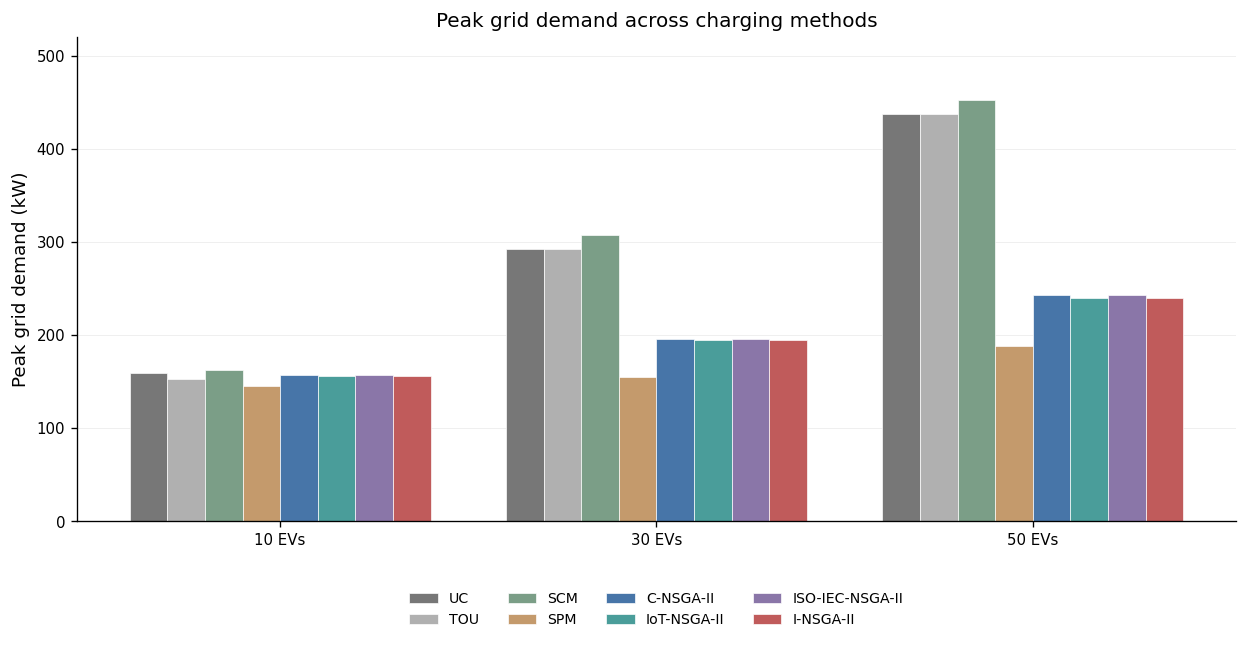


GENERATING FIGURE 2
Saved: /content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19/Figure19_2_Charging_Cost.jpg


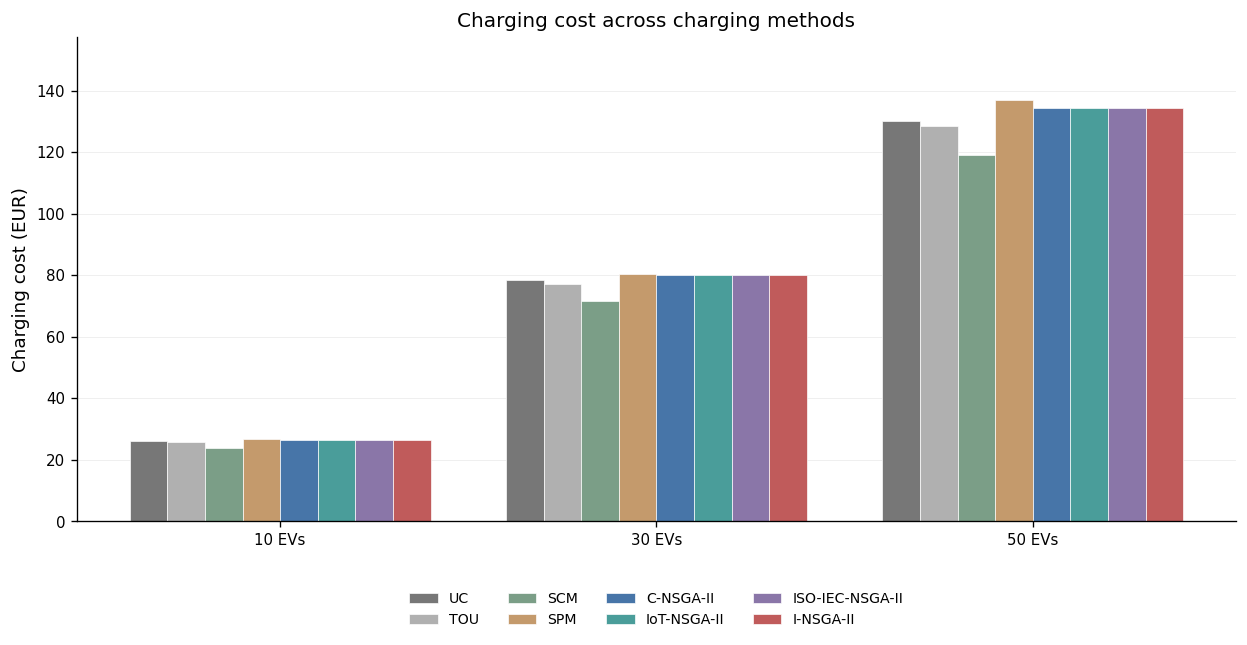


GENERATING FIGURE 3
Saved: /content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19/Figure19_3_Peak_Reduction_vs_UC.jpg


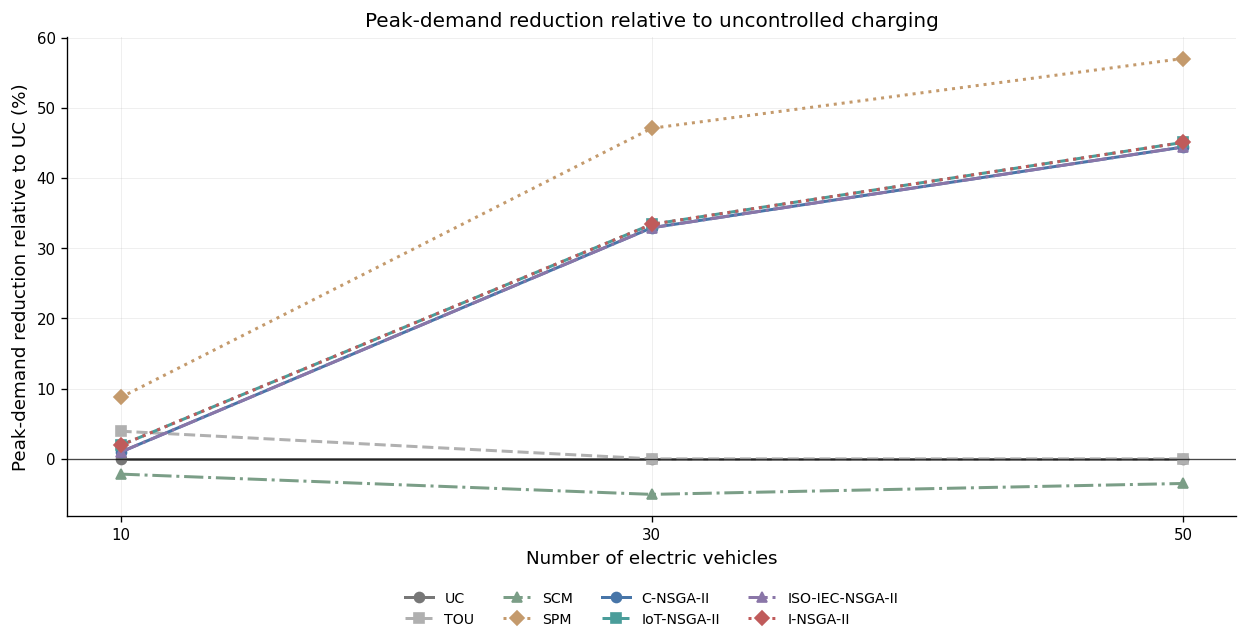


GENERATING FIGURE 4
Saved: /content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19/Figure19_4_NSGA_Hypervolume.jpg


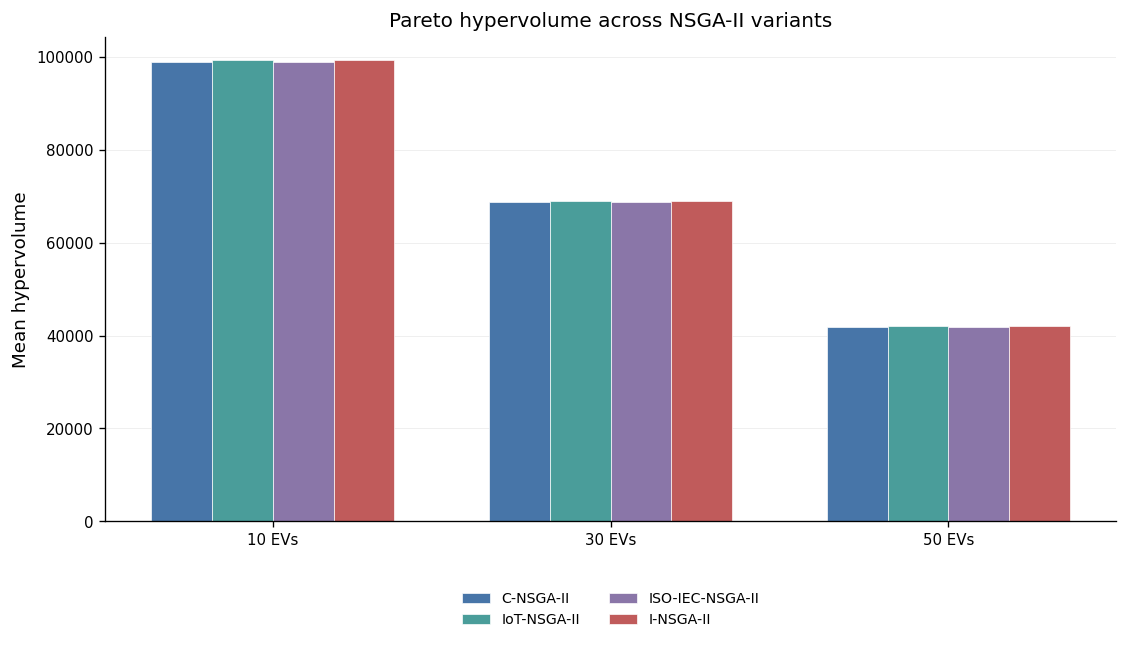


GENERATING FIGURE 5
Saved: /content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19/Figure19_5_Statistical_Peak_Improvement.jpg


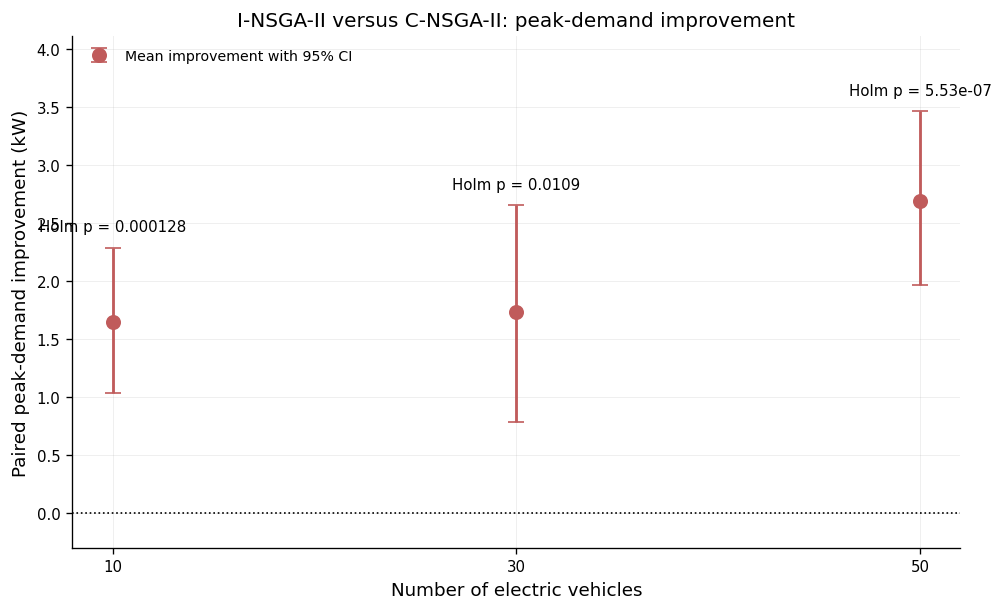


GENERATING FIGURE 6
Saved: /content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19/Figure19_6_Peak_Cost_Tradeoff.jpg


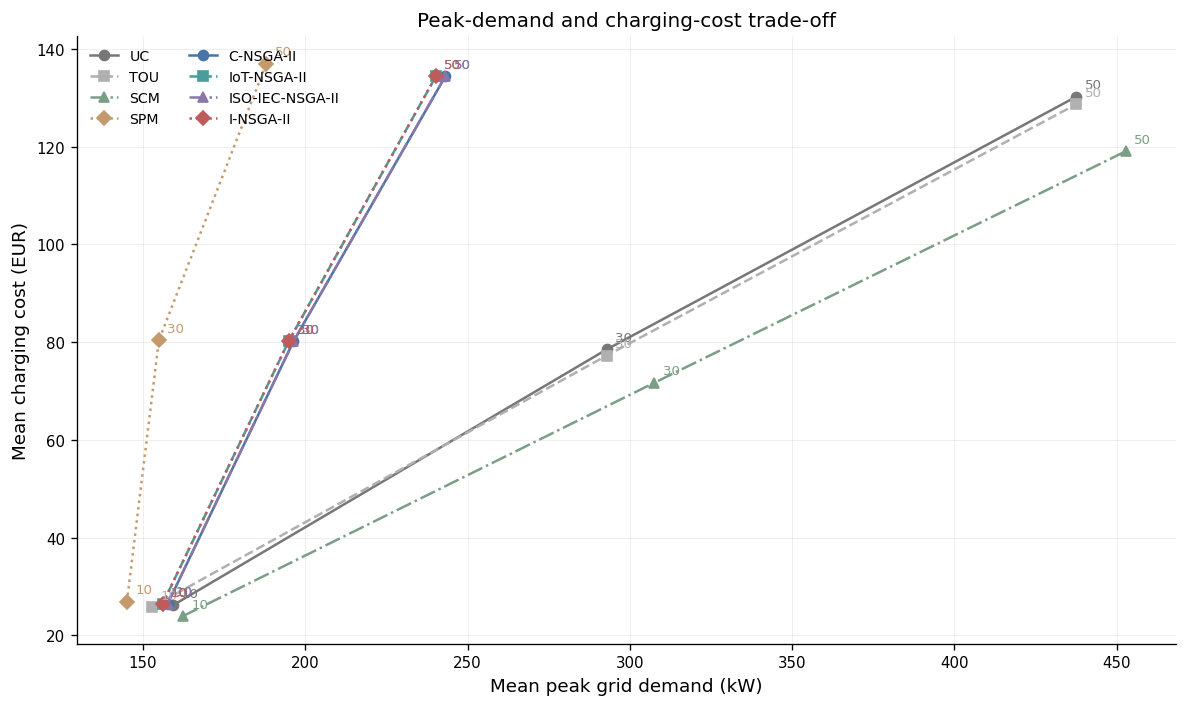


VALIDATING GENERATED FIGURES
                                   filename format  width_px  height_px  dpi_x  dpi_y  size_kb
            Figure19_1_Peak_Grid_Demand.jpg   JPEG      3120       1611  300.0  300.0   261.73
               Figure19_2_Charging_Cost.jpg   JPEG      3120       1611  300.0  300.0   269.78
        Figure19_3_Peak_Reduction_vs_UC.jpg   JPEG      3119       1609  300.0  300.0   360.94
            Figure19_4_NSGA_Hypervolume.jpg   JPEG      2820       1611  300.0  300.0   243.20
Figure19_5_Statistical_Peak_Improvement.jpg   JPEG      2508       1528  300.0  300.0   240.52
          Figure19_6_Peak_Cost_Tradeoff.jpg   JPEG      2970       1768  300.0  300.0   377.21

STEP 19 FINAL SUMMARY
Figures generated: 6
Format: JPG
Resolution: 300 DPI

Output directory:
/content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19

Execution time (seconds):
8.536

STEP 19 COMPLETED SUCCESSFULLY


In [ ]:

# ============================================================
# STEP 19: PUBLICATION-QUALITY PERFORMANCE FIGURES
# ============================================================
#
# Project: IOEV Ablation Study
# Target journal: Scientific Reports
#
# Figures:
# 1. Peak grid demand
# 2. Charging cost
# 3. Peak-demand reduction versus UC
# 4. NSGA-II hypervolume
# 5. Statistical improvement with 95% CI
# 6. Peak-cost trade-off
#
# All figures:
# JPG format
# 300 DPI
# Clean scientific presentation
#
# Uses saved Steps 16, 17 and 18
# No optimization reruns
# ============================================================

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

print("=" * 75)
print("STEP 19: PUBLICATION-QUALITY FIGURES")
print("=" * 75)

START_TIME = time.perf_counter()

# ============================================================
# 1. PATHS AND CONFIGURATION
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

RESULTS = ROOT / "Results"

STEP16 = RESULTS / "Step16_Full_Ablation"
STEP17 = RESULTS / "Step17_Comparison"
STEP18 = RESULTS / "Step18_Statistics"

FIGURES = ROOT / "Figures" / "Step19"

FIGURES.mkdir(
    parents=True,
    exist_ok=True
)

EV_COUNTS = [10, 30, 50]

BASELINES = [
    "UC", "TOU", "SCM", "SPM"
]

VARIANTS = [
    "C-NSGA-II",
    "IoT-NSGA-II",
    "ISO-IEC-NSGA-II",
    "I-NSGA-II"
]

METHODS = BASELINES + VARIANTS

SHORT_NAMES = {
    "UC": "UC",
    "TOU": "TOU",
    "SCM": "SCM",
    "SPM": "SPM",
    "C-NSGA-II": "C-NSGA-II",
    "IoT-NSGA-II": "IoT-NSGA-II",
    "ISO-IEC-NSGA-II": "ISO-IEC-NSGA-II",
    "I-NSGA-II": "I-NSGA-II"
}

# Consistent colors across figures.
# Restrained palette for publication.

COLORS = {
    "UC": "#777777",
    "TOU": "#B0B0B0",
    "SCM": "#7B9E87",
    "SPM": "#C49A6C",
    "C-NSGA-II": "#4775A8",
    "IoT-NSGA-II": "#4A9D9A",
    "ISO-IEC-NSGA-II": "#8A76A8",
    "I-NSGA-II": "#C05B5B"
}

MARKERS = {
    "UC": "o",
    "TOU": "s",
    "SCM": "^",
    "SPM": "D",
    "C-NSGA-II": "o",
    "IoT-NSGA-II": "s",
    "ISO-IEC-NSGA-II": "^",
    "I-NSGA-II": "D"
}

LINESTYLES = {
    "UC": "-",
    "TOU": "--",
    "SCM": "-.",
    "SPM": ":",
    "C-NSGA-II": "-",
    "IoT-NSGA-II": "--",
    "ISO-IEC-NSGA-II": "-.",
    "I-NSGA-II": ":"
}

DPI = 300
FORMAT = "jpg"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 8.5,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 0.8,
    "savefig.dpi": DPI,
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False
})

def save_figure(fig, filename):
    path = FIGURES / filename

    fig.savefig(
        path,
        dpi=DPI,
        format=FORMAT,
        bbox_inches="tight",
        facecolor="white",
        pil_kwargs={"quality": 95}
    )

    print("Saved:", path)

    plt.show()
    plt.close(fig)

    return str(path)

saved_files = []

# ============================================================
# 2. LOAD SAVED EXPERIMENTAL RESULTS
# ============================================================

print("\nLOADING SAVED RESULTS")

individual = pd.read_csv(
    STEP16 / "Step16_Individual_Results.csv"
)

combined = pd.read_csv(
    STEP17 / "Step17_All_Method_Results.csv"
)

paired = pd.read_csv(
    STEP17 / "Step17_Paired_Baseline_Comparisons.csv"
)

primary = pd.read_csv(
    STEP18 / "Step18_Primary_Ablation_Statistics.csv"
)

secondary = pd.read_csv(
    STEP18 / "Step18_Secondary_Baseline_Statistics.csv"
)

assert len(individual) == 360
assert len(combined) == 1440
assert len(paired) == 4320
assert len(primary) == 9
assert len(secondary) == 24

# Use one operating point per method and scenario.
# Baselines use their saved schedules.
# NSGA-II variants use balanced Pareto solutions.

plot_data = combined[
    (
        (combined["method"].isin(BASELINES))
        & (combined["selection_policy"] == "baseline")
    )
    |
    (
        (combined["method"].isin(VARIANTS))
        & (combined["selection_policy"] == "balanced")
    )
].copy()

assert len(plot_data) == 720

assert not plot_data.duplicated(
    ["ev_count", "run_index", "method"]
).any()

summary = (
    plot_data.groupby(
        ["ev_count", "method"],
        as_index=False
    )
    .agg(
        mean_peak_kw=("peak_kw", "mean"),
        std_peak_kw=("peak_kw", "std"),
        mean_cost_eur=("cost_eur", "mean"),
        std_cost_eur=("cost_eur", "std")
    )
)

print("Plotting records:", len(plot_data))
print("Methods:", len(METHODS))
print("EV populations:", EV_COUNTS)

# ============================================================
# 3. FIGURE 1: PEAK GRID DEMAND
# ============================================================

print("\nGENERATING FIGURE 1")

fig, ax = plt.subplots(
    figsize=(10.5, 5.5)
)

x = np.arange(len(EV_COUNTS))

width = 0.10

for i, method in enumerate(METHODS):

    subset = (
        summary[
            summary["method"] == method
        ]
        .set_index("ev_count")
        .reindex(EV_COUNTS)
    )

    positions = (
        x + (i - 3.5) * width
    )

    ax.bar(
        positions,
        subset["mean_peak_kw"],
        width=width,
        color=COLORS[method],
        label=SHORT_NAMES[method],
        edgecolor="white",
        linewidth=0.4
    )

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{n} EVs" for n in EV_COUNTS]
)

ax.set_ylabel(
    "Peak grid demand (kW)"
)

ax.set_title(
    "Peak grid demand across charging methods"
)

ax.set_ylim(
    0,
    summary["mean_peak_kw"].max() * 1.15
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

ax.legend(
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False
)

fig.tight_layout()

saved_files.append(
    save_figure(
        fig,
        "Figure19_1_Peak_Grid_Demand.jpg"
    )
)

# ============================================================
# 4. FIGURE 2: CHARGING COST
# ============================================================

print("\nGENERATING FIGURE 2")

fig, ax = plt.subplots(
    figsize=(10.5, 5.5)
)

for i, method in enumerate(METHODS):

    subset = (
        summary[
            summary["method"] == method
        ]
        .set_index("ev_count")
        .reindex(EV_COUNTS)
    )

    positions = (
        x + (i - 3.5) * width
    )

    ax.bar(
        positions,
        subset["mean_cost_eur"],
        width=width,
        color=COLORS[method],
        label=SHORT_NAMES[method],
        edgecolor="white",
        linewidth=0.4
    )

ax.set_xticks(x)

ax.set_xticklabels(
    [f"{n} EVs" for n in EV_COUNTS]
)

ax.set_ylabel(
    "Charging cost (EUR)"
)

ax.set_title(
    "Charging cost across charging methods"
)

ax.set_ylim(
    0,
    summary["mean_cost_eur"].max() * 1.15
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

ax.legend(
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False
)

fig.tight_layout()

saved_files.append(
    save_figure(
        fig,
        "Figure19_2_Charging_Cost.jpg"
    )
)

# ============================================================
# 5. FIGURE 3: PEAK REDUCTION RELATIVE TO UC
# ============================================================

print("\nGENERATING FIGURE 3")

uc_reference = plot_data[
    plot_data["method"] == "UC"
][
    ["ev_count", "run_index", "peak_kw"]
].rename(
    columns={
        "peak_kw": "uc_peak_kw"
    }
)

matched_uc = plot_data.merge(
    uc_reference,
    on=["ev_count", "run_index"],
    how="inner",
    validate="many_to_one"
)

assert len(matched_uc) == 720

matched_uc["peak_reduction_pct"] = (
    100.0
    * (
        matched_uc["uc_peak_kw"]
        - matched_uc["peak_kw"]
    )
    / matched_uc["uc_peak_kw"]
)

reduction_summary = (
    matched_uc.groupby(
        ["ev_count", "method"],
        as_index=False
    )
    .agg(
        mean_reduction_pct=(
            "peak_reduction_pct", "mean"
        ),
        std_reduction_pct=(
            "peak_reduction_pct", "std"
        )
    )
)

fig, ax = plt.subplots(
    figsize=(10.5, 5.5)
)

for method in METHODS:

    subset = (
        reduction_summary[
            reduction_summary["method"] == method
        ]
        .set_index("ev_count")
        .reindex(EV_COUNTS)
    )

    ax.plot(
        EV_COUNTS,
        subset["mean_reduction_pct"],
        marker=MARKERS[method],
        linestyle=LINESTYLES[method],
        color=COLORS[method],
        linewidth=1.8,
        markersize=6,
        label=SHORT_NAMES[method]
    )

ax.axhline(
    0,
    color="black",
    linewidth=0.8,
    alpha=0.7
)

ax.set_xticks(EV_COUNTS)

ax.set_xlabel(
    "Number of electric vehicles"
)

ax.set_ylabel(
    "Peak-demand reduction relative to UC (%)"
)

ax.set_title(
    "Peak-demand reduction relative to uncontrolled charging"
)

ax.grid(
    alpha=0.20,
    linewidth=0.6
)

ax.legend(
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    frameon=False
)

fig.tight_layout()

saved_files.append(
    save_figure(
        fig,
        "Figure19_3_Peak_Reduction_vs_UC.jpg"
    )
)

# ============================================================
# 6. FIGURE 4: NSGA-II HYPERVOLUME
# ============================================================

print("\nGENERATING FIGURE 4")

hv_summary = (
    individual.groupby(
        ["ev_count", "variant"],
        as_index=False
    )
    .agg(
        mean_hv=(
            "actual_hypervolume", "mean"
        ),
        std_hv=(
            "actual_hypervolume", "std"
        )
    )
)

fig, ax = plt.subplots(
    figsize=(9.5, 5.5)
)

hv_width = 0.18

for i, variant in enumerate(VARIANTS):

    subset = (
        hv_summary[
            hv_summary["variant"] == variant
        ]
        .set_index("ev_count")
        .reindex(EV_COUNTS)
    )

    positions = (
        x + (i - 1.5) * hv_width
    )

    ax.bar(
        positions,
        subset["mean_hv"],
        width=hv_width,
        color=COLORS[variant],
        label=variant,
        edgecolor="white",
        linewidth=0.4
    )

ax.set_xticks(x)

ax.set_xticklabels(
    [f"{n} EVs" for n in EV_COUNTS]
)

ax.set_ylabel(
    "Mean hypervolume"
)

ax.set_title(
    "Pareto hypervolume across NSGA-II variants"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

ax.legend(
    ncol=2,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False
)

fig.tight_layout()

saved_files.append(
    save_figure(
        fig,
        "Figure19_4_NSGA_Hypervolume.jpg"
    )
)

# ============================================================
# 7. FIGURE 5: STATISTICAL PEAK IMPROVEMENT
# ============================================================

print("\nGENERATING FIGURE 5")

peak_stats = (
    primary[
        primary["metric"] == "peak_kw"
    ]
    .sort_values("ev_count")
    .copy()
)

assert len(peak_stats) == 3

means = peak_stats[
    "mean_improvement"
].to_numpy()

lower = peak_stats[
    "ci95_low"
].to_numpy()

upper = peak_stats[
    "ci95_high"
].to_numpy()

errors = np.vstack([
    means - lower,
    upper - means
])

fig, ax = plt.subplots(
    figsize=(8.5, 5.2)
)

ax.errorbar(
    EV_COUNTS,
    means,
    yerr=errors,
    fmt="o",
    markersize=8,
    linewidth=1.7,
    capsize=5,
    color=COLORS["I-NSGA-II"],
    ecolor=COLORS["I-NSGA-II"],
    label="Mean improvement with 95% CI"
)

ax.axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=1
)

for i, row in peak_stats.reset_index(
    drop=True
).iterrows():

    label = (
        f"Holm p = {row['p_holm']:.3g}"
    )

    ax.annotate(
        label,
        (
            row["ev_count"],
            row["ci95_high"]
        ),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_xticks(EV_COUNTS)

ax.set_xlabel(
    "Number of electric vehicles"
)

ax.set_ylabel(
    "Paired peak-demand improvement (kW)"
)

ax.set_title(
    "I-NSGA-II versus C-NSGA-II: peak-demand improvement"
)

ax.set_ylim(
    bottom=min(
        -0.3,
        lower.min() - 0.3
    ),
    top=upper.max() + 0.65
)

ax.grid(
    alpha=0.20,
    linewidth=0.6
)

ax.legend(
    loc="upper left",
    frameon=False
)

fig.tight_layout()

saved_files.append(
    save_figure(
        fig,
        "Figure19_5_Statistical_Peak_Improvement.jpg"
    )
)

# ============================================================
# 8. FIGURE 6: PEAK-COST TRADE-OFF
# ============================================================

print("\nGENERATING FIGURE 6")

fig, ax = plt.subplots(
    figsize=(10, 6)
)

for method in METHODS:

    subset = (
        summary[
            summary["method"] == method
        ]
        .set_index("ev_count")
        .reindex(EV_COUNTS)
    )

    ax.plot(
        subset["mean_peak_kw"],
        subset["mean_cost_eur"],
        marker=MARKERS[method],
        linestyle=LINESTYLES[method],
        linewidth=1.5,
        markersize=6,
        color=COLORS[method],
        label=SHORT_NAMES[method]
    )

    for ev_count in EV_COUNTS:

        row = subset.loc[ev_count]

        ax.annotate(
            str(ev_count),
            (
                row["mean_peak_kw"],
                row["mean_cost_eur"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8,
            color=COLORS[method]
        )

ax.set_xlabel(
    "Mean peak grid demand (kW)"
)

ax.set_ylabel(
    "Mean charging cost (EUR)"
)

ax.set_title(
    "Peak-demand and charging-cost trade-off"
)

ax.grid(
    alpha=0.20,
    linewidth=0.6
)

ax.legend(
    ncol=2,
    loc="upper left",
    frameon=False
)

fig.tight_layout()

saved_files.append(
    save_figure(
        fig,
        "Figure19_6_Peak_Cost_Tradeoff.jpg"
    )
)

# ============================================================
# 9. VALIDATE FIGURE OUTPUTS
# ============================================================

print("\n" + "=" * 75)
print("VALIDATING GENERATED FIGURES")
print("=" * 75)

from PIL import Image

validation_rows = []

for path_string in saved_files:

    path = Path(path_string)

    if not path.exists():
        raise FileNotFoundError(path)

    with Image.open(path) as img:

        dpi_info = img.info.get(
            "dpi", (0, 0)
        )

        width_px, height_px = img.size

        validation_rows.append({
            "filename": path.name,
            "format": img.format,
            "width_px": width_px,
            "height_px": height_px,
            "dpi_x": float(dpi_info[0]),
            "dpi_y": float(dpi_info[1]),
            "size_kb": round(
                path.stat().st_size / 1024,
                2
            )
        })

validation = pd.DataFrame(
    validation_rows
)

assert len(validation) == 6

assert (
    validation["format"] == "JPEG"
).all()

assert (
    validation["dpi_x"] >= 299
).all()

assert (
    validation["dpi_y"] >= 299
).all()

validation_path = (
    FIGURES / "Step19_Figure_Validation.csv"
)

validation.to_csv(
    validation_path,
    index=False
)

print(
    validation.to_string(index=False)
)

# ============================================================
# 10. SAVE FIGURE MANIFEST
# ============================================================

manifest = {
    "step": 19,
    "status": "complete",
    "target_journal": "Scientific Reports",
    "figure_format": "JPG",
    "figure_dpi": DPI,
    "number_of_figures": len(saved_files),
    "ev_counts": EV_COUNTS,
    "baseline_methods": BASELINES,
    "nsga_variants": VARIANTS,
    "nsga_selection_policy": "balanced",
    "hypervolume_source": (
        "Step16_Individual_Results.csv"
    ),
    "statistical_source": (
        "Step18_Primary_Ablation_Statistics.csv"
    ),
    "figures": saved_files,
    "notes": [
        "Baseline curves use the saved baseline schedules.",
        "NSGA-II curves use balanced Pareto solutions.",
        "Hypervolume values are taken directly "
        "from Step 16.",
        "Confidence intervals are taken directly "
        "from Step 18.",
        "Identical ablation variants are retained "
        "without modifying their results.",
        "Figure 6 connects population-level means "
        "for visual comparison and does not "
        "represent a single Pareto front."
    ]
}

manifest_path = (
    FIGURES / "Step19_Figure_Manifest.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        manifest,
        file,
        indent=2
    )

# ============================================================
# 11. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 19 FINAL SUMMARY")
print("=" * 75)

print("Figures generated:", len(saved_files))
print("Format: JPG")
print("Resolution: 300 DPI")

print("\nOutput directory:")
print(FIGURES)

print("\nExecution time (seconds):")
print(
    round(
        time.perf_counter() - START_TIME,
        3
    )
)

print("\n" + "=" * 75)
print("STEP 19 COMPLETED SUCCESSFULLY")
print("=" * 75)


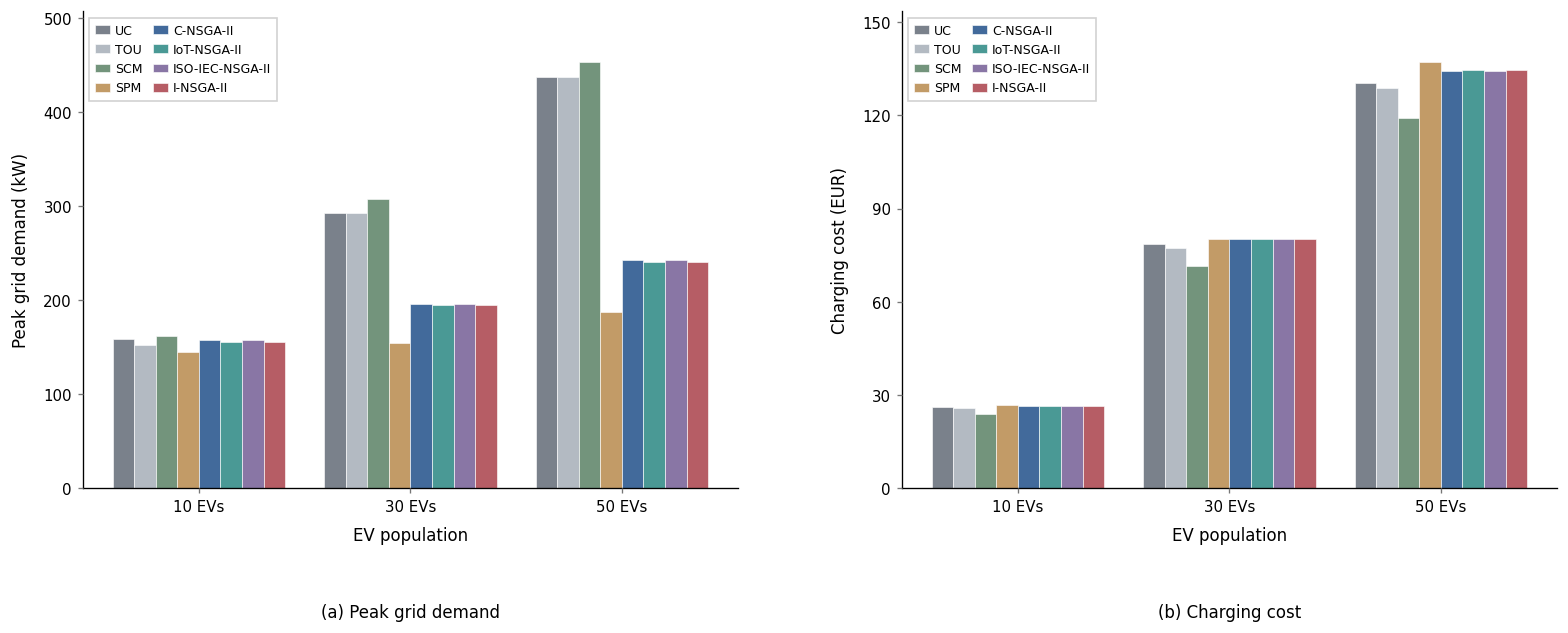

STEP 19A COMPLETED
Figure: /content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19/Figure19A_Peak_Demand_and_Charging_Cost.jpg
Dimensions: (3919, 1581)
DPI: (300, 300)
Optimization runs performed: 0


In [ ]:

# ============================================================
# STEP 19A: REVISED TWO-PANEL FIGURE
# No grid lines
# Individual upper-left legends
# Normal-weight panel labels
# ============================================================

from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(
    1, 2,
    figsize=(13.5, 5.6),
    sharex=True
)

x = np.arange(len(ev_counts))
bar_width = 0.102

metrics = [
    ("peak_kw", "Peak grid demand (kW)"),
    ("cost_eur", "Charging cost (EUR)")
]

for ax, (metric, ylabel) in zip(axes, metrics):

    for i, method in enumerate(methods):

        subset = (
            summary[summary["method"].eq(method)]
            .set_index("ev_count")
            .reindex(ev_counts)
        )

        if subset[metric].isna().any():
            raise RuntimeError(
                f"Missing values for {method}"
            )

        offsets = x + (i - 3.5) * bar_width

        ax.bar(
            offsets,
            subset[metric].to_numpy(),
            width=bar_width,
            color=colors[method],
            label=method,
            edgecolor="white",
            linewidth=0.35,
            zorder=2
        )

    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{n} EVs" for n in ev_counts]
    )

    ax.set_ylabel(ylabel, labelpad=8)
    ax.set_xlabel("EV population", labelpad=7)

    ax.set_ylim(
        0,
        summary[metric].max() * 1.12
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=6)
    )

    # Remove all grid lines
    ax.grid(False)
    ax.set_axisbelow(False)

    ax.tick_params(
        axis="both",
        length=3,
        color="#777777"
    )

    # Separate legend inside each plot
    ax.legend(
        loc="upper left",
        ncol=2,
        fontsize=7.5,
        frameon=True,
        fancybox=False,
        framealpha=0.95,
        facecolor="white",
        edgecolor="#D0D0D0",
        borderpad=0.5,
        columnspacing=0.8,
        handlelength=1.2,
        handletextpad=0.4
    )

# Panel labels below the x-axes, normal font

axes[0].text(
    0.5, -0.24,
    "(a) Peak grid demand",
    transform=axes[0].transAxes,
    ha="center",
    va="top",
    fontsize=10,
    fontweight="normal"
)

axes[1].text(
    0.5, -0.24,
    "(b) Charging cost",
    transform=axes[1].transAxes,
    ha="center",
    va="top",
    fontsize=10,
    fontweight="normal"
)

fig.subplots_adjust(
    left=0.075,
    right=0.985,
    top=0.96,
    bottom=0.25,
    wspace=0.25
)

# Save 300 DPI JPG

output_file = OUTPUT / \
    "Figure19A_Peak_Demand_and_Charging_Cost.jpg"

fig.savefig(
    output_file,
    format="jpg",
    dpi=300,
    facecolor="white",
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

plt.show()
plt.close(fig)

# Validate output

with Image.open(output_file) as image:
    dpi = image.info.get("dpi", (0, 0))
    dimensions = image.size

    if min(dpi) < 299:
        raise RuntimeError(
            "Figure DPI validation failed."
        )

print("=" * 65)
print("STEP 19A COMPLETED")
print("=" * 65)
print("Figure:", output_file)
print("Dimensions:", dimensions)
print("DPI:", dpi)
print("Optimization runs performed: 0")


STEP 19B: STATISTICAL PERFORMANCE COMPARISON

Statistical records validated: 6


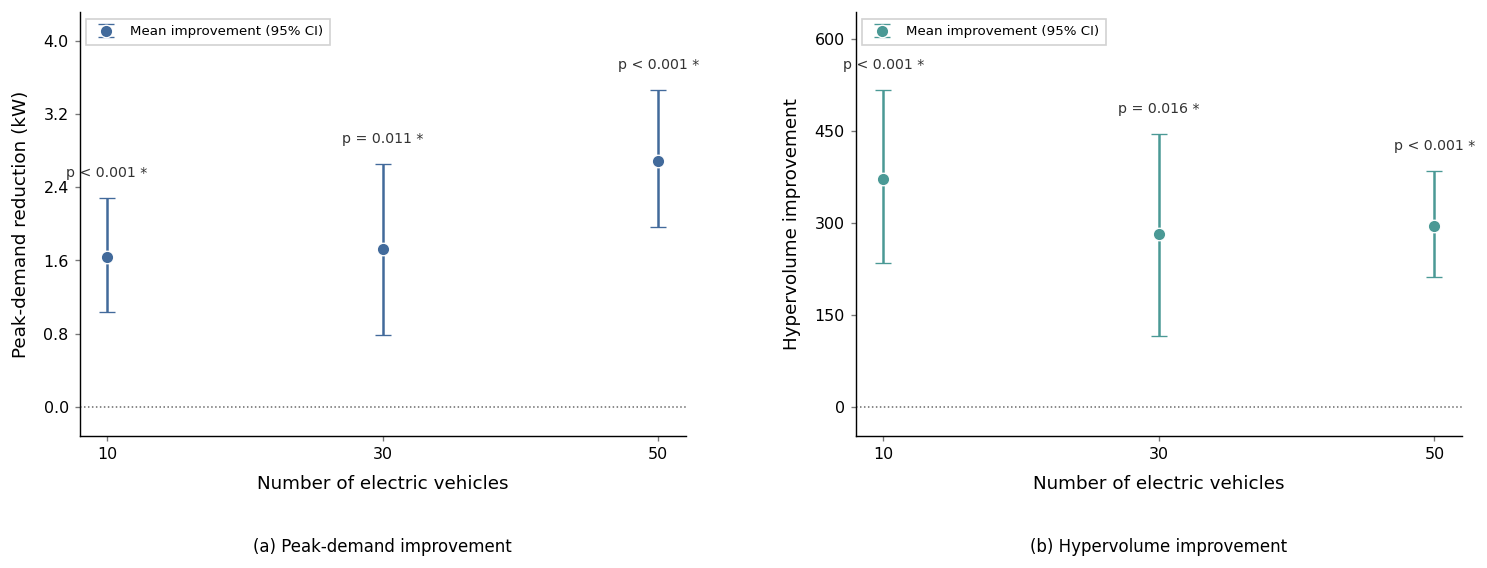


STEP 19B COMPLETED SUCCESSFULLY
Statistical records: 6
Output: /content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19/Figure19B_Statistical_Improvements.jpg
Image dimensions: (3718, 1417)
Resolution: (300, 300)
Optimization runs performed: 0


In [ ]:

# ============================================================
# STEP 19B: STATISTICAL PERFORMANCE COMPARISON
# ============================================================
# Scientific Reports
#
# (a) Peak-demand improvement with 95% CI
# (b) Hypervolume improvement with 95% CI
#
# Two plots side by side
# Individual legends in upper-left corners
# No grid lines
# Normal-weight panel labels
# JPG, 300 DPI
#
# Source: Step 18 saved statistical results
# No optimization reruns
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import MaxNLocator
from PIL import Image

print("=" * 75)
print("STEP 19B: STATISTICAL PERFORMANCE COMPARISON")
print("=" * 75)

# ============================================================
# 1. FILE PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

SOURCE = (
    ROOT / "Results" /
    "Step18_Statistics" /
    "Step18_Primary_Ablation_Statistics.csv"
)

OUTPUT = (
    ROOT / "Figures" /
    "Step19"
)

OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

if not SOURCE.exists():
    raise FileNotFoundError(
        f"Step 18 statistics not found: {SOURCE}"
    )

# ============================================================
# 2. LOAD AND VALIDATE STATISTICAL RESULTS
# ============================================================

df = pd.read_csv(SOURCE)

required_columns = {
    "ev_count",
    "metric",
    "mean_improvement",
    "ci95_low",
    "ci95_high",
    "p_holm",
    "significant_0_05"
}

missing = required_columns.difference(df.columns)

if missing:
    raise ValueError(
        f"Missing required columns: {sorted(missing)}"
    )

EV_COUNTS = [10, 30, 50]

METRICS = [
    "peak_kw",
    "hypervolume"
]

data = df[
    df["metric"].isin(METRICS)
].copy()

if len(data) != 6:
    raise RuntimeError(
        "Expected six statistical records."
    )

if data.duplicated(
    ["ev_count", "metric"]
).any():
    raise RuntimeError(
        "Duplicate statistical records detected."
    )

expected = pd.MultiIndex.from_product(
    [EV_COUNTS, METRICS],
    names=["ev_count", "metric"]
)

actual = pd.MultiIndex.from_frame(
    data[["ev_count", "metric"]]
)

if not expected.sort_values().equals(
    actual.sort_values()
):
    raise RuntimeError(
        "Missing or unexpected EV-metric combinations."
    )

numeric_cols = [
    "mean_improvement",
    "ci95_low",
    "ci95_high",
    "p_holm"
]

if not np.isfinite(
    data[numeric_cols].to_numpy(dtype=float)
).all():
    raise RuntimeError(
        "Non-finite statistical results detected."
    )

if not (
    (data["ci95_low"] <= data["mean_improvement"])
    &
    (data["mean_improvement"] <= data["ci95_high"])
).all():
    raise RuntimeError(
        "Invalid confidence interval detected."
    )

print("\nStatistical records validated:", len(data))

# ============================================================
# 3. PUBLICATION FIGURE SETTINGS
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 8.5,
    "axes.linewidth": 0.85,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False
})

COLORS = {
    "peak_kw": "#426A9B",
    "hypervolume": "#4A9995"
}

# ============================================================
# 4. CREATE SIDE-BY-SIDE FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.8, 5.2)
)

PLOT_CONFIG = [
    {
        "metric": "peak_kw",
        "ylabel": "Peak-demand reduction (kW)",
        "panel": "(a) Peak-demand improvement",
        "color": COLORS["peak_kw"]
    },
    {
        "metric": "hypervolume",
        "ylabel": "Hypervolume improvement",
        "panel": "(b) Hypervolume improvement",
        "color": COLORS["hypervolume"]
    }
]

for ax, config in zip(axes, PLOT_CONFIG):

    subset = (
        data[
            data["metric"] == config["metric"]
        ]
        .set_index("ev_count")
        .reindex(EV_COUNTS)
    )

    means = subset[
        "mean_improvement"
    ].to_numpy(dtype=float)

    lower = subset[
        "ci95_low"
    ].to_numpy(dtype=float)

    upper = subset[
        "ci95_high"
    ].to_numpy(dtype=float)

    p_values = subset[
        "p_holm"
    ].to_numpy(dtype=float)

    significance = (
        subset["significant_0_05"]
        .astype(str)
        .str.lower()
        .eq("true")
        .to_numpy()
    )

    yerr = np.vstack([
        means - lower,
        upper - means
    ])

    # Mean improvement with bootstrap 95% CI

    ax.errorbar(
        EV_COUNTS,
        means,
        yerr=yerr,
        fmt="o",
        markersize=7.5,
        linewidth=1.8,
        elinewidth=1.5,
        capsize=5,
        capthick=1.4,
        color=config["color"],
        ecolor=config["color"],
        markerfacecolor=config["color"],
        markeredgecolor="white",
        markeredgewidth=0.8,
        label="Mean improvement (95% CI)",
        zorder=3
    )

    # Zero-improvement reference line

    ax.axhline(
        0,
        color="#666666",
        linestyle=":",
        linewidth=0.9,
        zorder=1
    )

    # Statistical significance annotations

    for ev_count, mean, high, p, sig in zip(
        EV_COUNTS,
        means,
        upper,
        p_values,
        significance
    ):

        if p < 0.001:
            p_label = "p < 0.001"
        else:
            p_label = f"p = {p:.3f}"

        if sig:
            p_label += " *"

        ax.annotate(
            p_label,
            xy=(ev_count, high),
            xytext=(0, 11),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8.5,
            color="#333333"
        )

    # Axes

    ax.set_xticks(EV_COUNTS)

    ax.set_xticklabels(
        [str(n) for n in EV_COUNTS]
    )

    ax.set_xlabel(
        "Number of electric vehicles",
        labelpad=8
    )

    ax.set_ylabel(
        config["ylabel"],
        labelpad=8
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=6)
    )

    # Set readable y-axis limits

    span = max(
        float(upper.max() - lower.min()),
        1e-9
    )

    ax.set_ylim(
        min(0, float(lower.min())) - 0.12 * span,
        float(upper.max()) + 0.32 * span
    )

    # No grid lines

    ax.grid(False)

    ax.tick_params(
        axis="both",
        length=3,
        color="#777777"
    )

    # Separate upper-left legend

    ax.legend(
        loc="upper left",
        frameon=True,
        fancybox=False,
        framealpha=0.95,
        facecolor="white",
        edgecolor="#D0D0D0",
        fontsize=8,
        borderpad=0.5
    )

    # Panel labels below x-axis

    ax.text(
        0.5,
        -0.24,
        config["panel"],
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=10,
        fontweight="normal"
    )

# ============================================================
# 5. LAYOUT
# ============================================================

fig.subplots_adjust(
    left=0.085,
    right=0.985,
    top=0.94,
    bottom=0.26,
    wspace=0.28
)

# ============================================================
# 6. SAVE FIGURE
# ============================================================

OUTPUT_FILE = (
    OUTPUT /
    "Figure19B_Statistical_Improvements.jpg"
)

fig.savefig(
    OUTPUT_FILE,
    format="jpg",
    dpi=300,
    facecolor="white",
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

plt.show()
plt.close(fig)

# ============================================================
# 7. VALIDATE OUTPUT
# ============================================================

with Image.open(OUTPUT_FILE) as image:

    dpi = image.info.get(
        "dpi",
        (0, 0)
    )

    dimensions = image.size

    if min(dpi) < 299:
        raise RuntimeError(
            "Figure DPI validation failed."
        )

print("\n" + "=" * 75)
print("STEP 19B COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Statistical records:", len(data))
print("Output:", OUTPUT_FILE)
print("Image dimensions:", dimensions)
print("Resolution:", dpi)
print("Optimization runs performed: 0")


STEP 19C: PARETO AND CONVERGENCE COMPARISON
Convergence metric: best_peak_kw
Generation column: generation
Representative scenario: 0


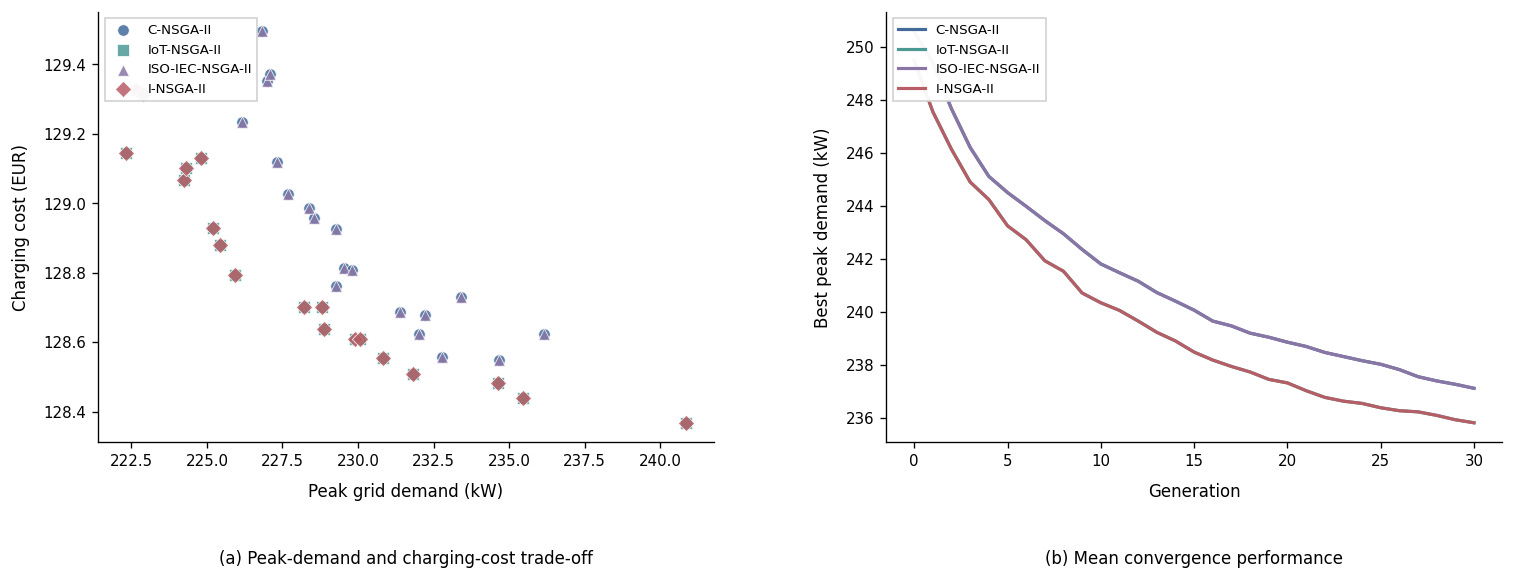


STEP 19C COMPLETED
Figure: /content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19/Figure19C_Pareto_and_Convergence.jpg
Image dimensions: (3781, 1447)
Resolution: (300, 300)
Convergence metric: best_peak_kw
Optimization runs performed: 0


In [ ]:

# ============================================================
# STEP 19C: PARETO FRONT AND CONVERGENCE PERFORMANCE
# ============================================================
# (a) Peak demand versus charging cost
# (b) Convergence across generations
# 50 EVs, representative scenario for panel (a)
# 30-run average for panel (b)
# JPG, 300 DPI, no grid lines
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

print("=" * 70)
print("STEP 19C: PARETO AND CONVERGENCE COMPARISON")
print("=" * 70)

# 1. Load saved results

ROOT = Path("/content/drive/MyDrive/IOEV_Ablation_Study")

SOURCE = ROOT / "Results" / "Step16_Full_Ablation"
OUTPUT = ROOT / "Figures" / "Step19"
OUTPUT.mkdir(parents=True, exist_ok=True)

pareto_file = SOURCE / "Step16_Pareto_Solutions.csv"
history_file = SOURCE / "Step16_Convergence_History.csv"

for file in [pareto_file, history_file]:
    if not file.exists():
        raise FileNotFoundError(file)

pareto = pd.read_csv(pareto_file)
history = pd.read_csv(history_file)

# 2. Validate source columns

pareto_required = {
    "ev_count", "run_index", "variant",
    "actual_peak_kw", "actual_cost_eur"
}

history_required = {
    "ev_count", "run_index", "variant"
}

if not pareto_required.issubset(pareto.columns):
    raise ValueError(
        f"Missing Pareto columns: "
        f"{sorted(pareto_required - set(pareto.columns))}"
    )

if not history_required.issubset(history.columns):
    raise ValueError(
        f"Missing history columns: "
        f"{sorted(history_required - set(history.columns))}"
    )

EV_COUNT = 50

VARIANTS = [
    "C-NSGA-II",
    "IoT-NSGA-II",
    "ISO-IEC-NSGA-II",
    "I-NSGA-II"
]

COLORS = {
    "C-NSGA-II": "#426A9B",
    "IoT-NSGA-II": "#4A9995",
    "ISO-IEC-NSGA-II": "#8976A5",
    "I-NSGA-II": "#B65D65"
}

MARKERS = {
    "C-NSGA-II": "o",
    "IoT-NSGA-II": "s",
    "ISO-IEC-NSGA-II": "^",
    "I-NSGA-II": "D"
}

# 3. Select a representative scenario
# Run index 0 is chosen in advance, not selected
# according to its performance.

SCENARIO_INDEX = 0

front = pareto.loc[
    (pareto["ev_count"] == EV_COUNT)
    & (pareto["run_index"] == SCENARIO_INDEX)
    & (pareto["variant"].isin(VARIANTS))
].copy()

if set(front["variant"]) != set(VARIANTS):
    raise RuntimeError(
        "Representative scenario is missing a variant."
    )

if not np.isfinite(
    front[["actual_peak_kw", "actual_cost_eur"]]
    .to_numpy(dtype=float)
).all():
    raise RuntimeError("Invalid Pareto objective values.")

# 4. Identify a valid convergence metric

history_50 = history.loc[
    (history["ev_count"] == EV_COUNT)
    & (history["variant"].isin(VARIANTS))
].copy()

generation_candidates = [
    "generation", "gen", "generation_index"
]

generation_col = next(
    (c for c in generation_candidates if c in history_50.columns),
    None
)

if generation_col is None:
    raise ValueError(
        "Cannot identify generation column. "
        f"Available columns: {list(history_50.columns)}"
    )

# Prefer hypervolume if it was recorded by Step 16.
# Do not calculate or invent missing convergence values.

metric_candidates = [
    ("hypervolume", "Hypervolume", "max"),
    ("actual_hypervolume", "Actual hypervolume", "max"),
    ("best_peak_kw", "Best peak demand (kW)", "min"),
    ("best_cost_eur", "Best charging cost (EUR)", "min"),
    ("best_f1", "Best first objective", "min"),
    ("best_f2", "Best second objective", "min")
]

chosen = next(
    (
        (column, label, direction)
        for column, label, direction in metric_candidates
        if column in history_50.columns
        and pd.api.types.is_numeric_dtype(history_50[column])
    ),
    None
)

if chosen is None:
    raise ValueError(
        "No recognized convergence metric found. "
        "Please share these history columns so the "
        "correct recorded metric can be selected: "
        f"{list(history_50.columns)}"
    )

metric_col, metric_label, direction = chosen

print("Convergence metric:", metric_col)
print("Generation column:", generation_col)
print("Representative scenario:", SCENARIO_INDEX)

# Validate the 30 paired runs for every variant.

expected_pairs = {
    (run, variant)
    for run in range(30)
    for variant in VARIANTS
}

actual_pairs = set(
    zip(history_50["run_index"], history_50["variant"])
)

if actual_pairs != expected_pairs:
    raise RuntimeError(
        "Convergence history does not contain "
        "all 30 runs for every variant."
    )

if not np.isfinite(
    history_50[[generation_col, metric_col]]
    .to_numpy(dtype=float)
).all():
    raise RuntimeError("Invalid convergence history values.")

# 5. Average convergence over independent runs

# First check that every run has one observation
# for each recorded generation.

if history_50.duplicated(
    ["run_index", "variant", generation_col]
).any():
    raise RuntimeError(
        "Duplicate generation records detected."
    )

generation_sets = history_50.groupby(
    ["run_index", "variant"]
)[generation_col].apply(
    lambda s: tuple(sorted(s.tolist()))
)

if generation_sets.nunique() != 1:
    raise RuntimeError(
        "Runs have different recorded generations."
    )

convergence = (
    history_50.groupby(
        ["variant", generation_col],
        as_index=False
    )
    .agg(
        mean_value=(metric_col, "mean"),
        std_value=(metric_col, "std"),
        n_runs=("run_index", "nunique")
    )
)

if not (convergence["n_runs"] == 30).all():
    raise RuntimeError(
        "Some convergence points have fewer than 30 runs."
    )

# 6. Publication style

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(13.0, 5.2)
)

# ============================================================
# PANEL (a): PARETO SOLUTIONS
# ============================================================

ax = axes[0]

for variant in VARIANTS:

    subset = front.loc[
        front["variant"] == variant
    ].sort_values("actual_peak_kw")

    ax.scatter(
        subset["actual_peak_kw"],
        subset["actual_cost_eur"],
        s=48,
        marker=MARKERS[variant],
        color=COLORS[variant],
        alpha=0.85,
        edgecolors="white",
        linewidths=0.5,
        label=variant,
        zorder=3
    )

ax.set_xlabel("Peak grid demand (kW)", labelpad=8)
ax.set_ylabel("Charging cost (EUR)", labelpad=8)

ax.grid(False)

ax.legend(
    loc="upper left",
    fontsize=8,
    frameon=True,
    fancybox=False,
    framealpha=0.95,
    facecolor="white",
    edgecolor="#D0D0D0"
)

ax.text(
    0.5, -0.25,
    "(a) Peak-demand and charging-cost trade-off",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    fontweight="normal"
)

# ============================================================
# PANEL (b): CONVERGENCE HISTORY
# ============================================================

ax = axes[1]

for variant in VARIANTS:

    subset = convergence.loc[
        convergence["variant"] == variant
    ].sort_values(generation_col)

    ax.plot(
        subset[generation_col],
        subset["mean_value"],
        color=COLORS[variant],
        linewidth=1.9,
        label=variant
    )

ax.set_xlabel("Generation", labelpad=8)
ax.set_ylabel(metric_label, labelpad=8)

ax.grid(False)

ax.legend(
    loc="upper left",
    fontsize=8,
    frameon=True,
    fancybox=False,
    framealpha=0.95,
    facecolor="white",
    edgecolor="#D0D0D0"
)

ax.text(
    0.5, -0.25,
    "(b) Mean convergence performance",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    fontweight="normal"
)

# 7. Layout and save

fig.subplots_adjust(
    left=0.085,
    right=0.985,
    top=0.95,
    bottom=0.26,
    wspace=0.28
)

output_file = (
    OUTPUT /
    "Figure19C_Pareto_and_Convergence.jpg"
)

fig.savefig(
    output_file,
    format="jpg",
    dpi=300,
    facecolor="white",
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

plt.show()
plt.close(fig)

# 8. Validate image

with Image.open(output_file) as image:
    dpi = image.info.get("dpi", (0, 0))
    dimensions = image.size

    if min(dpi) < 299:
        raise RuntimeError("DPI validation failed.")

print("\n" + "=" * 70)
print("STEP 19C COMPLETED")
print("=" * 70)
print("Figure:", output_file)
print("Image dimensions:", dimensions)
print("Resolution:", dpi)
print("Convergence metric:", metric_col)
print("Optimization runs performed: 0")


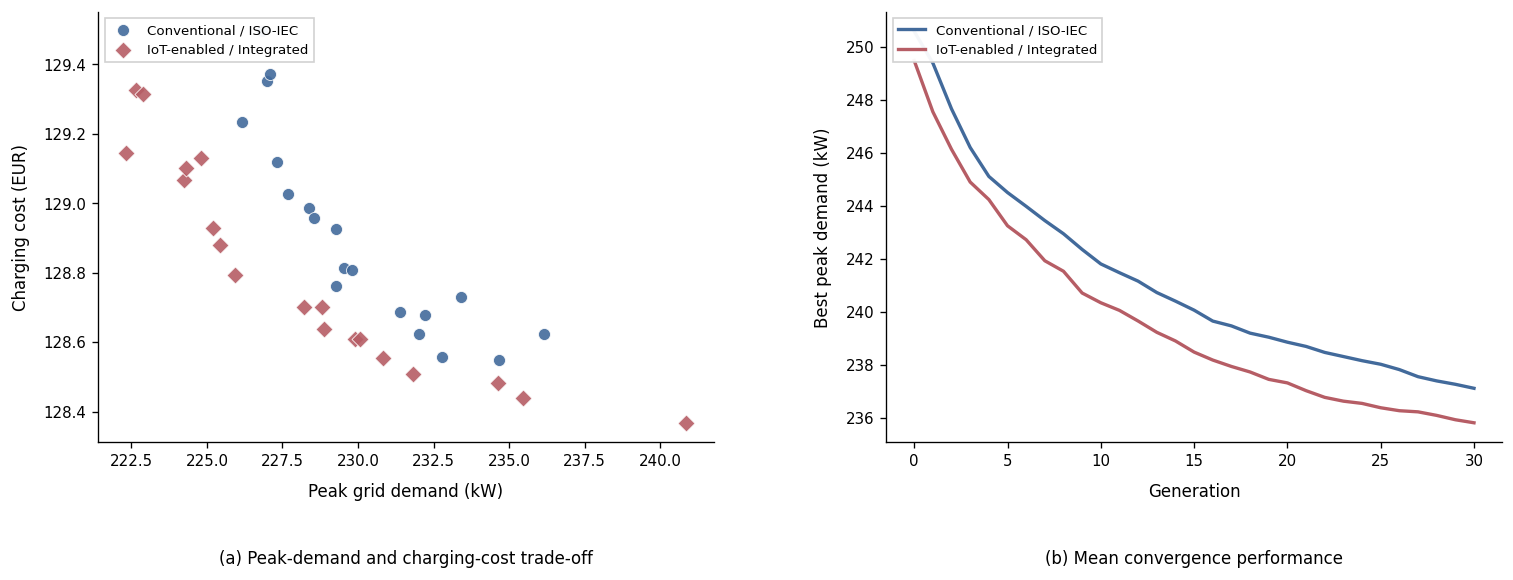

STEP 19C FINAL FIGURE SAVED
File: /content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19/Figure19C_Final_Pareto_and_Convergence.jpg
DPI: (300, 300)
Optimization runs performed: 0


In [ ]:

# ============================================================
# STEP 19C: FINAL TWO-GROUP FIGURE
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# The pairs were confirmed numerically equivalent in Step 18.
GROUPS = {
    "Conventional / ISO-IEC": "C-NSGA-II",
    "IoT-enabled / Integrated": "I-NSGA-II"
}

GROUP_COLORS = {
    "Conventional / ISO-IEC": "#426A9B",
    "IoT-enabled / Integrated": "#B65D65"
}

GROUP_MARKERS = {
    "Conventional / ISO-IEC": "o",
    "IoT-enabled / Integrated": "D"
}

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5.2)
)

# Panel (a): Pareto candidate solutions

ax = axes[0]

for label, variant in GROUPS.items():

    subset = (
        front[front["variant"] == variant]
        .sort_values("actual_peak_kw")
    )

    ax.scatter(
        subset["actual_peak_kw"],
        subset["actual_cost_eur"],
        s=52,
        marker=GROUP_MARKERS[label],
        color=GROUP_COLORS[label],
        alpha=0.9,
        edgecolors="white",
        linewidths=0.5,
        label=label
    )

ax.set_xlabel("Peak grid demand (kW)", labelpad=8)
ax.set_ylabel("Charging cost (EUR)", labelpad=8)
ax.grid(False)

ax.legend(
    loc="upper left",
    frameon=True,
    fancybox=False,
    framealpha=0.95,
    facecolor="white",
    edgecolor="#D0D0D0",
    fontsize=8
)

ax.text(
    0.5, -0.25,
    "(a) Peak-demand and charging-cost trade-off",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    fontweight="normal"
)

# Panel (b): Convergence history

ax = axes[1]

for label, variant in GROUPS.items():

    subset = (
        convergence[convergence["variant"] == variant]
        .sort_values(generation_col)
    )

    ax.plot(
        subset[generation_col],
        subset["mean_value"],
        color=GROUP_COLORS[label],
        linewidth=2,
        label=label
    )

ax.set_xlabel("Generation", labelpad=8)
ax.set_ylabel(metric_label, labelpad=8)
ax.grid(False)

ax.legend(
    loc="upper left",
    frameon=True,
    fancybox=False,
    framealpha=0.95,
    facecolor="white",
    edgecolor="#D0D0D0",
    fontsize=8
)

ax.text(
    0.5, -0.25,
    "(b) Mean convergence performance",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    fontweight="normal"
)

fig.subplots_adjust(
    left=0.085,
    right=0.985,
    top=0.95,
    bottom=0.26,
    wspace=0.28
)

output_file = (
    OUTPUT /
    "Figure19C_Final_Pareto_and_Convergence.jpg"
)

fig.savefig(
    output_file,
    format="jpg",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    pil_kwargs={"quality": 95}
)

plt.show()
plt.close(fig)

with Image.open(output_file) as image:
    dpi = image.info.get("dpi", (0, 0))
    if min(dpi) < 299:
        raise RuntimeError("DPI validation failed.")

print("STEP 19C FINAL FIGURE SAVED")
print("File:", output_file)
print("DPI:", dpi)
print("Optimization runs performed: 0")


STEP 19D: PEAK DEMAND AND REDUCTION VS UC


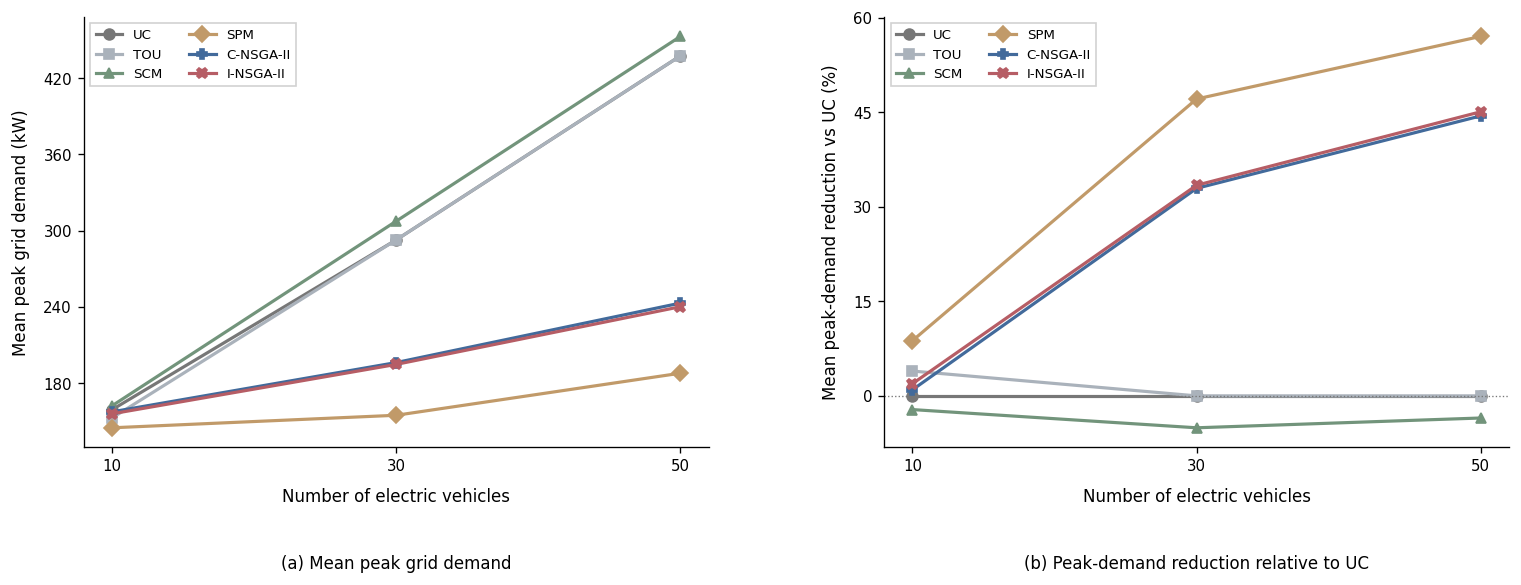


STEP 19D COMPLETED
Figure: /content/drive/MyDrive/IOEV_Ablation_Study/Figures/Step19/Figure19D_Mean_Peak_and_Reduction_vs_UC.jpg
Dimensions: (3800, 1459)
DPI: (300, 300)
Optimization runs performed: 0

I-NSGA-II RESULTS
 ev_count    method  mean_reduction_pct
       10 I-NSGA-II              1.9261
       30 I-NSGA-II             33.4141
       50 I-NSGA-II             45.0737


In [ ]:

# ============================================================
# STEP 19D: MEAN PEAK DEMAND AND REDUCTION VS UC
# ============================================================
# (a) Mean peak grid demand
# (b) Peak-demand reduction relative to UC
#
# Two panels side by side
# Separate legends in upper-left corners
# No grid lines
# Normal-weight panel labels
# JPG, 300 DPI
# No optimization reruns
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from matplotlib.ticker import MaxNLocator

print("=" * 70)
print("STEP 19D: PEAK DEMAND AND REDUCTION VS UC")
print("=" * 70)

# 1. Paths and saved results

ROOT = Path("/content/drive/MyDrive/IOEV_Ablation_Study")

SOURCE = (
    ROOT / "Results" / "Step17_Comparison"
    / "Step17_All_Method_Results.csv"
)

OUTPUT = ROOT / "Figures" / "Step19"
OUTPUT.mkdir(parents=True, exist_ok=True)

if not SOURCE.exists():
    raise FileNotFoundError(SOURCE)

df = pd.read_csv(SOURCE)

# 2. Select methods

EV_COUNTS = [10, 30, 50]

BASELINES = ["UC", "TOU", "SCM", "SPM"]

VARIANTS = [
    "C-NSGA-II",
    "I-NSGA-II"
]

METHODS = BASELINES + VARIANTS

required = {
    "ev_count",
    "run_index",
    "method",
    "selection_policy",
    "peak_kw"
}

missing = required.difference(df.columns)

if missing:
    raise ValueError(
        f"Missing columns: {sorted(missing)}"
    )

# Baselines: original charging schedules
# NSGA-II: balanced Pareto operating points

selected = df.loc[
    (
        df["method"].isin(BASELINES)
        & df["selection_policy"].eq("baseline")
    )
    |
    (
        df["method"].isin(VARIANTS)
        & df["selection_policy"].eq("balanced")
    )
].copy()

# 3. Validate paired observations

expected = pd.MultiIndex.from_product(
    [EV_COUNTS, range(30), METHODS],
    names=["ev_count", "run_index", "method"]
)

actual = pd.MultiIndex.from_frame(
    selected[["ev_count", "run_index", "method"]]
)

if len(selected) != 540:
    raise RuntimeError(
        f"Expected 540 records, found {len(selected)}"
    )

if not actual.is_unique:
    raise RuntimeError("Duplicate observations found.")

if not actual.sort_values().equals(
    expected.sort_values()
):
    raise RuntimeError(
        "Missing or unexpected paired observations."
    )

if not np.isfinite(
    selected["peak_kw"].to_numpy(dtype=float)
).all():
    raise RuntimeError("Invalid peak-demand values.")

# 4. Calculate mean peak demand

peak_summary = (
    selected.groupby(
        ["ev_count", "method"],
        as_index=False
    )
    .agg(
        mean_peak_kw=("peak_kw", "mean"),
        std_peak_kw=("peak_kw", "std")
    )
)

# 5. Calculate paired percentage reduction vs UC

uc = (
    selected[selected["method"].eq("UC")]
    [["ev_count", "run_index", "peak_kw"]]
    .rename(columns={"peak_kw": "uc_peak_kw"})
)

paired = selected.merge(
    uc,
    on=["ev_count", "run_index"],
    how="left",
    validate="many_to_one"
)

if paired["uc_peak_kw"].isna().any():
    raise RuntimeError("Missing UC reference values.")

if (paired["uc_peak_kw"] <= 0).any():
    raise RuntimeError("Invalid UC reference peak.")

paired["peak_reduction_pct"] = (
    100.0
    * (paired["uc_peak_kw"] - paired["peak_kw"])
    / paired["uc_peak_kw"]
)

reduction_summary = (
    paired.groupby(
        ["ev_count", "method"],
        as_index=False
    )
    .agg(
        mean_reduction_pct=(
            "peak_reduction_pct", "mean"
        )
    )
)

# 6. Figure style

COLORS = {
    "UC": "#777777",
    "TOU": "#AAB2BB",
    "SCM": "#72947B",
    "SPM": "#C19A69",
    "C-NSGA-II": "#426A9B",
    "I-NSGA-II": "#B65D65"
}

MARKERS = {
    "UC": "o",
    "TOU": "s",
    "SCM": "^",
    "SPM": "D",
    "C-NSGA-II": "P",
    "I-NSGA-II": "X"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(13.2, 5.2)
)

# ============================================================
# PANEL (a): MEAN PEAK GRID DEMAND
# ============================================================

ax = axes[0]

for method in METHODS:

    subset = (
        peak_summary[
            peak_summary["method"].eq(method)
        ]
        .set_index("ev_count")
        .reindex(EV_COUNTS)
    )

    ax.plot(
        EV_COUNTS,
        subset["mean_peak_kw"],
        marker=MARKERS[method],
        markersize=6.5,
        linewidth=1.9,
        color=COLORS[method],
        label=method
    )

ax.set_xticks(EV_COUNTS)
ax.set_xlabel("Number of electric vehicles", labelpad=8)
ax.set_ylabel("Mean peak grid demand (kW)", labelpad=8)

ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.grid(False)

ax.legend(
    loc="upper left",
    ncol=2,
    fontsize=8,
    frameon=True,
    fancybox=False,
    framealpha=0.95,
    facecolor="white",
    edgecolor="#D0D0D0"
)

ax.text(
    0.5, -0.25,
    "(a) Mean peak grid demand",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    fontweight="normal"
)

# ============================================================
# PANEL (b): PEAK-DEMAND REDUCTION VS UC
# ============================================================

ax = axes[1]

for method in METHODS:

    subset = (
        reduction_summary[
            reduction_summary["method"].eq(method)
        ]
        .set_index("ev_count")
        .reindex(EV_COUNTS)
    )

    ax.plot(
        EV_COUNTS,
        subset["mean_reduction_pct"],
        marker=MARKERS[method],
        markersize=6.5,
        linewidth=1.9,
        color=COLORS[method],
        label=method
    )

ax.axhline(
    0,
    color="#777777",
    linewidth=0.8,
    linestyle=":"
)

ax.set_xticks(EV_COUNTS)
ax.set_xlabel("Number of electric vehicles", labelpad=8)
ax.set_ylabel(
    "Mean peak-demand reduction vs UC (%)",
    labelpad=8
)

ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.grid(False)

ax.legend(
    loc="upper left",
    ncol=2,
    fontsize=8,
    frameon=True,
    fancybox=False,
    framealpha=0.95,
    facecolor="white",
    edgecolor="#D0D0D0"
)

ax.text(
    0.5, -0.25,
    "(b) Peak-demand reduction relative to UC",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    fontweight="normal"
)

# 7. Layout and save

fig.subplots_adjust(
    left=0.085,
    right=0.985,
    top=0.95,
    bottom=0.26,
    wspace=0.28
)

output_file = (
    OUTPUT
    / "Figure19D_Mean_Peak_and_Reduction_vs_UC.jpg"
)

fig.savefig(
    output_file,
    format="jpg",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    pil_kwargs={"quality": 95}
)

plt.show()
plt.close(fig)

# 8. Validate output

with Image.open(output_file) as image:
    dpi = image.info.get("dpi", (0, 0))
    dimensions = image.size

    if min(dpi) < 299:
        raise RuntimeError("DPI validation failed.")

print("\n" + "=" * 70)
print("STEP 19D COMPLETED")
print("=" * 70)
print("Figure:", output_file)
print("Dimensions:", dimensions)
print("DPI:", dpi)
print("Optimization runs performed: 0")

print("\nI-NSGA-II RESULTS")
print(
    reduction_summary[
        reduction_summary["method"].eq("I-NSGA-II")
    ].round(4).to_string(index=False)
)


In [ ]:

# ============================================================
# STEP 20: FINAL EXPERIMENTAL VALIDATION
# AND PUBLICATION RESULTS SUMMARY
# ============================================================
# Project: IOEV Ablation Study
# Target journal: Scientific Reports
#
# Sources: Steps 16, 17 and 18
# No optimization reruns
# No figures
# ============================================================

import json
import time
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone

print("=" * 75)
print("STEP 20: FINAL EXPERIMENTAL VALIDATION")
print("=" * 75)

START = time.perf_counter()

# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

RESULTS = ROOT / "Results"

STEP16 = RESULTS / "Step16_Full_Ablation"
STEP17 = RESULTS / "Step17_Comparison"
STEP18 = RESULTS / "Step18_Statistics"

OUTPUT = RESULTS / "Step20_Final_Validation"

OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

FILES = {
    "individual": STEP16 / "Step16_Individual_Results.csv",
    "pareto": STEP16 / "Step16_Pareto_Solutions.csv",
    "combined": STEP17 / "Step17_All_Method_Results.csv",
    "paired": STEP17 / "Step17_Paired_Baseline_Comparisons.csv",
    "primary": STEP18 / "Step18_Primary_Ablation_Statistics.csv",
    "secondary": STEP18 / "Step18_Secondary_Baseline_Statistics.csv"
}

for name, path in FILES.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {name} file: {path}"
        )

data = {
    name: pd.read_csv(path)
    for name, path in FILES.items()
}

individual = data["individual"]
pareto = data["pareto"]
combined = data["combined"]
paired_saved = data["paired"]
primary = data["primary"]
secondary = data["secondary"]

EV_COUNTS = [10, 30, 50]
RUNS = list(range(30))

BASELINES = ["UC", "TOU", "SCM", "SPM"]

VARIANTS = [
    "C-NSGA-II",
    "IoT-NSGA-II",
    "ISO-IEC-NSGA-II",
    "I-NSGA-II"
]

METHODS = BASELINES + VARIANTS

checks = []

def record_check(name, passed, details=""):
    checks.append({
        "check": name,
        "passed": bool(passed),
        "details": str(details)
    })

    status = "PASS" if passed else "FAIL"
    print(f"{status}: {name}")

    if not passed:
        raise RuntimeError(
            f"Validation failed: {name}. {details}"
        )

# ============================================================
# 2. VERIFY EXPERIMENTAL COVERAGE
# ============================================================

print("\nVALIDATING EXPERIMENTAL COVERAGE")

record_check(
    "Step 16 contains 360 runs",
    len(individual) == 360,
    f"Found {len(individual)}"
)

record_check(
    "Step 17 contains 1440 records",
    len(combined) == 1440,
    f"Found {len(combined)}"
)

record_check(
    "Step 17 contains 4320 paired comparisons",
    len(paired_saved) == 4320,
    f"Found {len(paired_saved)}"
)

record_check(
    "Step 18 contains nine primary tests",
    len(primary) == 9
)

record_check(
    "Step 18 contains 24 secondary tests",
    len(secondary) == 24
)

required_individual = {
    "ev_count", "run_index", "variant",
    "best_actual_peak_kw",
    "best_actual_cost_eur",
    "actual_hypervolume",
    "operational_feasibility_pct"
}

record_check(
    "Step 16 required columns",
    required_individual.issubset(individual.columns),
    sorted(required_individual - set(individual.columns))
)

expected_runs = pd.MultiIndex.from_product(
    [EV_COUNTS, RUNS, VARIANTS],
    names=["ev_count", "run_index", "variant"]
)

actual_runs = pd.MultiIndex.from_frame(
    individual[["ev_count", "run_index", "variant"]]
)

record_check(
    "All 360 unique scenario-variant runs",
    actual_runs.is_unique
    and actual_runs.sort_values().equals(
        expected_runs.sort_values()
    )
)

record_check(
    "Operational feasibility is 100%",
    np.isclose(
        individual["operational_feasibility_pct"]
        .to_numpy(dtype=float),
        100.0
    ).all()
)

# ============================================================
# 3. VERIFY PARETO RECORDS
# ============================================================

print("\nVALIDATING PARETO SOLUTIONS")

pareto_keys = {
    "ev_count", "run_index", "variant",
    "solution_index", "actual_peak_kw",
    "actual_cost_eur"
}

record_check(
    "Pareto solution columns",
    pareto_keys.issubset(pareto.columns),
    sorted(pareto_keys - set(pareto.columns))
)

pareto_counts = (
    pareto.groupby(
        ["ev_count", "run_index", "variant"]
    )
    .size()
    .rename("actual_pareto_size")
    .reset_index()
)

pareto_validation = individual.merge(
    pareto_counts,
    on=["ev_count", "run_index", "variant"],
    how="left",
    validate="one_to_one"
)

record_check(
    "Pareto solution counts match Step 16",
    pareto_validation["actual_pareto_size"].notna().all()
    and np.array_equal(
        pareto_validation["pareto_size"].to_numpy(),
        pareto_validation["actual_pareto_size"].to_numpy()
    )
)

# ============================================================
# 4. VERIFY ABLATION EQUIVALENCE
# ============================================================

print("\nVALIDATING ABLATION EQUIVALENCE")

equivalence_pairs = [
    ("C-NSGA-II", "ISO-IEC-NSGA-II"),
    ("IoT-NSGA-II", "I-NSGA-II")
]

equivalence_rows = []

metrics = [
    "best_actual_peak_kw",
    "best_actual_cost_eur",
    "actual_hypervolume"
]

for first, second in equivalence_pairs:

    a = individual[
        individual["variant"] == first
    ][["ev_count", "run_index"] + metrics]

    b = individual[
        individual["variant"] == second
    ][["ev_count", "run_index"] + metrics]

    matched = a.merge(
        b,
        on=["ev_count", "run_index"],
        suffixes=("_a", "_b"),
        validate="one_to_one"
    )

    record_check(
        f"90 paired runs: {first} vs {second}",
        len(matched) == 90
    )

    for metric in metrics:

        difference = (
            matched[f"{metric}_a"]
            - matched[f"{metric}_b"]
        ).abs()

        max_difference = float(difference.max())

        equivalent = bool(
            np.allclose(
                matched[f"{metric}_a"],
                matched[f"{metric}_b"],
                rtol=0,
                atol=1e-9
            )
        )

        equivalence_rows.append({
            "variant_a": first,
            "variant_b": second,
            "metric": metric,
            "paired_runs": len(matched),
            "max_absolute_difference": max_difference,
            "numerically_equivalent": equivalent
        })

        record_check(
            f"Equivalence: {first} vs {second}, {metric}",
            equivalent,
            f"Maximum difference: {max_difference}"
        )

equivalence_df = pd.DataFrame(
    equivalence_rows
)

# ============================================================
# 5. SELECT COMPARABLE OPERATING POINTS
# ============================================================

print("\nVALIDATING OPERATING POINTS")

required_combined = {
    "ev_count", "run_index", "method",
    "selection_policy", "peak_kw", "cost_eur"
}

record_check(
    "Step 17 required columns",
    required_combined.issubset(combined.columns),
    sorted(required_combined - set(combined.columns))
)

selected = combined.loc[
    (
        combined["method"].isin(BASELINES)
        & combined["selection_policy"].eq("baseline")
    )
    |
    (
        combined["method"].isin(VARIANTS)
        & combined["selection_policy"].eq("balanced")
    )
].copy()

expected_selected = pd.MultiIndex.from_product(
    [EV_COUNTS, RUNS, METHODS],
    names=["ev_count", "run_index", "method"]
)

actual_selected = pd.MultiIndex.from_frame(
    selected[["ev_count", "run_index", "method"]]
)

record_check(
    "720 valid balanced comparison records",
    len(selected) == 720
    and actual_selected.is_unique
    and actual_selected.sort_values().equals(
        expected_selected.sort_values()
    )
)

record_check(
    "Finite performance metrics",
    np.isfinite(
        selected[["peak_kw", "cost_eur"]]
        .to_numpy(dtype=float)
    ).all()
)

# ============================================================
# 6. CALCULATE PUBLICATION PERFORMANCE TABLE
# ============================================================

print("\nCALCULATING PERFORMANCE SUMMARY")

performance = (
    selected.groupby(
        ["ev_count", "method"],
        as_index=False
    )
    .agg(
        independent_runs=("run_index", "nunique"),
        mean_peak_kw=("peak_kw", "mean"),
        std_peak_kw=("peak_kw", "std"),
        mean_cost_eur=("cost_eur", "mean"),
        std_cost_eur=("cost_eur", "std")
    )
)

record_check(
    "30 scenarios per method and population",
    (performance["independent_runs"] == 30).all()
)

# ============================================================
# 7. PAIRED BASELINE IMPROVEMENTS
# ============================================================

print("\nCALCULATING PAIRED BASELINE IMPROVEMENTS")

variant_rows = selected[
    selected["method"].isin(VARIANTS)
].copy()

baseline_rows = selected[
    selected["method"].isin(BASELINES)
].copy()

comparison = variant_rows.merge(
    baseline_rows,
    on=["ev_count", "run_index"],
    suffixes=("_variant", "_baseline"),
    validate="many_to_many"
)

comparison["peak_improvement_kw"] = (
    comparison["peak_kw_baseline"]
    - comparison["peak_kw_variant"]
)

comparison["cost_improvement_eur"] = (
    comparison["cost_eur_baseline"]
    - comparison["cost_eur_variant"]
)

comparison["peak_improvement_pct"] = (
    100 * comparison["peak_improvement_kw"]
    / comparison["peak_kw_baseline"]
)

comparison["cost_improvement_pct"] = (
    100 * comparison["cost_improvement_eur"]
    / comparison["cost_eur_baseline"]
)

comparison_summary = (
    comparison.groupby(
        [
            "ev_count",
            "method_variant",
            "method_baseline"
        ],
        as_index=False
    )
    .agg(
        independent_runs=("run_index", "nunique"),
        mean_peak_improvement_kw=(
            "peak_improvement_kw", "mean"
        ),
        mean_peak_improvement_pct=(
            "peak_improvement_pct", "mean"
        ),
        mean_cost_improvement_eur=(
            "cost_improvement_eur", "mean"
        ),
        mean_cost_improvement_pct=(
            "cost_improvement_pct", "mean"
        )
    )
)

record_check(
    "All paired baseline comparisons",
    len(comparison) == 1440
    and len(comparison_summary) == 48
    and (comparison_summary["independent_runs"] == 30).all()
)

# ============================================================
# 8. STATISTICAL SIGNIFICANCE SUMMARY
# ============================================================

print("\nVALIDATING STATISTICAL RESULTS")

required_stats = {
    "ev_count",
    "metric",
    "mean_improvement",
    "ci95_low",
    "ci95_high",
    "p_holm",
    "significant_0_05"
}

record_check(
    "Primary statistics required columns",
    required_stats.issubset(primary.columns),
    sorted(required_stats - set(primary.columns))
)

record_check(
    "Secondary statistics required columns",
    required_stats.issubset(secondary.columns),
    sorted(required_stats - set(secondary.columns))
)

primary_table = primary.copy()
secondary_table = secondary.copy()

for label, frame in [
    ("Primary", primary_table),
    ("Secondary", secondary_table)
]:

    record_check(
        f"{label} confidence intervals are ordered",
        (
            frame["ci95_low"]
            <= frame["mean_improvement"]
        ).all()
        and (
            frame["mean_improvement"]
            <= frame["ci95_high"]
        ).all()
    )

    record_check(
        f"{label} adjusted p-values are valid",
        frame["p_holm"].between(0, 1).all()
    )

    reported = (
        frame["significant_0_05"]
        .astype(str)
        .str.lower()
        .eq("true")
    )

    calculated = frame["p_holm"] < 0.05

    record_check(
        f"{label} significance flags match Holm p-values",
        reported.eq(calculated).all()
    )

# ============================================================
# 9. COMPACT MANUSCRIPT TABLE
# ============================================================

print("\nPREPARING MANUSCRIPT SUMMARY")

# Retain one representative from each equivalent
# ablation pair, while keeping all baselines.

publication_methods = [
    "UC", "TOU", "SCM", "SPM",
    "C-NSGA-II", "I-NSGA-II"
]

publication_table = performance[
    performance["method"].isin(publication_methods)
].copy()

publication_table = publication_table[
    [
        "ev_count",
        "method",
        "mean_peak_kw",
        "std_peak_kw",
        "mean_cost_eur",
        "std_cost_eur"
    ]
].sort_values(
    ["ev_count", "method"]
)

publication_table = publication_table.round(4)

# ============================================================
# 10. SAVE RESULTS
# ============================================================

outputs = {
    "Step20_Validation_Checks.csv":
        pd.DataFrame(checks),

    "Step20_Performance_Summary.csv":
        performance,

    "Step20_Paired_Improvement_Summary.csv":
        comparison_summary,

    "Step20_Ablation_Equivalence.csv":
        equivalence_df,

    "Step20_Primary_Statistical_Summary.csv":
        primary_table,

    "Step20_Secondary_Statistical_Summary.csv":
        secondary_table,

    "Step20_Manuscript_Performance_Table.csv":
        publication_table
}

for filename, frame in outputs.items():

    path = OUTPUT / filename

    frame.to_csv(
        path,
        index=False
    )

    print("Saved:", path)

# ============================================================
# 11. FINAL VALIDATION REPORT
# ============================================================

report = {
    "step": 20,
    "status": "complete",
    "experiment": "IOEV_Ablation_Study",
    "total_optimization_runs": int(len(individual)),
    "ev_counts": EV_COUNTS,
    "independent_scenarios_per_population": 30,
    "ablation_variants": VARIANTS,
    "baseline_methods": BASELINES,
    "number_of_validation_checks": len(checks),
    "passed_checks": sum(
        item["passed"] for item in checks
    ),
    "failed_checks": sum(
        not item["passed"] for item in checks
    ),
    "new_optimization_runs": 0,
    "completed_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

report_path = (
    OUTPUT / "Step20_Validation_Report.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        report,
        file,
        indent=2
    )

# ============================================================
# 12. DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 75)
print("MANUSCRIPT PERFORMANCE TABLE")
print("=" * 75)

print(
    publication_table.to_string(index=False)
)

print("\n" + "=" * 75)
print("PRIMARY ABLATION STATISTICS")
print("=" * 75)

print(
    primary_table[
        [
            "ev_count",
            "metric",
            "mean_improvement",
            "ci95_low",
            "ci95_high",
            "p_holm",
            "significant_0_05"
        ]
    ].round(5).to_string(index=False)
)

print("\n" + "=" * 75)
print("FINAL VALIDATION SUMMARY")
print("=" * 75)

print("Total checks:", len(checks))
print("Passed:", report["passed_checks"])
print("Failed:", report["failed_checks"])
print("Optimization runs performed: 0")

print(
    "Execution time (seconds):",
    round(time.perf_counter() - START, 3)
)

print("\nResults directory:")
print(OUTPUT)

print("\nSTEP 20 COMPLETED SUCCESSFULLY")


STEP 20: FINAL EXPERIMENTAL VALIDATION

VALIDATING EXPERIMENTAL COVERAGE
PASS: Step 16 contains 360 runs
PASS: Step 17 contains 1440 records
PASS: Step 17 contains 4320 paired comparisons
PASS: Step 18 contains nine primary tests
PASS: Step 18 contains 24 secondary tests
PASS: Step 16 required columns
PASS: All 360 unique scenario-variant runs
PASS: Operational feasibility is 100%

VALIDATING PARETO SOLUTIONS
PASS: Pareto solution columns
PASS: Pareto solution counts match Step 16

VALIDATING ABLATION EQUIVALENCE
PASS: 90 paired runs: C-NSGA-II vs ISO-IEC-NSGA-II
PASS: Equivalence: C-NSGA-II vs ISO-IEC-NSGA-II, best_actual_peak_kw
PASS: Equivalence: C-NSGA-II vs ISO-IEC-NSGA-II, best_actual_cost_eur
PASS: Equivalence: C-NSGA-II vs ISO-IEC-NSGA-II, actual_hypervolume
PASS: 90 paired runs: IoT-NSGA-II vs I-NSGA-II
PASS: Equivalence: IoT-NSGA-II vs I-NSGA-II, best_actual_peak_kw
PASS: Equivalence: IoT-NSGA-II vs I-NSGA-II, best_actual_cost_eur
PASS: Equivalence: IoT-NSGA-II vs I-NSGA-II, 